# The AI Maturity Ladder: Five Form Factors, One Mortgage Application

Climb from a plain chatbot to an autonomous agent that writes and runs its own code, one rung at a time. Every rung works on the same job, deciding mortgage applications at **Acme Home Loans**, a fictional lender. You see what each form factor adds, which limitation sends you up to the next rung, and how the application's **memory** grows and changes on the way.

## The plan: five form factors at a glance

A *form factor* is the shape an AI application takes: how much of the flow the model controls, which data it can reach, and what it can change. This notebook builds one mortgage operation five times. Each rung adds one capability and one kind of memory.

| # | Form factor | What it does at Acme Home Loans | Who controls the flow | New capability | Memory it adds |
|---|---|---|---|---|---|
| 1 | **Chatbot** | Answers an applicant's general mortgage questions | You, one call per turn | Generate text | **Short-term memory**: the conversation buffer, a Python list lost on restart |
| 2 | **RAG** | Answers from Acme's own lending policy | You: retrieve, then generate | Grounding in your data (Oracle AI Database) | **Semantic memory**: a knowledge base of Acme's policy in Oracle, updated in place with versions |
| 3 | **Workflow** | Reads an emailed application, measures it, **decides it with the Clef decision model**, explains and records the decision | Your code: fixed steps | Structured output and a decision model | **Episodic memory**: one application row and one decision row per run |
| 4 | **Agent** | Re-assesses a returning applicant and files a case note | The model: it picks the tools | Model-chosen tool calls through MCP | **Session memory**: its own conversations, resumable and forkable, kept in Oracle; plus **episodic** case notes |
| 5 | **Autonomous agent** | Builds a batch pre-screen tool, then reuses it on new batches | The model: it writes and runs code | Files and a shell, in a sandbox | **Procedural memory**: a tool and its README on disk |

Read the ladder from the bottom: each rung keeps everything below it.

### Memory types you will meet on the way

Building the five form factors also introduces the common types of memory an AI application uses. Each rung adds one, and the notebook names it where it first appears:

| Memory type | What it holds | Where you meet it | Where it lives here |
|---|---|---|---|
| **Short-term (working) memory** | What the model can see right now: the current conversation | Part 1, the chatbot's message list | A Python list, resent every turn |
| **Semantic memory** | Facts about the domain that hold whoever asks: a **knowledge base** | Part 2, Acme's lending policy, read by RAG | `POLICY_DOCS` in Oracle, with versions |
| **Episodic memory** | Records of specific events: what happened, to whom, when | Part 3, every application and decision; Part 4, the agent's case notes and its stored conversations | `LOAN_APPLICATIONS`, `LOAN_DECISIONS`, `CASE_NOTES` and session transcripts, in Oracle |
| **Session memory** | One conversation's full transcript, which the agent can continue, resume or fork | Part 4, Agent SDK sessions | Session files, mirrored to `AGENT_SESSION_ENTRIES` |
| **Procedural memory** | How to do a job: tools, scripts and their instructions | Part 5, the pre-screen tool and its README | Files on disk |

Look for the **🧠 Memory type** note at the start of each Part.

![The five form factors, each with the memory it adds](img/ladder.png)

<details>
<summary>Mermaid source</summary>

```mermaid
%%{init: {"flowchart": {"wrappingWidth": 900}}}%%
flowchart BT
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    R1["<b>① CHATBOT</b> · Claude answers an applicant's questions<br/><i>short-term memory: the conversation buffer, a Python list lost on restart</i>"]:::llm
    R2["<b>② RAG</b> · answers come from Acme's lending policy in Oracle<br/><i>semantic memory: the policy knowledge base, updated in place with versions</i>"]:::db
    R3["<b>③ WORKFLOW</b> · Clef approves or declines; code fixes the steps<br/><i>episodic memory: one application row and one decision row per run</i>"]:::dm
    R4["<b>④ AGENT</b> · re-assesses a returning applicant with tools it picks<br/><i>session + episodic memory: resumable sessions in Oracle, case notes it writes</i>"]:::tool
    R5["<b>⑤ AUTONOMOUS AGENT</b> · builds a pre-screen CLI and reuses it<br/><i>procedural memory: the tool and its README on disk</i>"]:::risk
    R1 ==>|"+ your data"| R2 ==>|"+ fixed steps and a decision model"| R3 ==>|"+ model-chosen tools"| R4 ==>|"+ files and a shell"| R5
```

</details>

> 💡 **Key Insight — Add one capability at a time:** each rung differs from the one below it by a *single* new power. Naming that difference tells you the simplest form factor that solves your problem. Reaching for an autonomous agent when RAG would do is the most common, and most expensive, mistake in applied AI.

This taxonomy follows Anthropic's guidance in [*Building Effective Agents*](https://www.anthropic.com/research/building-effective-agents): start simple, and add autonomy only when the task needs it.

## How to use this notebook

| Part | Form factor | What you build |
|---|---|---|
| 0 | Setup | Dependencies, API key, smoke test, and the memory ledger |
| 1 | Chatbot | One call; memory by resending the conversation; the ceiling of a chatbot |
| 2 | RAG on Oracle AI Database | An HNSW graph built by hand; keyword, vector, filtered, hybrid and graph retrieval; reranking for accuracy; grounded answers; a policy update |
| 3 | Workflow | Extract → measure → decide with Clef → gate → explain → review → record |
| 4 | Agent | Tools over MCP; session memory (multi-turn, resume, fork); sessions stored in Oracle |
| 5 | Autonomous agent | Builds, runs and fixes a pre-screen CLI in a sandbox; a later session reuses it |
| 6 | Where to next? | Choosing the simplest form factor; the full memory ledger |

### ⭐ Live path

The notebook runs top to bottom in about fifteen minutes, plus one-time downloads of the reranker (about 0.6 GB, §2.7) and the decision model (6 GB, §3.3). To present it live, run Part 0, §2.1–§2.5, the reranker cell of §2.7.1 and the loading cell of §3.3 beforehand, then show the starred sections:

| ⭐ Section | What to show | Minutes | Start a live re-run at |
|---|---|---|---|
| 1.2 Memory by resending | The correction is appended, not applied; input tokens climb every turn | 3 | 1.2 |
| 1.3 Ceiling of a chatbot | A bare model cannot know Acme's DTI limit | 2 | 1.3 |
| 2.6.2 Vector search | A paraphrase with no policy words finds the DTI policy | 2 | 2.6 (helpers), then 2.6.2 |
| 2.7 Rerank the candidates | A cross-encoder moves the right section from 5th to 1st; accuracy with and without reranking | 3 | 2.6 (helpers), then 2.7 |
| 2.8 Augment, then generate | The chatbot's failed question, answered with a citation | 2 | 2.8 |
| 2.9 Update the policy memory | A bulletin changes the DTI limit; the next answer cites version 2 | 3 | 2.9 |
| 3.3 Decide with Clef | One forward pass returns probabilities for the decision and every criterion | 3 | 3.3 (after loading) |
| 3.8 Orchestrate | Three applications: approve, decline, refer; each one recorded | 4 | 3.8 |
| 4.2 Run the agent | The agent reads Jordan's history, re-assesses, and files a note | 4 | 4.1 |
| 4.3 Session memory | Resume answers from the session; a fork leaves the original untouched | 4 | 4.3 |
| 5.3 Turn it loose | The builder writes, runs and fixes `prescreen.py` | 5 | 5.1 |
| 5.5 Procedural memory | A new session reuses the tool under a new policy | 3 | 5.5 |

## Use case and scenario

You are the AI engineer at **Acme Home Loans**, a fictional mortgage lender. Applicants ask questions, email their applications, come back after paying off debts, and arrive in batches from brokers. Acme's lending policy lives in seventeen short written sections: a debt-to-income (DTI) limit, loan-to-value (LTV) limits, a minimum credit score, cash reserves, required documents, fair-lending rules and more. The policy changes from time to time.

The same operation grows one rung at a time:

1. A **chatbot** answers general mortgage questions, and cannot know Acme's limits.
2. **RAG** grounds answers in Acme's policy, stored in Oracle AI Database, and picks up a policy change the moment it is written.
3. A **workflow** decides an emailed application. Claude reads the email, Python measures it, the open-source **Clef** decision model approves or declines it against the written policy, and Claude writes the letter. Every decision is recorded.
4. An **agent** handles a returning applicant: it reads the history, re-assesses with the decision model and files a note, choosing those steps itself. Its own conversation is a session it can resume or fork.
5. An **autonomous agent** writes a pre-screen command-line tool for broker batches. A later session reuses that tool under a newer policy.

Acme Home Loans, its policy and every applicant are invented. Real credit decisions are regulated, so the workflow keeps a human-review gate, states specific reasons for every decline, and records each decision with the policy versions it used.

Your role is the engineer deciding how much machinery the job needs. The goal is not to make everything agentic. It is to stop at the simplest reliable form factor, and to know what each one remembers.

## What you will learn

- Call Claude for a single response and a multi-turn conversation with the `anthropic` SDK
- Ground answers in your own data with retrieval on **Oracle AI Database**: keyword, vector, attribute filtering (pre / in / post), hybrid (RRF) and graph
- Improve retrieval accuracy with a **reranker**, an open cross-encoder from Hugging Face, and measure the pipeline with and without it
- Update knowledge in place, with versions, and watch the next answer change
- Build a code-controlled **workflow** that uses an LLM for language and a **decision model** for the decision
- Build an **agent** with the Claude Agent SDK that chooses its own tools, and use its **sessions**: multi-turn, resume, fork, and a `SessionStore` that keeps transcripts in Oracle
- Let an agent **build automation** in a sandbox, and reuse it later as procedural memory
- Recognise the common memory types (short-term, semantic, episodic, session, procedural): which one each form factor adds, where it lives, and how it changes

## The stack used here

| Stack layer | Provider / component | What it does in this notebook |
|---|---|---|
| **Language model** | **Claude Haiku 5.5** (`claude-haiku-5-5`) via the `anthropic` Messages API | The latest and lowest-cost Claude model ($0.10 / $0.50 per million input / output tokens). Answers questions, extracts applications, writes and reviews letters, and runs both agents. |
| **Decision model** | **Clef-Flash** by Cloudflare (Apache-2.0), in 4-bit, running locally (MLX on Apple Silicon, PyTorch on an NVIDIA GPU) | Turns an application plus a schema of typed questions into a probability for every allowed answer, in one forward pass. |
| **Embedding model** | **FastEmbed** with `nomic-ai/nomic-embed-text-v1.5` | Turns policy sections and questions into 768-dimensional vectors locally. |
| **Reranker** | **`BAAI/bge-reranker-v2-m3`** (Apache-2.0) from Hugging Face, int8 ONNX build through FastEmbed, running locally | Reads the question and each candidate policy section together and re-orders the candidates before they reach Claude (§2.7). |
| **Memory store** | **Oracle AI Database** | Holds policy text, vectors, JSON rules, versions, the policy graph, applications, decisions, case notes and agent session transcripts. Runs keyword, vector, filtered, hybrid and graph retrieval in SQL. |
| **Workflow control** | **Python** + Claude structured outputs | Owns the fixed extract → measure → decide → gate → explain → review → record sequence. |
| **Agent runtime** | **Claude Agent SDK** | Runs the model-controlled tool loop and keeps each conversation as a session. |
| **Tool interface** | In-process **MCP** server | Exposes the lender tools (policy search, case history, re-assessment, case notes) through explicit schemas and an allowlist. |
| **Autonomous execution** | Agent SDK `Read`, `Write`, `Edit`, `Bash` in a sandbox | Lets the builder create, run, debug and document a reusable CLI without touching files outside its folder. |

### Reference architecture

Every component this notebook uses, and how they connect:

![Reference architecture for all five form factors](img/reference_architecture.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    NB["Python notebook · Acme Home Loans"]:::app
    subgraph MODELS["MODELS"]
        direction LR
        CL["Claude Haiku 5.5<br/>Anthropic Messages API"]:::llm
        FE["FastEmbed<br/>nomic-embed-text-v1.5 · 768-d"]:::code
        DM["Clef-Flash decision model<br/>Apache-2.0 · MLX 4-bit · local"]:::dm
    end
    subgraph AGENTS["AGENT RUNTIME"]
        direction LR
        SDK["Claude Agent SDK<br/>loop + hooks + OS sandbox"]:::tool
        MCP["in-process MCP server<br/>lender tools"]:::tool
    end
    subgraph ORA["ORACLE AI DATABASE · VECTOR schema"]
        direction LR
        PD[("POLICY_DOCS<br/>VECTOR(768) · JSON rules")]:::db
        IX["Oracle Text + HNSW<br/>POLICY_GRAPH"]:::db
        PV[("POLICY_DOC_VERSIONS")]:::mem
        LA[("LOAN_APPLICATIONS<br/>LOAN_DECISIONS")]:::mem
        CN[("CASE_NOTES<br/>AGENT_SESSION_ENTRIES")]:::mem
    end
    subgraph BOX["SANDBOX · ff5_sandbox/"]
        direction LR
        PJ["policy.json<br/>applications_*.csv"]:::code
        PS["prescreen.py<br/>README.md"]:::risk
    end
    NB -->|"① ② ③ calls"| MODELS
    NB -->|"④ ⑤ runs"| AGENTS
    AGENTS -->|"model + decisions"| MODELS
    MODELS -->|"vectors"| ORA
    AGENTS -->|"tools read / write"| ORA
    AGENTS -->|"⑤ builds in"| BOX
    PD -. "export rules" .-> PJ
    style MODELS fill:#07040d,stroke:#7c3aed,color:#c4b5fd
    style AGENTS fill:#02060d,stroke:#1d4ed8,color:#93c5fd
    style ORA fill:#020a05,stroke:#047857,color:#6ee7b7
    style BOX fill:#0d0205,stroke:#be123c,color:#fda4af
```

</details>

# Part 0 · Setup

## 0.1 · Install the dependencies

> **Note:** The cell below installs only what this kernel is missing, so the shared `part7/.venv` environment takes the fast path.
>
> **`fastembed`** runs the embedding model, and the reranker in §2.7, through ONNX, with no PyTorch. The **Clef** decision model in Part 3 runs locally: through **MLX** on an Apple Silicon Mac with at least 16 GB of memory, or with **PyTorch** on an NVIDIA GPU with 16 GB (quantized to 4-bit as it loads). Anywhere else, point `CLEF_URL` at a SystemOne endpoint serving Clef (§3.3 explains the options).

In [1]:
import importlib.util
import platform
import shutil
import subprocess
import sys

# Install only what this kernel is missing. A prepared environment takes the
# fast no-op path; a fresh kernel remains self-bootstrapping.
requirements = {
    "anthropic": "anthropic>=0.107",
    "oracledb": "oracledb>=3.4",
    "fastembed": "fastembed>=0.8",
    "pandas": "pandas>=2.0",
    "numpy": "numpy>=1.26",
    "claude_agent_sdk": "claude-agent-sdk>=0.2.168",
    "nest_asyncio": "nest-asyncio>=1.6",
    "dotenv": "python-dotenv>=1.0",
    "requests": "requests>=2.31",
    "huggingface_hub": "huggingface_hub>=0.30",
    "matplotlib": "matplotlib>=3.8",
}
# The Clef decision model runs locally: through MLX on Apple Silicon, or with PyTorch on an NVIDIA GPU.
APPLE_SILICON = platform.system() == "Darwin" and platform.machine() == "arm64"
NVIDIA_GPU = not APPLE_SILICON and shutil.which("nvidia-smi") is not None
if APPLE_SILICON:
    requirements["mlx_vlm"] = "mlx-vlm>=0.7.4,<0.8"
elif NVIDIA_GPU:
    requirements.update({"torch": "torch>=2.6", "transformers": "transformers>=5.10.2", "accelerate": "accelerate>=1.0",
                         "bitsandbytes": "bitsandbytes>=0.45", "PIL": "pillow>=10.0"})

missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Notebook dependencies ready ✓",
      "(Clef will run locally through MLX)" if APPLE_SILICON else
      "(Clef will run on the NVIDIA GPU, in 4-bit)" if NVIDIA_GPU else "(set CLEF_URL for the decision model in §3.3)")

Notebook dependencies ready ✓ (Clef will run locally through MLX)


## 0.2 · Configure API access

Every Claude call authenticates with one environment variable, `ANTHROPIC_API_KEY`. Both the `anthropic` SDK and the `claude-agent-sdk` read it. Set it in your shell or a `.env` file, or run the next cell, which prompts for it with `getpass` when it is missing.

| Setting | Default | Why |
|---|---|---|
| `MODEL` | `claude-haiku-5-5` | The latest and lowest-cost Claude model. Override with `AIML_MODEL`. |
| `MAX_TOKENS` | `2048` | Caps generated tokens. Haiku 5.5 thinks before it answers, and thinking counts toward this cap. |
| `EFFORT` | `low` | How much the model thinks. Every task here is short, so `low` keeps answers fast and cheap. Override with `AIML_EFFORT`. |

Haiku 5.5 accepts no `temperature`, `top_p` or `top_k` settings and no assistant prefill: you steer it with the prompt, structured outputs and `effort`.

In [2]:
import getpass
import os
from pathlib import Path

import anthropic
from dotenv import load_dotenv

# Shell/CI variables win. When running from notebook/, these optional files are
# loaded from most specific to least specific without overwriting the process.
for candidate in (Path("../appbook/.env"), Path("../.env"), Path("../../.env"), Path(".env")):
    if candidate.exists():
        load_dotenv(candidate, override=False)

if not os.environ.get("ANTHROPIC_API_KEY"):
    os.environ["ANTHROPIC_API_KEY"] = getpass.getpass("Enter your ANTHROPIC_API_KEY: ")

# One model string serves the Messages API and the Claude Agent SDK.
MODEL = os.environ.get("AIML_MODEL", "claude-haiku-5-5")
MAX_TOKENS = int(os.environ.get("AIML_MAX_TOKENS", "2048"))
EFFORT = os.environ.get("AIML_EFFORT", "low")

client = anthropic.Anthropic()
print(f"Anthropic client ready ✓  model={MODEL}  effort={EFFORT}")

Anthropic client ready ✓  model=claude-haiku-5-5  effort=low


## 0.3 · Smoke-test the client

One round trip confirms the key and introduces the shape of every Claude call: `model`, `max_tokens`, an optional `system` prompt, `output_config`, and a list of `messages`.

A response is a list of typed blocks. Haiku 5.5 can open with a `thinking` block before the answer, so never read `response.content[0]` as the answer. `text_of` joins the text blocks, and we reuse it everywhere.

**What to watch:** the block types printed first, then one sentence from Claude.

In [3]:
def text_of(response) -> str:
    """Join the text blocks of a Claude response (it can also hold thinking and tool-use blocks)."""
    return "".join(block.text for block in response.content if block.type == "text")


response = client.messages.create(
    model=MODEL,
    max_tokens=MAX_TOKENS,
    output_config={"effort": EFFORT},
    system="You are a concise, friendly assistant.",
    messages=[{"role": "user", "content": "In one sentence, what is a mortgage?"}],
)
print("block types:", [block.type for block in response.content])
print(text_of(response))

block types: ['text']
A mortgage is a loan used to buy real estate, where the property itself serves as collateral that the lender can claim if the borrower fails to repay.


## 0.4 · The memory ledger

Memory is the thread through this notebook. Each form factor remembers something different, in a different place, and changes it in a different way. `memory_ledger()` lists every memory store the notebook has created so far, with its current size. We call it at the end of each Part and watch it grow.

It inspects what exists: the chatbot's history list once Part 1 creates it, the Oracle tables once Parts 2–4 create them, the agent's session files, and the sandbox tool from Part 5.

**What to watch:** right now the ledger is empty, because nothing has been remembered yet.

In [4]:
import pandas as pd

# (table, form factor, what it remembers, kind of memory, how it changes)
ORACLE_MEMORY = [
    ("POLICY_DOCS", "② RAG", "Acme's lending policy: text, embedding, JSON rules", "semantic", "updated in place, version + 1"),
    ("POLICY_DOC_VERSIONS", "② RAG", "every superseded policy version", "semantic history", "one row per policy update"),
    ("LOAN_APPLICATIONS", "③ workflow", "applications as structured facts", "episodic", "one row per application; facts corrected in place"),
    ("LOAN_DECISIONS", "③ workflow, ④ agent", "decisions, probabilities, policy versions used", "episodic", "appended; never overwritten"),
    ("CASE_NOTES", "④ agent", "notes the agent chose to write", "episodic", "written by the model through a tool"),
    ("AGENT_SESSION_ENTRIES", "④ agent, ⑤ autonomous", "agent session transcripts (sessions)", "session", "mirrored every turn by a SessionStore"),
]


def memory_ledger():
    """Every memory store this notebook has created so far, with its current size."""
    rows = []
    if "bot" in globals():
        rows.append({"form factor": "① chatbot", "memory": "conversation buffer (messages)", "kind": "short-term",
                     "lives in": "Python list in this process", "items": len(bot.history),
                     "changes by": "append every turn; lost on restart"})
    if "conn" in globals():
        with conn.cursor() as cur:
            cur.execute("SELECT table_name FROM user_tables")
            existing = {name for (name,) in cur.fetchall()}
            for table, form_factor, what, kind, how in ORACLE_MEMORY:
                if table not in existing:
                    continue
                if table == "AGENT_SESSION_ENTRIES":
                    cur.execute("SELECT COUNT(DISTINCT session_id) FROM agent_session_entries")
                else:
                    cur.execute(f"SELECT COUNT(*) FROM {table}")
                rows.append({"form factor": form_factor, "memory": what, "kind": kind,
                             "lives in": f"Oracle · {table}", "items": cur.fetchone()[0], "changes by": how})
    if "AGENT_CWD" in globals():
        local_sessions = list_sessions(directory=AGENT_CWD)
        rows.append({"form factor": "④ agent", "memory": "agent session transcripts (local)", "kind": "session",
                     "lives in": "~/.claude/projects/<cwd>/*.jsonl", "items": len(local_sessions),
                     "changes by": "the SDK appends every turn"})
    if "SANDBOX" in globals() and (SANDBOX / "prescreen.py").exists():
        tools = [p.name for p in (SANDBOX / "prescreen.py", SANDBOX / "README.md") if p.exists()]
        rows.append({"form factor": "⑤ autonomous", "memory": "a reusable tool and how to run it", "kind": "procedural",
                     "lives in": f"files: {', '.join(tools)}", "items": len(tools),
                     "changes by": "written once by the builder; reused by later sessions"})
    return pd.DataFrame(rows) if rows else "No memory yet: nothing has been stored."


memory_ledger()

'No memory yet: nothing has been stored.'

# Part 1 · Form Factor 1 — The Chatbot

> 💡 **Key Term — LLM (Large Language Model):** a model trained to predict text. On its own it has no memory between calls, no access to your data, and no ability to act. It maps a prompt to a response.

> 🧠 **Memory type — short-term (working) memory:** what the model can see right now. Here it is the conversation itself, a Python list the app resends on every turn.

The simplest useful thing you can build: an applicant asks a question, Claude answers. No database, no tools, no retrieval. This is where almost every AI project starts.

### Reference architecture

![Form Factor 1 reference architecture](img/ff1_chatbot.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    U["Applicant"]:::user --> APP["Chatbot app<br/>send(message)"]:::app
    APP <-->|"append user + assistant turns"| H[("history: list[dict]<br/>short-term memory")]:::mem
    APP -->|"system prompt + ENTIRE history"| API["Anthropic Messages API"]:::llm
    API --> C["Claude Haiku 5.5<br/>stateless between calls"]:::llm
    C -->|"reply"| APP
    APP -->|"reply"| U
    H -. "lost when the process stops" .-> X["∅"]:::risk
```

</details>

> **Boundary:** the application owns the conversation list. Claude stays stateless and has never seen Acme's policy.

## 1.1 · A single prompt in, a single response out

`ask_claude` wraps one `messages.create` call. That is the whole chatbot. It passes five arguments:

| Argument | Value here | Why it matters |
|---|---|---|
| `model` | `MODEL` | Selects the Claude model; one variable keeps the notebook configurable. |
| `max_tokens` | `MAX_TOKENS` | Caps generated tokens, thinking included. It does **not** limit the input. |
| `output_config` | `{"effort": EFFORT}` | How hard the model thinks before answering. |
| `system` | `system` | The standing role and behaviour, separate from the user turns. |
| `messages` | one user message | The ordered conversation turns; this first example sends exactly one. |

In [5]:
def ask_claude(question: str, system: str = "You are a helpful mortgage assistant.") -> str:
    """Form Factor 1: a single prompt in, a single response out. Nothing else."""
    response = client.messages.create(
        model=MODEL,
        max_tokens=MAX_TOKENS,
        output_config={"effort": EFFORT},
        system=system,
        messages=[{"role": "user", "content": question}],
    )
    return text_of(response)


print(ask_claude("In two sentences, what is a debt-to-income ratio?"))

A debt-to-income ratio (DTI) is the percentage of a person's gross monthly income that goes toward paying monthly debt obligations, such as mortgage or rent, car loans, credit card minimums, and student loans. Lenders use it to gauge a borrower's ability to take on and repay additional debt, such as a mortgage.


## 1.2 · ⭐ Adding memory by resending the conversation

The API is **stateless**: Claude remembers nothing between calls. A chatbot feels like it remembers only because *we* resend the full conversation on every turn.

> 💡 **Key Term — Statelessness:** each request is independent. To hold a conversation you keep the `messages` list yourself and send all of it every time. The model's "memory" is whatever you put back in front of it.

> 💡 **This is the most naive form of memory.** Nothing is stored or retrieved selectively: the application keeps every prior message in a Python list and sends the whole list again. Token cost and latency grow every turn, the history disappears with the process, and a correction cannot replace the fact it corrects: it is only appended after it.

The `Chatbot` class keeps that list:

- **`send(user_message)`** appends the user's message to `history`, sends the *entire* history, appends the reply, and returns it.
- **`self.history.append({...})`** is where the memory grows: two entries per turn, one `user` and one `assistant`.
- **`self.input_tokens`** records what each turn cost to send (`response.usage.input_tokens`), so we can watch the cost of this memory climb.

![Chatbot turn sequence, including a correction](img/ff1_turns.png)

<details>
<summary>Mermaid source</summary>

```mermaid
sequenceDiagram
    autonumber
    participant U as Applicant
    participant A as Chatbot app
    participant H as history list
    participant C as Claude
    U->>A: I'm Maya, I earn $8,500 a month
    A->>H: append user turn
    A->>C: system + history (1 turn)
    C-->>A: reply
    A->>H: append assistant turn
    U->>A: What do I earn?
    A->>C: system + history (3 turns)
    C-->>A: $8,500 a month
    U->>A: Correction: I earn $9,200
    A->>H: append — the old $8,500 is still there
    U->>A: Which income will you use?
    A->>C: system + history (7 turns, both incomes)
    C-->>A: $9,200 (the model resolves the conflict)
    Note over A,C: The buffer only grows. Every turn resends all of it,<br/>so input tokens climb and nothing is corrected in place.
```

</details>

In [6]:
class Chatbot:
    """A multi-turn chatbot. Its 'memory' is a growing list of messages we resend every turn."""

    def __init__(self, system: str = "You are a helpful mortgage assistant. Keep answers under 80 words."):
        self.system = system
        self.history: list[dict] = []
        self.input_tokens: list[int] = []  # what each turn cost to send

    def send(self, user_message: str) -> str:
        self.history.append({"role": "user", "content": user_message})
        response = client.messages.create(
            model=MODEL,
            max_tokens=MAX_TOKENS,
            output_config={"effort": EFFORT},
            system=self.system,
            messages=self.history,  # the entire conversation, every time
        )
        reply = text_of(response)
        self.history.append({"role": "assistant", "content": reply})  # the memory grows here
        self.input_tokens.append(response.usage.input_tokens)
        return reply

Turn 1 introduces Maya, an applicant. The bot stores both her message and its reply in `history`.

**What to watch:** in Turn 2 Claude recalls Maya's name and income only because Turn 1 is still in `bot.history`.

In [7]:
bot = Chatbot()
print("Turn 1:", bot.send("Hi! I'm Maya Patel. I earn $8,500 a month and I'm looking at a $420,000 home."))

Turn 1: Hi Maya! Nice to meet you. At $8,500/month, the common 28% guideline suggests a total housing payment around $2,380. For a $420,000 home with 20% down ($84,000), a 30-year loan at about 6.5% would be roughly $2,120/month in principal and interest, before taxes and insurance. To refine this, could you share your down payment, monthly debts, and approximate credit score?


In [8]:
print("Turn 2:", bot.send("What's my name, and what monthly income did I give you?"))

Turn 2: Your name is Maya Patel, and you told me you earn $8,500 a month.


Now Maya corrects a fact. A real memory would *replace* the old income. This buffer can only append, so both incomes now sit in the history and the model has to work out which one is current.

**What to watch:** Turn 4 uses $9,200, yet the next cell, which shows the memory itself, still holds the $8,500 message. The input tokens grow on every turn because the whole buffer is resent.

In [9]:
print("Turn 3:", bot.send("Correction: my income is actually $9,200 a month, not $8,500."))
print("\nTurn 4:", bot.send("Which monthly income will you use for me now, and why?"))

Turn 3: Thanks for the correction, Maya. At $9,200/month, the 28% guideline gives a total housing payment of about $2,576. For the $420,000 home with 20% down, the principal and interest payment (30-year, ~6.5%) stays around $2,120/month, before taxes and insurance. Would you like me to factor in your monthly debts next?



Turn 4: I'll use $9,200/month, the corrected figure you gave me. Lenders base affordability on your current, verified income, so the most recent number you provide replaces the earlier one. I'll confirm it against pay stubs or tax documents if you move forward.


In [10]:
print("Input tokens sent per turn:", bot.input_tokens)  # the whole buffer is resent, so this only grows
pd.DataFrame(bot.history).assign(content=lambda d: d["content"].str[:90])  # the memory itself: both incomes are still in it

Input tokens sent per turn: [73, 226, 279, 412]


,role,content
0,user,"Hi! I'm Maya Patel. I earn $8,500 a month and ..."
1,assistant,"Hi Maya! Nice to meet you. At $8,500/month, th..."
2,user,"What's my name, and what monthly income did I ..."
3,assistant,"Your name is Maya Patel, and you told me you e..."
4,user,"Correction: my income is actually $9,200 a mon..."
5,assistant,"Thanks for the correction, Maya. At $9,200/mon..."
6,user,"Which monthly income will you use for me now, ..."
7,assistant,"I'll use $9,200/month, the corrected figure yo..."


> 💡 **Teachable moment:** the answer is right, but the memory is not: the wrong income is still stored and will be resent forever. Every later form factor stores memory somewhere it can be **updated** (Part 2), **recorded** (Part 3), **chosen** by the model (Part 4) and **reused** as a tool (Part 5).

To chat yourself, call the loop below.

In [11]:
def chat_session():
    """Interactive REPL-style chat. Type 'exit' to stop."""
    session = Chatbot()
    print("Chatting with Claude — type 'exit' to quit.\n")
    while True:
        user = input("You: ")
        if user.strip().lower() in {"exit", "quit"}:
            break
        print("Claude:", session.send(user), "\n")


# Uncomment to try it (uses input()):
# chat_session()

## 1.3 · ⭐ The ceiling of a chatbot

A chatbot can only use what it learned in training. Ask about *your* business, a policy it has never seen, and it cannot know.

**What to watch:** Claude hedges or gives industry ranges instead of Acme's numbers. It has never seen Acme's policy.

In [12]:
print(ask_claude(
    "What is Acme Home Loans' maximum debt-to-income ratio, and how many months of "
    "cash reserves must I keep after closing on an investment property?"
))

I don't have any information about Acme Home Loans' specific underwriting guidelines, so I can't give you their exact maximum debt-to-income (DTI) ratio or cash reserve requirements. Those figures vary by lender and by loan program, and I don't want to guess and give you a number that could affect your planning.

Here's how to get a reliable answer:

- **Ask Acme directly.** A loan officer can give you the current DTI limits and reserve requirements for the specific product you're considering, such as conventional, FHA, or a portfolio loan.
- **Check the lender's published guidelines.** Many lenders post their program matrices or underwriting guides on their websites.
- **Request a written loan estimate or term sheet.** It should list the requirements that apply to your scenario.

For general context, these are common industry ranges, though your lender's rules may differ:

- **DTI:** Conventional loans often cap total DTI around 45–50%, sometimes higher with strong compensating factor

> 💡 **Key Insight — The data gap:** Claude has never seen Acme's lending policy, so the best it can do is explain the gap; the worst is a confident guess. A bigger model does not fix this. Giving the model the relevant policy at question time does, and that is the next rung: RAG.

### Memory so far

**What to watch:** one row, the conversation buffer, living in this Python process.

In [13]:
memory_ledger()

,form factor,memory,kind,lives in,items,changes by
0,① chatbot,conversation buffer (messages),short-term,Python list in this process,8,append every turn; lost on restart


> ### 📌 Key Takeaways — Form Factor 1
> - A chatbot is **one stateless `messages.create` call**: prompt in, text out. Read the answer by block type, because the model may think first.
> - Its memory is **short-term**, the **conversation buffer**: the whole history resent every turn. It costs more each turn, vanishes on restart, and a correction is appended rather than applied.
> - Its ceiling: **no access to your data** and knowledge frozen at training time, which motivates every rung above.

# Part 2 · Form Factor 2 — Retrieval-Augmented Generation (RAG)

> 💡 **Key Term — RAG (Retrieval-Augmented Generation):** first *retrieve* the passages relevant to a question, then hand them to the LLM with the question. The model answers from real, current data instead of its training alone.

> 🧠 **Memory type — semantic memory:** facts about the domain that stay true whoever asks and whenever: Acme's limits, the documents it requires, how it estimates a payment. A **knowledge base** like this policy is the most common form of semantic memory, and RAG is how a model reads it at question time: it retrieves the facts a question needs instead of having to know them.

This time the knowledge lives in a real database. We store Acme's seventeen policy sections in **Oracle AI Database** with native `VECTOR` embeddings, and work through the retrieval techniques Oracle supports: **keyword**, **vector**, **attribute filtering** (pre / in / post), **hybrid** (keyword + vector) and **graph**, then add a **reranker** that re-orders the candidates for accuracy (§2.7). Retrieval quality is the biggest lever on RAG quality, so it is worth seeing the options side by side and measuring them.

This Part also adds the first memory that can be **updated**: when Acme changes its policy (§2.9), we rewrite one section in place, keep the old version, and the very next answer reflects the change.

### Reference architecture

![Form Factor 2 reference architecture](img/ff2_rag.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    Q["Applicant question"]:::user --> APP["RAG app"]:::app
    APP --> QE["FastEmbed<br/>query vector"]:::code
    APP --> KW["keyword terms"]:::code
    subgraph ORA["ORACLE AI DATABASE · semantic memory"]
        direction LR
        PD[("POLICY_DOCS<br/>17 policy sections")]:::db
        V["HNSW vector index"]:::db
        T["Oracle Text index"]:::db
        G["POLICY_GRAPH<br/>similar_to · in_category"]:::db
        PD --- V & T & G
    end
    QE --> V
    KW --> T
    V & T & G --> CAND["top-8 candidates<br/>vector · keyword · hybrid · graph"]:::code
    CAND --> RR["RERANKER · bge-reranker-v2-m3<br/>cross-encoder from Hugging Face<br/>reads question + section together"]:::dm
    RR --> K["top-k policy passages<br/>re-ordered, numbered for citation"]:::code
    K --> P["grounded prompt"]:::app --> C["Claude Haiku 5.5"]:::llm --> ANS["answer with [n] citations"]:::user
    style ORA fill:#020a05,stroke:#047857,color:#6ee7b7
```

</details>

Retrieval runs in two stages: Oracle casts a wide, fast net (the techniques in §2.6), and a **reranker** reads each candidate against the question to put the best ones first (§2.7).

> **Boundary:** retrieval supplies trusted facts, but the application still hard-codes the retrieve → rerank → generate path.

> 💡 **Key Term — Converged database:** Oracle AI Database stores relational rows, JSON, full-text indexes, vectors and graphs in one engine. Keyword search, semantic search, filtered and hybrid combinations and graph traversals are all SQL against one set of tables.

## 2.1 · Start and connect to Oracle AI Database

### Start the database (Docker)

This Part needs a running Oracle AI Database. The repo ships a one-command starter, **`oracle.sh`**, in the `part7/` folder, so every notebook **and** appbook share one database. It is built on the [`gvenzl/oracle-free`](https://hub.docker.com/r/gvenzl/oracle-free) image (Oracle AI Database 26ai Free).

**Prerequisite:** [Docker](https://docs.docker.com/get-docker/) installed and running.

From a terminal, in the `part7/` folder (two levels up from this notebook):

```bash
./oracle.sh start
```

…or from a notebook cell: `!../../oracle.sh start`. The first run pulls the image (~2 GB) and creates the database, so give it a few minutes. It is idempotent; `status`, `logs`, `sql`, `stop` and `remove` manage it.

The script provisions exactly what this notebook relies on:

| What it sets up | Used by |
|---|---|
| A `VECTOR` user at `localhost:1521/FREEPDB1` | the connection in §2.1 |
| **Oracle Text** (`CTXSYS.CONTEXT` index) | keyword and hybrid search, §2.6.1 and §2.6.4 |
| **AI Vector Search** memory pool | the HNSW vector index, §2.4 and §2.6.3 |
| **`CREATE PROPERTY GRAPH`** privilege | graph retrieval, §2.6.5 |

> **Already have an Oracle AI Database?** Skip the script and make sure a `VECTOR` user is reachable at `localhost:1521/FREEPDB1`, or override `ORACLE_USER` / `ORACLE_PASSWORD` / `ORACLE_DSN`, which the next cell reads.

<details>
<summary><b>Prefer to run Docker by hand, without the script?</b></summary>

```bash
docker run -d --name acme-oracle-free \
  -p 1521:1521 \
  -e ORACLE_PASSWORD=OraclePwd_2025 \
  -e APP_USER=VECTOR \
  -e APP_USER_PASSWORD=VectorPwd_2025 \
  -v acme-oracle-data:/opt/oracle/oradata \
  gvenzl/oracle-free:23
```

Once the container is healthy, grant the extras (vector pool and property graph), then restart so the vector pool activates:

```bash
docker exec -i acme-oracle-free sqlplus -S / as sysdba <<'SQL'
ALTER SYSTEM SET vector_memory_size = 512M SCOPE=SPFILE;
ALTER SESSION SET CONTAINER = FREEPDB1;
GRANT CREATE SESSION, RESOURCE, CREATE VIEW, CREATE PROPERTY GRAPH, CTXAPP TO VECTOR;
ALTER USER VECTOR QUOTA UNLIMITED ON USERS;
SQL
docker restart acme-oracle-free
```

</details>

### Connect from Python

A small retry helper, then we keep the connection in `conn` for the rest of the notebook.

> **No Docker?** Some hosted notebook images ship Oracle Database Free built in, under `~/.oracle-free` (the same `gvenzl/oracle-free` database `oracle.sh` runs, unpacked to run as an ordinary user). When it is there, the cell below starts it first, so the Docker step above is not needed.

In [14]:
import subprocess
import sys
import time
from pathlib import Path

import oracledb


def connect_to_oracle(max_retries=3, retry_delay=5):
    """Connect to the local Oracle AI Database, retrying a few times while it starts."""
    user = os.environ.get("ORACLE_USER", "VECTOR")
    password = os.environ.get("ORACLE_PASSWORD", "VectorPwd_2025")
    dsn = os.environ.get("ORACLE_DSN", "localhost:1521/FREEPDB1")
    for attempt in range(1, max_retries + 1):
        try:
            print(f"Connection attempt {attempt}/{max_retries}...")
            conn = oracledb.connect(user=user, password=password, dsn=dsn)
            with conn.cursor() as cur:
                cur.execute("SELECT banner FROM v$version WHERE banner LIKE 'Oracle%'")
                print("Connected:", cur.fetchone()[0])
            return conn
        except oracledb.OperationalError as e:
            print(f"Attempt {attempt} failed: {e}")
            if attempt < max_retries:
                time.sleep(retry_delay)
            else:
                raise



# A notebook image with Oracle Database Free built in (no Docker): make sure it is running.
BUILT_IN_ORACLE = Path.home() / ".oracle-free" / "oracle_free.py"
if BUILT_IN_ORACLE.exists():
    subprocess.run([sys.executable, str(BUILT_IN_ORACLE), "start", "--wait"], check=False)

conn = connect_to_oracle()

Connection attempt 1/3...
Connected: Oracle AI Database 26ai Free Release 23.26.2.0.0 - Develop, Learn, and Run for Free


## 2.2 · The knowledge base: Acme's lending policy

Seventeen short policy sections across eight categories (affordability, collateral, credit, eligibility, documentation, compliance, process, products). Each becomes one row in Oracle. This knowledge base is the application's **semantic memory**: every later rung reads it.

| Field | Role | Example |
|---|---|---|
| `doc_id` | Stable unique key, the table's `PRIMARY KEY` | `"dti_limit"` |
| `title` | Human-readable name, embedded with the body | `"Debt-to-Income (DTI) Limit"` |
| `category` | A small controlled vocabulary; drives attribute filtering and graph edges | `"affordability"` |
| `content` | The policy text people read | `"Acme Home Loans caps the debt-to-income (DTI) ratio at 41%…"` |
| `rules` | The same limit as machine-readable JSON, or `None` | `{"max_dti": 0.41}` |

The `rules` field matters later: the workflow (Part 3) and the autonomous agent's tool (Part 5) read limits from it, so one memory serves people (the text) and programs (the JSON). An `embedding` (768 numbers) is computed from `title + content` in §2.3. The policy is **synthetic**: short, self-consistent sections written for this notebook.

In [15]:
POLICY_DOCS = [
    {"doc_id": "dti_limit", "title": "Debt-to-Income (DTI) Limit", "category": "affordability",
     "rules": {"max_dti": 0.41},
     "content": "Acme Home Loans caps the debt-to-income (DTI) ratio at 41%. DTI is all monthly debt payments, "
                "including the new mortgage payment of principal, interest, property tax and insurance (PITI), "
                "divided by gross monthly income. Applications above the limit are declined."},
    {"doc_id": "payment_estimate", "title": "How We Estimate the Mortgage Payment", "category": "affordability",
     "rules": {"rate": 0.065, "term_months": 360, "tax_insurance_rate_annual": 0.015},
     "content": "For affordability checks the monthly payment (PITI) is estimated at a 6.5% fixed rate over 30 "
                "years, plus property tax and homeowner's insurance of 1.5% of the property value per year."},
    {"doc_id": "reserves", "title": "Cash Reserves After Closing", "category": "affordability",
     "rules": {"min_reserve_months": {"primary": 2, "second_home": 2, "investment": 6}},
     "content": "After the down payment and closing costs, borrowers must hold liquid reserves worth at least two"
                " months of the new mortgage payment (PITI), or six months for an investment property."},
    {"doc_id": "ltv_limit", "title": "Loan-to-Value (LTV) Limits", "category": "collateral",
     "rules": {"max_ltv": {"primary": 0.95, "second_home": 0.85, "investment": 0.75}},
     "content": "The loan-to-value (LTV) ratio is the loan amount divided by the lower of the purchase price and "
                "the appraised value. Maximum LTV is 95% for a primary residence, 85% for a second home and 75% "
                "for an investment property."},
    {"doc_id": "pmi", "title": "Private Mortgage Insurance (PMI)", "category": "collateral",
     "rules": None,
     "content": "Any loan with an LTV above 80% requires private mortgage insurance (PMI). PMI is removed "
                "automatically once the balance reaches 78% of the original property value."},
    {"doc_id": "property_types", "title": "Eligible Property Types", "category": "collateral",
     "rules": None,
     "content": "Eligible properties are single-family homes, warrantable condominiums and two-to-four unit "
                "homes. Manufactured homes on leased land and mixed-use commercial properties are not eligible."},
    {"doc_id": "appraisal", "title": "Appraisal Requirement", "category": "collateral",
     "rules": None,
     "content": "Every purchase needs an independent appraisal ordered through Acme Home Loans. If the appraised "
                "value comes in below the purchase price, LTV is calculated on the appraised value."},
    {"doc_id": "credit_score", "title": "Minimum Credit Score", "category": "credit",
     "rules": {"min_credit_score": 640},
     "content": "Acme Home Loans requires a minimum credit score of 640, using the middle of the three bureau "
                "scores. Applications below 640 are declined."},
    {"doc_id": "bankruptcy", "title": "Bankruptcy and Foreclosure Waiting Periods", "category": "credit",
     "rules": None,
     "content": "A Chapter 7 bankruptcy must have been discharged at least four years before the application "
                "date, and a foreclosure completed at least seven years before."},
    {"doc_id": "employment", "title": "Employment History", "category": "eligibility",
     "rules": {"min_employment_months": 24},
     "content": "Borrowers need 24 months of continuous employment or self-employment income. A gap longer than "
                "six months needs a written explanation. Self-employed borrowers qualify on the 24-month average "
                "of net business income from their tax returns."},
    {"doc_id": "documents", "title": "Required Documents", "category": "documentation",
     "rules": None,
     "content": "A complete application includes government photo ID, the two most recent pay stubs, W-2 forms "
                "for the last two years (or two years of tax returns if self-employed), and the two most recent "
                "bank statements for every account used for the down payment or reserves."},
    {"doc_id": "fair_lending", "title": "Fair Lending", "category": "compliance",
     "rules": None,
     "content": "Credit decisions must never consider race, color, religion, national origin, sex, marital "
                "status, age, or the receipt of public assistance income. Every applicant is assessed on the same"
                " written criteria."},
    {"doc_id": "adverse_action", "title": "Adverse Action Notices", "category": "compliance",
     "rules": None,
     "content": "When an application is declined, the applicant receives an adverse action notice within 30 days "
                "that states up to four specific principal reasons for the decision. Vague reasons such as 'did "
                "not meet our criteria' are not allowed."},
    {"doc_id": "human_review", "title": "Automated Decisions and Human Review", "category": "process",
     "rules": {"confidence_floor": 0.8, "borderline_margin": 0.01},
     "content": "An automated decision is final only when the decision model's confidence is at least 0.80 and no"
                " ratio is within one percentage point of its limit. Every other application is referred to a "
                "human underwriter."},
    {"doc_id": "timelines", "title": "Processing Timelines", "category": "process",
     "rules": None,
     "content": "Pre-approval decisions are returned within two business days. Full underwriting takes up to ten "
                "business days after every required document is received."},
    {"doc_id": "products", "title": "Loan Products", "category": "products",
     "rules": None,
     "content": "Acme Home Loans offers 30-year fixed, 15-year fixed and 7/6 adjustable-rate mortgages. The "
                "minimum down payment is 5% for a primary residence."},
    {"doc_id": "rate_lock", "title": "Rate Locks", "category": "products",
     "rules": None,
     "content": "Interest rates can be locked for 45 days once an application is complete. One 15-day extension "
                "is available for a fee of 0.125% of the loan amount."},
]
print(len(POLICY_DOCS), "policy sections,", sum(d["rules"] is not None for d in POLICY_DOCS), "with machine-readable rules.")

17 policy sections, 7 with machine-readable rules.


## 2.3 · Embed the documents

> 💡 **Key Term — Embedding:** a numeric vector that captures the meaning of text. Texts with similar meaning get nearby vectors, so we can search by *meaning* rather than exact words.

We use `nomic-embed-text-v1.5` via **fastembed** (ONNX, no PyTorch). It is *asymmetric*: documents and queries get different prefixes, which fastembed applies for us (`embed()` for documents, `query_embed()` for queries).

**Why normalize?** `_unit` divides each vector by its length, so cosine similarity becomes a plain dot product and only direction (meaning) matters. Oracle's `VECTOR_DISTANCE(..., COSINE)` normalizes too; this keeps our own client-side math, such as the graph edges in §2.6.5, clean.

> **Note:** the first call downloads the model (a few hundred MB).

In [16]:
import numpy as np
from fastembed import TextEmbedding

embedder = TextEmbedding(model_name="nomic-ai/nomic-embed-text-v1.5")


def _unit(v):
    """Normalize to a unit vector so cosine similarity is a plain dot product."""
    v = np.asarray(v, dtype=np.float32)
    n = np.linalg.norm(v)
    return v / n if n else v


def doc_text(doc: dict) -> str:
    """What we embed for a policy section: its title and its text, as one sentence-like string."""
    return f"{doc['title']}. {doc['content']}"


doc_vectors = np.array([_unit(v) for v in embedder.embed([doc_text(d) for d in POLICY_DOCS])], dtype=np.float32)
dim = int(doc_vectors.shape[1])
print(f"Embedded {len(POLICY_DOCS)} policy sections at dimension {dim}.")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Embedded 17 policy sections at dimension 768.


**Why embed the title and the content together?** One text becomes one vector, so everything a section should be findable by has to be in that text. The title carries dense keywords ("Debt-to-Income (DTI) Limit"); the content carries the detail that paraphrased questions match. Fields we only filter on, like `category`, stay ordinary columns.

In [17]:
pd.DataFrame({
    "doc_id": [d["doc_id"] for d in POLICY_DOCS],
    "category": [d["category"] for d in POLICY_DOCS],
    "text sent to embedder": [doc_text(d)[:70] + "…" for d in POLICY_DOCS],
    "embedding preview": [np.array2string(v[:5], precision=4, separator=", ") + " …" for v in doc_vectors],
    "dimensions": [len(v) for v in doc_vectors],
}).head()

,doc_id,category,text sent to embedder,embedding preview,dimensions
0,dti_limit,affordability,Debt-to-Income (DTI) Limit. Acme Home Loans ca...,"[ 0.0323, 0.0638, -0.1811, -0.0239, -0.0164] …",768
1,payment_estimate,affordability,How We Estimate the Mortgage Payment. For affo...,"[ 0.0809, 0.0408, -0.1829, -0.0148, 0.0044] …",768
2,reserves,affordability,Cash Reserves After Closing. After the down pa...,"[ 0.0964, 0.0269, -0.1839, -0.0351, 0.0082] …",768
3,ltv_limit,collateral,Loan-to-Value (LTV) Limits. The loan-to-value ...,"[ 0.0559, 0.0635, -0.1898, -0.0462, 0.0228] …",768
4,pmi,collateral,Private Mortgage Insurance (PMI). Any loan wit...,"[ 0.0643, 0.0246, -0.1671, -0.0092, -0.0102] …",768


## 2.4 · Create the tables

`POLICY_DOCS` stores each section with a native `JSON` column for its rules, a `VERSION` counter, an `UPDATED_AT` timestamp and a `VECTOR(dim, FLOAT32)` column. `POLICY_DOC_VERSIONS` will hold every superseded version, so an update never destroys history (§2.9). The DDL drops any earlier copy first, so the cell is safe to re-run.

> ⚠️ **The `VECTOR` dimension must match your embedding model.** The column is declared with `dim`, read from the model in §2.3 (`768` here). Declare `VECTOR(512, ...)` while the model emits 768 numbers and **every insert fails** with a dimension mismatch.

In [18]:
import array
import json

policy_ddl = f"""
BEGIN EXECUTE IMMEDIATE 'DROP TABLE policy_doc_versions PURGE';
EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
BEGIN EXECUTE IMMEDIATE 'DROP TABLE policy_docs CASCADE CONSTRAINTS PURGE';
EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
CREATE TABLE policy_docs (
    doc_id     VARCHAR2(64) PRIMARY KEY,
    title      VARCHAR2(400),
    category   VARCHAR2(64),
    content    VARCHAR2(4000),
    rules      JSON,
    version    NUMBER DEFAULT 1 NOT NULL,
    updated_at TIMESTAMP WITH TIME ZONE DEFAULT SYSTIMESTAMP NOT NULL,
    embedding  VECTOR({dim}, FLOAT32)
)
/
CREATE TABLE policy_doc_versions (
    doc_id        VARCHAR2(64),
    version       NUMBER,
    title         VARCHAR2(400),
    category      VARCHAR2(64),
    content       VARCHAR2(4000),
    rules         JSON,
    valid_from    TIMESTAMP WITH TIME ZONE,
    valid_to      TIMESTAMP WITH TIME ZONE DEFAULT SYSTIMESTAMP,
    change_reason VARCHAR2(400),
    CONSTRAINT pk_policy_doc_versions PRIMARY KEY (doc_id, version)
)
"""
with conn.cursor() as cur:
    for stmt in policy_ddl.split("/"):
        if stmt.strip():
            cur.execute(stmt)
conn.commit()
print(f"Tables POLICY_DOCS (VECTOR dim={dim}) and POLICY_DOC_VERSIONS created.")

Tables POLICY_DOCS (VECTOR dim=768) and POLICY_DOC_VERSIONS created.


### Add the indexes

Two indexes power the retrieval techniques that follow:

| Index | Type | Powers |
|---|---|---|
| `policy_text_idx` | Oracle Text (`CTXSYS.CONTEXT`) | keyword and hybrid search (`CONTAINS`) |
| `policy_vec_idx` | Vector (HNSW) | approximate search and the pre/in/post filter hints in §2.6.3 |

#### What is HNSW?

**HNSW, Hierarchical Navigable Small World**, is the graph-based vector index that makes similarity search fast. Instead of comparing the query with *every* row (an exact `O(n)` scan), it pre-builds a layered graph in which each vector links to a handful of near neighbours:

- **Upper layers are sparse**: few nodes, long links, for big jumps across the space.
- **Lower layers are dense**: many nodes, short links, for fine local search.

A query enters at the top, greedily hops to the closest neighbour, drops a layer and repeats, zooming in on the nearest neighbours at the bottom. The result is **approximate** nearest-neighbour search in roughly `O(log n)`: it can occasionally miss a true neighbour, and that trade-off is tunable. After the index is created, we build a small HNSW graph by hand and draw it.

#### The SQL that builds it

```sql
CREATE VECTOR INDEX policy_vec_idx ON policy_docs(embedding)
  ORGANIZATION INMEMORY NEIGHBOR GRAPH        -- an HNSW graph in the in-memory vector pool
  DISTANCE COSINE WITH TARGET ACCURACY 90     -- distance metric + recall target (drives ef at query time)
  PARAMETERS (TYPE HNSW, NEIGHBORS 16, EFCONSTRUCTION 200);
```

| HNSW concept | Oracle keyword | Applies at | Controls |
|---|---|---|---|
| **`m`**, max connections per node | `NEIGHBORS` | build time | graph density: more paths and recall, more memory |
| **`efConstruction`** | `EFCONSTRUCTION` | build time | candidates weighed while wiring each node: graph quality vs. build time |
| **`efSearch`** | derived from `TARGET ACCURACY` | every query | candidates kept in play while searching: recall vs. latency |

> 🎛️ **Rule of thumb:** `m` and `efConstruction` set the recall *ceiling* when you build; `efSearch` (through `TARGET ACCURACY`) decides how close to that ceiling each query gets.

> 💡 **Key Term — HNSW index:** on a seventeen-row table an exact scan is already instant, so the index is here to demonstrate the pattern and to enable the filter hints. The cell tolerates a database whose vector pool is not configured.

In [19]:
with conn.cursor() as cur:
    # Full-text index: required for keyword (CONTAINS) and hybrid search.
    try:
        cur.execute("DROP INDEX policy_text_idx")
    except oracledb.DatabaseError:
        pass
    cur.execute("""
        CREATE INDEX policy_text_idx ON policy_docs(content)
        INDEXTYPE IS CTXSYS.CONTEXT PARAMETERS ('SYNC (ON COMMIT)')
    """)
    print("Oracle Text index created (keyword search ready).")

    # HNSW vector index: approximate search and the pre/in/post filter hints.
    try:
        cur.execute("DROP INDEX policy_vec_idx")
    except oracledb.DatabaseError:
        pass
    try:
        cur.execute("""
            CREATE VECTOR INDEX policy_vec_idx ON policy_docs(embedding)
            ORGANIZATION INMEMORY NEIGHBOR GRAPH
            DISTANCE COSINE WITH TARGET ACCURACY 90
            PARAMETERS (TYPE HNSW, NEIGHBORS 16, EFCONSTRUCTION 200)
        """)
        print("HNSW vector index created.")
    except oracledb.DatabaseError as e:
        print("HNSW index skipped (exact search still works):", str(e).splitlines()[0][:90])
conn.commit()

Oracle Text index created (keyword search ready).
HNSW vector index created.


#### See it: an HNSW graph, built by hand

Oracle keeps its HNSW graph inside the vector memory pool, out of sight. To see what that structure looks like, we build a small one ourselves, about fifty lines of Python with the same three parameters, and ingest the policy one sentence at a time.

**Building** (`insert`), for each new vector:

1. **Draw a level** `ℓ = ⌊−ln(U) · mL⌋` with `U` uniform in (0, 1] and `mL = 1 / ln(m)`. About one node in `m` reaches layer 1, one in `m²` layer 2, and so on: that is why upper layers are sparse.
2. **Descend greedily** from the entry point through every layer above `ℓ`, one hop at a time towards the new vector.
3. **On each layer from `ℓ` down to 0**, run a beam search that keeps **`efConstruction`** candidates, link the new node to the `m` closest, and let any neighbour that now has too many links (`m`, or `2m` on layer 0) keep only its closest ones.

**Searching** (`search`): the same greedy descent to layer 0, then one beam search that keeps **`efSearch`** candidates and returns the best `k`.

`distance_calls` counts every distance computed, the work an index exists to save.

In [20]:
import heapq
import math
import random


class TinyHNSW:
    """A minimal HNSW index over unit vectors (cosine distance), built one vector at a time."""

    def __init__(self, m: int = 4, ef_construction: int = 32, seed: int = 7):
        self.m, self.m0, self.ef_construction = m, 2 * m, ef_construction
        self.mL = 1 / math.log(m) if m > 1 else 1.0  # level multiplier
        self.rng = random.Random(seed)
        self.vectors, self.levels, self.links = [], [], []  # links[node][layer] = that node's neighbours
        self.entry, self.distance_calls = None, 0

    def dist(self, q, node) -> float:
        self.distance_calls += 1
        return 1.0 - float(q @ self.vectors[node])

    def search_layer(self, q, entries, ef, layer, seen=None):
        """Beam search on one layer: keep the ef closest nodes found, expand the closest unexpanded one."""
        visited = set(entries)
        candidates = [(self.dist(q, e), e) for e in entries]
        heapq.heapify(candidates)
        best = [(-d, e) for d, e in candidates]  # a max-heap of the ef best so far
        heapq.heapify(best)
        while candidates:
            d, c = heapq.heappop(candidates)
            if d > -best[0][0]:
                break  # nothing left can improve the beam
            for n in self.links[c][layer] - visited:
                visited.add(n)
                dn = self.dist(q, n)
                if len(best) < ef or dn < -best[0][0]:
                    heapq.heappush(candidates, (dn, n))
                    heapq.heappush(best, (-dn, n))
                    if len(best) > ef:
                        heapq.heappop(best)
        if seen is not None:
            seen.setdefault(layer, set()).update(visited)
        return sorted((-d, e) for d, e in best)

    def insert(self, v):
        node = len(self.vectors)
        self.vectors.append(v)
        level = int(-math.log(1 - self.rng.random()) * self.mL)  # 1. draw a level
        self.levels.append(level)
        self.links.append([set() for _ in range(level + 1)])
        if self.entry is None:
            self.entry = node
            return
        top, ep = self.levels[self.entry], [self.entry]
        for layer in range(top, level, -1):  # 2. greedy descent above the node's level
            ep = [self.search_layer(v, ep, 1, layer)[0][1]]
        for layer in range(min(level, top), -1, -1):  # 3. link on every layer the node lives on
            found = self.search_layer(v, ep, self.ef_construction, layer)
            cap = self.m0 if layer == 0 else self.m
            for _, n in found[: self.m]:
                self.links[node][layer].add(n)
                self.links[n][layer].add(node)
                if len(self.links[n][layer]) > cap:  # an over-full neighbour keeps its closest links
                    closest = sorted(self.links[n][layer], key=lambda x: self.dist(self.vectors[n], x))[:cap]
                    self.links[n][layer] = set(closest)
            ep = [e for _, e in found]
        if level > top:
            self.entry = node

    def search(self, q, k: int = 3, ef_search: int = 8):
        """Greedy descent to layer 0, then a beam of ef_search. Returns the top k and the route taken."""
        hops, ep = [], self.entry
        for layer in range(self.levels[self.entry], 0, -1):
            nxt = self.search_layer(q, [ep], 1, layer)[0][1]
            hops.append((layer, ep, nxt))
            ep = nxt
        seen = {}
        found = self.search_layer(q, [ep], max(ef_search, k), 0, seen)
        return [n for _, n in found[:k]], {"hops": hops, "start0": ep, "visited0": seen[0]}

**Ingest the policy, one sentence at a time.** Each section splits into sentences, each sentence gets the same 768-dimensional embedding the table uses, and `insert` wires it into the graph.

**What to watch:** most sentences live only on layer 0; a handful also reach layer 1, and one or two reach the top, where the entry point sits.

In [21]:
import re

sentences = [(d["category"], s) for d in POLICY_DOCS for s in re.split(r"(?<=[.!?])\s+", d["content"])]
sentence_vectors = np.array([_unit(v) for v in embedder.embed([s for _, s in sentences])])

hnsw = TinyHNSW(m=4, ef_construction=32)
for v in sentence_vectors:
    hnsw.insert(v)

layers = max(hnsw.levels) + 1
print(f"{len(sentences)} sentences ingested · {hnsw.distance_calls} distances computed while building")
for layer in range(layers - 1, -1, -1):
    on = [n for n, lv in enumerate(hnsw.levels) if lv >= layer]
    print(f"  layer {layer}: {len(on):>2} nodes, {sum(len(hnsw.links[n][layer]) for n in on) // 2:>3} links")
print("entry point:", sentences[hnsw.entry][1][:80])

32 sentences ingested · 865 distances computed while building
  layer 2:  2 nodes,   1 links
  layer 1:  5 nodes,  10 links
  layer 0: 32 nodes, 102 links
entry point: A gap longer than six months needs a written explanation.


**Draw every layer and one search.** Each panel is one layer, with the nodes placed by a 2-D projection of their 768-dimensional vectors (so a link can join points that look far apart: they are close in 768 dimensions). The question is the ★.

**What to watch:** the search enters at the top, hops once towards the question per upper layer, then on layer 0 the beam of `efSearch` candidates (amber rings) closes in on the three nearest sentences (thick rings). The `human_review` sentence about automated decisions is among them.

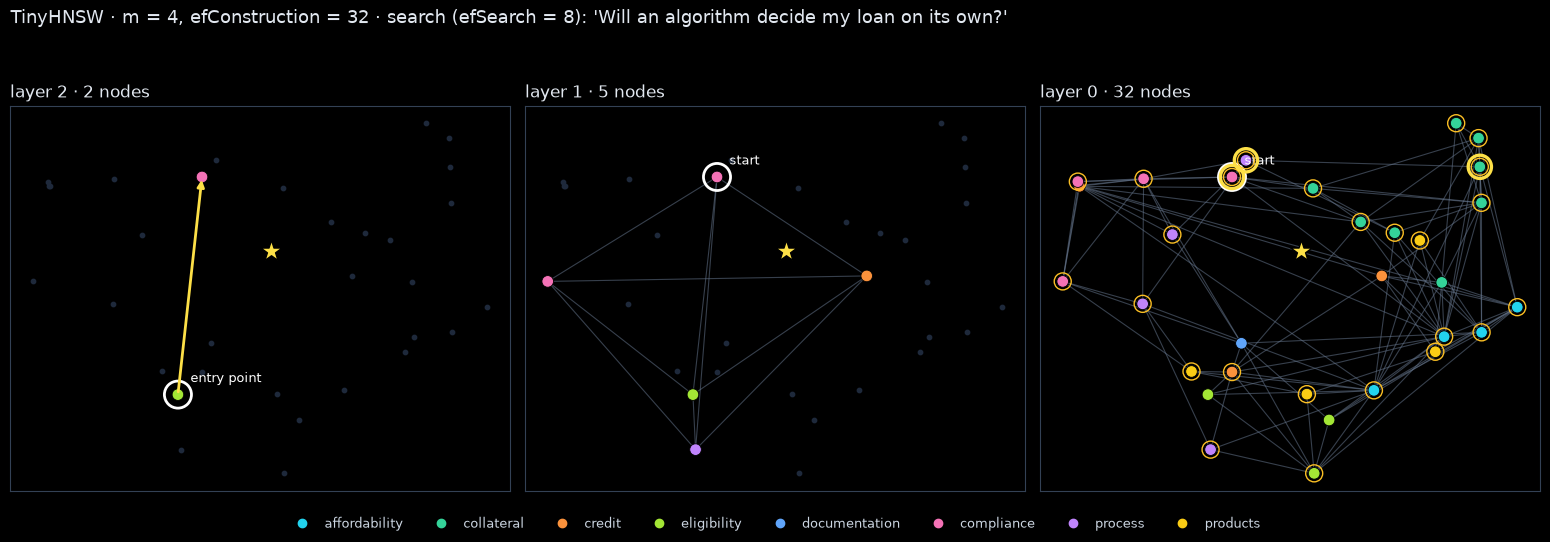

1 [compliance] Credit decisions must never consider race, color, religion, national origin, sex, marital 
2 [process] An automated decision is final only when the decision model's confidence is at least 0.80 
3 [collateral] The loan-to-value (LTV) ratio is the loan amount divided by the lower of the purchase pric


In [22]:
import matplotlib.pyplot as plt

CATEGORY_COLORS = {"affordability": "#22d3ee", "collateral": "#34d399", "credit": "#fb923c", "eligibility": "#a3e635",
                   "documentation": "#60a5fa", "compliance": "#f472b6", "process": "#c084fc", "products": "#facc15"}


def draw_hnsw(index, categories, q=None, k=3, ef_search=8, title=""):
    """One panel per layer, top layer first; optionally the route of one search."""
    X = np.array(index.vectors)
    mu = X.mean(axis=0)
    _, _, vt = np.linalg.svd(X - mu, full_matrices=False)
    P = (X - mu) @ vt[:2].T  # 2-D projection, for drawing only
    if q is not None:
        top, route = index.search(q, k, ef_search)
        qp = (q - mu) @ vt[:2].T
    n_layers = max(index.levels) + 1
    fig, axes = plt.subplots(1, n_layers, figsize=(5.2 * n_layers, 5.4), facecolor="black", squeeze=False)
    for ax, layer in zip(axes[0], range(n_layers - 1, -1, -1)):
        ax.set_facecolor("black"); ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color("#334155")
        on = [n for n, lv in enumerate(index.levels) if lv >= layer]
        drawn = set()
        for n in on:
            for m in index.links[n][layer]:
                if (min(n, m), max(n, m)) not in drawn:
                    drawn.add((min(n, m), max(n, m)))
                    ax.plot(*zip(P[n], P[m]), color="#64748b", lw=0.8, alpha=0.55, zorder=1)
        off = [n for n, lv in enumerate(index.levels) if lv < layer]
        ax.scatter(P[off, 0], P[off, 1], s=10, color="#1e293b", zorder=2)
        ax.scatter(P[on, 0], P[on, 1], s=70, c=[CATEGORY_COLORS[categories[n]] for n in on],
                   edgecolors="black", linewidths=0.6, zorder=3)
        if q is not None:
            ax.scatter(*qp, marker="*", s=260, color="#fde047", edgecolors="black", zorder=6)
            start = next((a for lv, a, _ in route["hops"] if lv == layer), route["start0"] if layer == 0 else None)
            if start is not None:
                ax.scatter(*P[start], s=380, facecolors="none", edgecolors="white", linewidths=2, zorder=4)
                ax.annotate("entry point" if start == index.entry else "start", P[start], xytext=(9, 9),
                            textcoords="offset points", color="white", fontsize=9)
            for lv, a, b in route["hops"]:
                if lv == layer and a != b:
                    ax.annotate("", P[b], P[a], arrowprops=dict(arrowstyle="-|>", color="#fde047", lw=2), zorder=5)
            if layer == 0:
                v = list(route["visited0"])
                ax.scatter(P[v, 0], P[v, 1], s=150, facecolors="none", edgecolors="#fbbf24", linewidths=1, zorder=4)
                ax.scatter(P[top, 0], P[top, 1], s=280, facecolors="none", edgecolors="#fde047", linewidths=2.4, zorder=5)
        ax.set_title(f"layer {layer} · {len(on)} node{'s' if len(on) != 1 else ''}", color="#e2e8f0", fontsize=12, loc="left")
    fig.suptitle(title, color="#e2e8f0", fontsize=13, x=0.01, ha="left")
    handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=name) for name, c in CATEGORY_COLORS.items()]
    fig.legend(handles=handles, loc="lower center", ncol=8, frameon=False, labelcolor="#cbd5e1", fontsize=9)
    fig.tight_layout(rect=(0, 0.06, 1, 0.93))
    plt.show()
    return top if q is not None else None


question = "Will an algorithm decide my loan on its own?"
q_vec = _unit(next(embedder.query_embed(question)))
top = draw_hnsw(hnsw, [c for c, _ in sentences], q_vec, k=3, ef_search=8,
                title=f"TinyHNSW · m = 4, efConstruction = 32 · search (efSearch = 8): {question!r}")
for rank, n in enumerate(top, 1):
    print(rank, f"[{sentences[n][0]}]", sentences[n][1][:90])

**Turn the knobs.** The same sentences, indexed with different settings, searched with twelve applicant questions. **recall@3** compares each search's top three with the exact top three from a full scan.

**What to watch:** a small `m` gives more layers but thin links, and recall drops; a larger `efSearch` buys recall back for a few more distance computations; a larger `efConstruction` weighs more candidates for every link, so building computes more distances, and a larger `m` stores more links per node. Here every search still computes about as many distances as the 32-row scan it replaces: at this size the graph saves nothing. At a million rows a search touches a few thousand, and that is the point of HNSW.

In [23]:
HNSW_QUESTIONS = [
    "Will an algorithm decide my loan on its own?", "How much does it cost to extend a rate lock?",
    "When does PMI come off my loan?", "Which of my three credit bureau scores do you go by?",
    "Do you offer adjustable-rate loans?", "Who orders the valuation of the house?",
    "My foreclosure finished five years ago. Can I apply now?", "What's the most you'll lend on a holiday home?",
    "How long does full underwriting take once I've sent everything?", "Could my age or being divorced count against me?",
    "Is a condo okay to buy with you?", "How much savings must I still have once the sale closes?",
]
question_vectors = np.array([_unit(next(embedder.query_embed(q))) for q in HNSW_QUESTIONS])
exact_top3 = [set(np.argsort(-(sentence_vectors @ q))[:3]) for q in question_vectors]

sweep = []
for m, ef_construction in [(2, 32), (4, 4), (4, 32), (16, 32)]:
    index = TinyHNSW(m=m, ef_construction=ef_construction)
    for v in sentence_vectors:
        index.insert(v)
    build_cost = index.distance_calls
    for ef_search in (3, 8):
        recalls, costs = [], []
        for q, exact in zip(question_vectors, exact_top3):
            index.distance_calls = 0
            found, _ = index.search(q, k=3, ef_search=ef_search)
            recalls.append(len(exact & set(found)) / 3)
            costs.append(index.distance_calls)
        sweep.append({"m (NEIGHBORS)": m, "efConstruction": ef_construction, "efSearch": ef_search,
                      "layers": max(index.levels) + 1,
                      "nodes per layer, top first": [sum(lv >= L for lv in index.levels) for L in range(max(index.levels), -1, -1)],
                      "links per node, layer 0": round(np.mean([len(l[0]) for l in index.links]), 1),
                      "build distances": build_cost, "recall@3": round(float(np.mean(recalls)), 2),
                      "distances per search": round(float(np.mean(costs)), 1)})
pd.DataFrame(sweep)

,m (NEIGHBORS),efConstruction,efSearch,layers,"nodes per layer, top first","links per node, layer 0",build distances,recall@3,distances per search
0,2,32,3,6,"[1, 2, 2, 5, 12, 32]",3.2,858,0.67,23.8
1,2,32,8,6,"[1, 2, 2, 5, 12, 32]",3.2,858,0.92,30.2
2,4,4,3,3,"[2, 5, 32]",6.3,777,1.00,25.5
3,4,4,8,3,"[2, 5, 32]",6.3,777,1.00,31.6
4,4,32,3,3,"[2, 5, 32]",6.4,865,1.00,25.4
5,4,32,8,3,"[2, 5, 32]",6.4,865,1.00,31.8
6,16,32,3,2,"[2, 32]",23.5,521,1.00,33.2
7,16,32,8,2,"[2, 32]",23.5,521,1.00,33.9


> 💡 **Teachable moment — the knobs Oracle exposes are these:** `NEIGHBORS` is `m`, `EFCONSTRUCTION` is `efConstruction`, and `TARGET ACCURACY` sets `efSearch` for you at query time. Oracle's graph is the production version of `TinyHNSW`: the same layers, links and beam search, kept in the vector memory pool. The appbook's **HNSW lab**, on the RAG page, animates this ingestion step by step and lets you change the parameters on a larger set of points, where the savings show.

## 2.5 · Ingest the documents

Each embedding is sent as a Python `array('f', ...)`, which the driver maps onto the `VECTOR` column. Rules go in as JSON text, which Oracle parses into its native `JSON` type. `executemany` inserts the batch in one round trip, and a `COUNT(*)` confirms all seventeen rows landed before we query.

In [24]:
rows = [
    (d["doc_id"], d["title"], d["category"], d["content"],
     json.dumps(d["rules"]) if d["rules"] else None, array.array("f", vec))
    for d, vec in zip(POLICY_DOCS, doc_vectors.astype(np.float32).tolist())
]
with conn.cursor() as cur:
    cur.executemany(
        "INSERT INTO policy_docs (doc_id, title, category, content, rules, embedding) "
        "VALUES (:1, :2, :3, :4, :5, :6)",
        rows,
    )
    conn.commit()
    cur.execute("SELECT COUNT(*), COUNT(rules) FROM policy_docs")
    total, with_rules = cur.fetchone()
print(f"Rows in POLICY_DOCS: {total} ({with_rules} with JSON rules)")

Rows in POLICY_DOCS: 17 (7 with JSON rules)


## 2.6 · Retrieval techniques

> 💡 **Key Insight — No single retrieval strategy wins everywhere.** Keyword search nails exact terms but misses synonyms; vector search captures meaning but can drift; attribute filtering narrows by structured metadata; hybrid search combines keyword and vector; graph retrieval follows relationships. We run each on the same policy.

Four small helpers are shared by every technique:

| Helper | What it does |
|---|---|
| `_query_vec(text)` | Embeds a query as a unit vector (fastembed adds nomic's query prefix). |
| `embed_query(text)` | Returns that vector as `array('f')`, the form the driver binds to a `:q` `VECTOR` parameter. |
| `contains_arg(phrase)` | Makes a phrase safe for Oracle Text `CONTAINS` by quoting multi-word phrases. |
| `show(rows, columns)` | Renders a query result as a DataFrame. |

In [25]:
def _query_vec(text: str):
    """Embed a query as a unit vector (fastembed applies nomic's query prefix internally)."""
    return _unit(next(embedder.query_embed(text)))


def embed_query(text: str):
    """A query vector in Oracle's expected array form (FLOAT32)."""
    return array.array("f", _query_vec(text).astype(np.float32).tolist())


def contains_arg(phrase: str) -> str:
    """Make a phrase safe for Oracle Text CONTAINS (wrap multi-word phrases in quotes)."""
    return f'"{phrase}"' if " " in phrase.strip() else phrase


def show(rows, columns):
    """Render result rows as a DataFrame for easy reading."""
    return pd.DataFrame(rows, columns=columns)

### 2.6.1 · Keyword search (Oracle Text)

Full-text search over `content`. The `CONTAINS(content, ...)` predicate uses the **Oracle Text** index: at index time Oracle tokenizes every section and records which rows contain each term (an **inverted index**); at query time it looks the term up instead of scanning rows.

**`SCORE(1)`** is the relevance score for the `CONTAINS` call labelled `1`, on a 0–100 scale; it rises when the term is more prominent in a row. Keyword search is exact: it only matches words that literally appear.

In [26]:
def keyword_search(query: str, k: int = 5, kw: str | None = None):
    """Oracle Text search. `kw` is an Oracle Text query; by default the whole query, as one phrase."""
    sql = f"""
        SELECT doc_id, title, category, SCORE(1) AS score
        FROM policy_docs
        WHERE CONTAINS(content, :kw, 1) > 0
        ORDER BY SCORE(1) DESC
        FETCH FIRST {int(k)} ROWS ONLY
    """
    with conn.cursor() as cur:
        cur.execute(sql, kw=kw or contains_arg(query))
        return cur.fetchall(), [d[0] for d in cur.description]


rows, cols = keyword_search("PMI")
show(rows, cols)

,DOC_ID,TITLE,CATEGORY,SCORE
0,pmi,Private Mortgage Insurance (PMI),collateral,13


### 2.6.2 · ⭐ Vector search (semantic)

Embed the query with the *same* model as the documents, compute the cosine distance to every stored `embedding` with `VECTOR_DISTANCE(embedding, :q, COSINE)`, and return the closest rows. We report `1 - distance` as a similarity, so **higher means closer in meaning**.

> 💡 **Teachable moment:** the query below never says "debt", "DTI" or "ratio", yet vector search puts the **Debt-to-Income (DTI) Limit** section first. That semantic recall is what keyword search structurally cannot do.

**What to watch:** `dti_limit` ranks first.

In [27]:
def vector_search(query: str, k: int = 5):
    q = embed_query(query)
    sql = f"""
        SELECT doc_id, title, category,
               ROUND(1 - VECTOR_DISTANCE(embedding, :q, COSINE), 4) AS similarity
        FROM policy_docs
        ORDER BY similarity DESC
        FETCH FIRST {int(k)} ROWS ONLY
    """
    with conn.cursor() as cur:
        cur.execute(sql, q=q)
        return cur.fetchall(), [d[0] for d in cur.description]


rows, cols = vector_search("What share of my salary can my monthly bills take up?")
show(rows, cols)

,DOC_ID,TITLE,CATEGORY,SIMILARITY
0,dti_limit,Debt-to-Income (DTI) Limit,affordability,0.5541
1,payment_estimate,How We Estimate the Mortgage Payment,affordability,0.5302
2,employment,Employment History,eligibility,0.5295
3,pmi,Private Mortgage Insurance (PMI),collateral,0.4963
4,ltv_limit,Loan-to-Value (LTV) Limits,collateral,0.4908


### 2.6.3 · ⭐ Attribute filtering — pre / in / post

Real questions combine meaning with a **structured filter**: "only collateral rules", "only this product", "only this tenant". Oracle lets you control *when* the `WHERE` predicate is applied relative to the HNSW traversal, with the `VECTOR_INDEX_TRANSFORM` optimizer hint:

| Mode | Hint | What happens | Trade-off |
|---|---|---|---|
| **Pre-filter** | `pre_filter_with_join_back` | Apply the `WHERE` filter **first**, then rank the surviving rows | Always fills top-k from the filtered set; costly if the filter is broad |
| **In-filter** | `in_filter_with_join_back` | Check the filter **during** the graph traversal | Often the best balance; HNSW only |
| **Post-filter** | `post_filter_without_join_back` | Rank by distance **first**, then drop rows that fail the filter | Fastest, but can **under-return** when the top-k fail the filter |

![Pre-, in- and post-filter execution order](img/ff2_filters.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    subgraph PRE["PRE-FILTER · pre_filter_with_join_back"]
        direction LR
        P1["query vector<br/>+ category"]:::app --> P2["keep rows in the category"]:::gate --> P3["rank those by distance"]:::db --> P4["top-k inside the category"]:::code
    end
    subgraph IN["IN-FILTER · in_filter_with_join_back"]
        direction LR
        I1["query vector<br/>+ category"]:::app --> I2["walk the HNSW graph"]:::db --> I3["check category at each node"]:::gate --> I4["top-k matching nodes"]:::code
    end
    subgraph POST["POST-FILTER · post_filter_without_join_back"]
        direction LR
        Q1["query vector<br/>+ category"]:::app --> Q2["rank ALL rows, take top-k"]:::db --> Q3["drop rows outside category"]:::gate --> Q4["survivors: maybe fewer than k"]:::risk
    end
    PRE ~~~ IN ~~~ POST
    style PRE fill:#020a05,stroke:#047857,color:#6ee7b7
    style IN fill:#020a0d,stroke:#0e7490,color:#67e8f9
    style POST fill:#0d0205,stroke:#be123c,color:#fda4af
```

</details>

> 💡 **Key Term — pre / in / post filtering:** the same query and the same answer set *in principle*, but the order of "filter" and "search" changes both speed and recall. Omit the hint and Oracle's optimizer chooses.

`filtered_search` runs vector search **restricted to one `category`**, with a chosen strategy. Three parts of its SQL matter:

- **`/*+ vector_index_transform(policy_docs policy_vec_idx <filtertype>) */`**: an optimizer hint naming the table, the HNSW index and the strategy. Hints are advisory.
- **`VECTOR_DISTANCE(embedding, :q, COSINE)`**: the cosine distance used for ordering; `1 - distance` is reported as similarity.
- **`FETCH APPROX FIRST k ROWS ONLY WITH TARGET ACCURACY 90`**: approximate search through the index, aiming for 90% of the true top-k.

In [28]:
def filtered_search(query: str, category: str, k: int = 5,
                    filtertype: str = "pre_filter_with_join_back"):
    """Vector search restricted to a category, with the chosen pre/in/post filter strategy."""
    q = embed_query(query)
    sql = f"""
        SELECT /*+ vector_index_transform(policy_docs policy_vec_idx {filtertype}) */
               doc_id, title, category,
               ROUND(1 - VECTOR_DISTANCE(embedding, :q, COSINE), 4) AS similarity
        FROM policy_docs
        WHERE category = :cat
        ORDER BY VECTOR_DISTANCE(embedding, :q, COSINE)
        FETCH APPROX FIRST {int(k)} ROWS ONLY WITH TARGET ACCURACY 90
    """
    with conn.cursor() as cur:
        cur.execute(sql, q=q, cat=category)
        return cur.fetchall(), [d[0] for d in cur.description]


rows, cols = filtered_search("the home I want is a condo, is it eligible and what LTV applies?", category="collateral", k=3)
show(rows, cols)

,DOC_ID,TITLE,CATEGORY,SIMILARITY
0,property_types,Eligible Property Types,collateral,0.7364
1,ltv_limit,Loan-to-Value (LTV) Limits,collateral,0.6989
2,appraisal,Appraisal Requirement,collateral,0.6342


**Compare the strategies by result, not only by mechanism.** Pre- and in-filter both apply the category while ranking, so they fill `k` from inside the category. Post-filter ranks across *all* categories first and then drops misfits, so it can return fewer than `k`, even zero.

We run two cases: one where the filter is **aligned** with the question (the global top hits are already collateral rules) and one where it is **misaligned** (the global top hits are affordability rules, the filter asks for compliance). We compute the post-filter step explicitly, rank then filter, because on a seventeen-row table the optimizer falls back to an exact scan that would hide the effect.

**What to watch:** in the misaligned case, post-filter returns **0** rows while pre- and in-filter still return `k`.

In [29]:
def filter_comparison_rows(label: str, query: str, category: str, k: int) -> list[dict]:
    """One summary row per filtering strategy for a query, a category filter and k."""
    records = []
    for strategy, hint in (("pre-filter", "pre_filter_with_join_back"), ("in-filter", "in_filter_with_join_back")):
        hits, _ = filtered_search(query, category, k=k, filtertype=hint)
        records.append({"case": label, "strategy": strategy, "returned rows": len(hits),
                        "document ids": ", ".join(row[0] for row in hits) or "—"})
    global_hits, _ = vector_search(query, k=k)                 # rank everything first...
    survivors = [row for row in global_hits if row[2] == category]  # ...then filter
    records.append({"case": label, "strategy": "post-filter", "returned rows": len(survivors),
                    "document ids": ", ".join(row[0] for row in survivors) or "—"})
    return records


pd.DataFrame(
    filter_comparison_rows("aligned", "the home I want is a condo, is it eligible and what LTV applies?", "collateral", k=3)
    + filter_comparison_rows("misaligned", "how much house can I afford with my salary", "compliance", k=2)
)

,case,strategy,returned rows,document ids
0,aligned,pre-filter,3,"property_types, ltv_limit, appraisal"
1,aligned,in-filter,3,"property_types, ltv_limit, appraisal"
2,aligned,post-filter,3,"property_types, ltv_limit, appraisal"
3,misaligned,pre-filter,2,"fair_lending, adverse_action"
4,misaligned,in-filter,2,"fair_lending, adverse_action"
5,misaligned,post-filter,0,—


> 💡 **Teachable moment — why post-filter under-returns:** picture a million rows. You ask for the top 10 by vector, then keep only `category='compliance'`. If none of the global top 10 are compliance rules, you get **zero** rows. Pre- and in-filter constrain *before or while* ranking, so they fill `k` whenever enough matches exist. Prefer them when the filter is selective.

### 2.6.4 · Hybrid search — keyword + vector (RRF)

> 💡 **Key Term — RRF (Reciprocal Rank Fusion):** merge two independent ranked lists, one from vector search and one from keyword search, by each item's *rank*, not its raw score: `score = 1/(k + rank_vector) + 1/(k + rank_keyword)`. It needs no score normalization and no weight tuning.

Filtering narrows **one** search by eligibility. RRF runs **two** searches and fuses them: nothing is filtered out, and a section that ranks well in either list, or modestly in both, rises to the top.

In [30]:
def rrf_search(query: str, k: int = 5, per_list: int = 10, rrf_k: int = 60, kw: str | None = None):
    """Hybrid search: vector and keyword lists fused by rank. `kw` as in keyword_search."""
    q = embed_query(query)
    sql = f"""
        WITH
        vec AS (
            SELECT doc_id, title,
                   ROW_NUMBER() OVER (ORDER BY VECTOR_DISTANCE(embedding, :q, COSINE)) AS r_vec
            FROM policy_docs
            ORDER BY VECTOR_DISTANCE(embedding, :q, COSINE)
            FETCH FIRST {int(per_list)} ROWS ONLY
        ),
        txt AS (
            SELECT doc_id, title,
                   ROW_NUMBER() OVER (ORDER BY SCORE(1) DESC) AS r_txt
            FROM policy_docs
            WHERE CONTAINS(content, :kw, 1) > 0
            ORDER BY SCORE(1) DESC
            FETCH FIRST {int(per_list)} ROWS ONLY
        ),
        fused AS (
            SELECT COALESCE(v.doc_id, t.doc_id) AS doc_id,
                   COALESCE(v.title, t.title) AS title,
                   NVL(v.r_vec, 999999) AS r_vec,
                   NVL(t.r_txt, 999999) AS r_txt
            FROM vec v FULL OUTER JOIN txt t ON t.doc_id = v.doc_id
        )
        SELECT doc_id, title, r_vec, r_txt,
               ROUND(1.0/(:rk + r_vec) + 1.0/(:rk + r_txt), 6) AS rrf_score
        FROM fused
        ORDER BY rrf_score DESC, title
        FETCH FIRST {int(k)} ROWS ONLY
    """
    with conn.cursor() as cur:
        cur.execute(sql, q=q, kw=kw or contains_arg(query), rk=rrf_k)
        return cur.fetchall(), [d[0] for d in cur.description]


rows, cols = rrf_search("down payment")
show(rows, cols)

,DOC_ID,TITLE,R_VEC,R_TXT,RRF_SCORE
0,products,Loan Products,1,1,0.032787
1,reserves,Cash Reserves After Closing,2,2,0.032258
2,documents,Required Documents,4,3,0.031498
3,dti_limit,Debt-to-Income (DTI) Limit,3,999999,0.015874
4,appraisal,Appraisal Requirement,5,999999,0.015386


> 💡 **The native, turnkey way — Hybrid Vector Index:** Oracle 23ai/26ai can combine full-text and semantic search in a *single* index and query it with one call:
>
> ```sql
> CREATE HYBRID VECTOR INDEX policy_hybrid_idx ON policy_docs(content)
>   PARAMETERS ('MODEL my_indb_model');
>
> SELECT DBMS_HYBRID_VECTOR.SEARCH(json('{
>   "hybrid_index_name": "policy_hybrid_idx",
>   "vector": { "search_text": "down payment" },
>   "text":   { "contains": "reserves" },
>   "return": { "topN": 5 } }')) FROM dual;
> ```
>
> It needs an **in-database ONNX embedding model** (it chunks and embeds documents itself), so it is the production path for large corpora. Here we embed on the client and write the SQL out so each retrieval step is visible.

### 2.6.5 · Graph retrieval (SQL property graph)

> 💡 **Key Term — Graph retrieval:** seed the search with vector similarity, then **traverse relationship edges** to pull in sections the vector search alone would miss. Two edge types:
> - `SIMILAR_TO`: each section's nearest neighbours by embedding (computed once, stored as edges)
> - `IN_CATEGORY`: links every section to its category, so two sections in the same category are two hops apart
>
> The query uses Oracle's SQL property graph with the SQL/PGQ `GRAPH_TABLE ... MATCH` operator.
>
> **Prerequisite:** the `CREATE PROPERTY GRAPH` privilege, granted by `oracle.sh`.

Four steps: (1) create the edge tables, (2) compute and load the edges, (3) register the property graph, (4) query it.

**Step 1 — create the relational edge tables** that back the graph.

In [31]:
graph_ddl = """
BEGIN EXECUTE IMMEDIATE 'DROP TABLE policy_doc_similarities'; EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
BEGIN EXECUTE IMMEDIATE 'DROP TABLE policy_doc_categories'; EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
BEGIN EXECUTE IMMEDIATE 'DROP TABLE policy_categories'; EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
CREATE TABLE policy_categories (category VARCHAR2(64) PRIMARY KEY)
/
CREATE TABLE policy_doc_categories (
    doc_id   VARCHAR2(64) NOT NULL,
    category VARCHAR2(64) NOT NULL,
    CONSTRAINT pk_policy_doc_categories PRIMARY KEY (doc_id, category),
    CONSTRAINT fk_pdc_doc FOREIGN KEY (doc_id) REFERENCES policy_docs(doc_id),
    CONSTRAINT fk_pdc_cat FOREIGN KEY (category) REFERENCES policy_categories(category)
)
/
CREATE TABLE policy_doc_similarities (
    source_doc_id VARCHAR2(64) NOT NULL,
    target_doc_id VARCHAR2(64) NOT NULL,
    sim_score NUMBER(8,6) NOT NULL,
    rank_no   NUMBER(5) NOT NULL,
    CONSTRAINT pk_policy_doc_similarities PRIMARY KEY (source_doc_id, target_doc_id),
    CONSTRAINT fk_pds_src FOREIGN KEY (source_doc_id) REFERENCES policy_docs(doc_id),
    CONSTRAINT fk_pds_tgt FOREIGN KEY (target_doc_id) REFERENCES policy_docs(doc_id),
    CONSTRAINT ck_pds_not_self CHECK (source_doc_id <> target_doc_id)
)
"""
with conn.cursor() as cur:
    for stmt in graph_ddl.split("/"):
        if stmt.strip():
            cur.execute(stmt)
conn.commit()
print("Edge tables created: policy_categories, policy_doc_categories, policy_doc_similarities.")

Edge tables created: policy_categories, policy_doc_categories, policy_doc_similarities.


**Step 2 — compute and load the edges.** Category edges come straight from each section's `category`; similarity edges are each section's top-3 nearest neighbours by cosine, computed once in NumPy.

In [32]:
doc_ids = [d["doc_id"] for d in POLICY_DOCS]
categories = sorted({d["category"] for d in POLICY_DOCS})
doc_cat_rows = [(d["doc_id"], d["category"]) for d in POLICY_DOCS]

sim = doc_vectors @ doc_vectors.T          # cosine similarity (vectors are normalized)
np.fill_diagonal(sim, -np.inf)             # never link a section to itself
TOP_NEIGHBORS = 3
sim_rows = []
for i, src in enumerate(doc_ids):
    for rank, j in enumerate(np.argsort(sim[i])[::-1][:TOP_NEIGHBORS], start=1):
        sim_rows.append((src, doc_ids[j], round(float(sim[i][j]), 6), rank))

with conn.cursor() as cur:
    cur.executemany("INSERT INTO policy_categories (category) VALUES (:1)", [(c,) for c in categories])
    cur.executemany("INSERT INTO policy_doc_categories (doc_id, category) VALUES (:1, :2)", doc_cat_rows)
    cur.executemany(
        "INSERT INTO policy_doc_similarities (source_doc_id, target_doc_id, sim_score, rank_no) "
        "VALUES (:1, :2, :3, :4)",
        sim_rows,
    )
conn.commit()
print(f"Loaded {len(categories)} categories, {len(doc_cat_rows)} IN_CATEGORY edges, "
      f"{len(sim_rows)} SIMILAR_TO edges.")

Loaded 8 categories, 17 IN_CATEGORY edges, 51 SIMILAR_TO edges.


**Step 3 — register the SQL property graph** over the sections (vertices) and the two edge tables.

In [33]:
with conn.cursor() as cur:
    cur.execute("SELECT COUNT(*) FROM user_property_graphs WHERE graph_name = 'POLICY_GRAPH'")
    if cur.fetchone()[0] > 0:
        cur.execute("DROP PROPERTY GRAPH policy_graph")
    cur.execute("""
        CREATE PROPERTY GRAPH policy_graph
        VERTEX TABLES (
            policy_docs       KEY (doc_id)   LABEL doc      PROPERTIES (doc_id, title, category),
            policy_categories KEY (category) LABEL category PROPERTIES (category)
        )
        EDGE TABLES (
            policy_doc_categories KEY (doc_id, category)
                SOURCE KEY (doc_id) REFERENCES policy_docs (doc_id)
                DESTINATION KEY (category) REFERENCES policy_categories (category)
                LABEL in_category,
            policy_doc_similarities KEY (source_doc_id, target_doc_id)
                SOURCE KEY (source_doc_id) REFERENCES policy_docs (doc_id)
                DESTINATION KEY (target_doc_id) REFERENCES policy_docs (doc_id)
                LABEL similar_to PROPERTIES (sim_score, rank_no)
        )
    """)
conn.commit()
print("Property graph POLICY_GRAPH created.")

Property graph POLICY_GRAPH created.


**Step 4 — query it.** The SQL has four CTEs that mirror the algorithm:
1. `seed`: the top sections by vector similarity (the starting points)
2. `sim_hops`: `GRAPH_TABLE … MATCH` across `SIMILAR_TO` edges from each seed
3. `cat_hops`: a two-hop traversal `doc → category → doc` (same-category sections)
4. `scored`: each candidate's score is its seed's score times the edge strength (1.0 for the seed itself, the stored cosine for `SIMILAR_TO`, 0.9 for a shared category), so an expansion never outranks the section it came from

In [34]:
def graph_search(query: str, k: int = 5, seed_k: int = 5):
    """Vector-seed, then expand across SIMILAR_TO and same-category edges, decaying by edge strength."""
    seed_k = max(seed_k, k)
    q = embed_query(query)
    sql = f"""
        WITH seed AS (
            -- CAST keeps the UNION ALL below numeric (VECTOR_DISTANCE returns BINARY_DOUBLE)
            SELECT doc_id, CAST(1 - VECTOR_DISTANCE(embedding, :q, COSINE) AS NUMBER) AS seed_score
            FROM policy_docs
            ORDER BY seed_score DESC
            FETCH FIRST {int(seed_k)} ROWS ONLY
        ),
        seed_hits AS (
            SELECT doc_id AS candidate, seed_score, 'seed' AS rel, 1.0 AS edge_score
            FROM seed
        ),
        sim_hops AS (
            SELECT gt.target_doc_id AS candidate, s.seed_score, 'similar_to' AS rel, gt.edge_score
            FROM seed s
            JOIN GRAPH_TABLE(policy_graph
                MATCH (src IS doc)-[e IS similar_to]->(dst IS doc)
                COLUMNS (src.doc_id AS source_doc_id, dst.doc_id AS target_doc_id, e.sim_score AS edge_score)
            ) gt ON gt.source_doc_id = s.doc_id
        ),
        cat_hops AS (
            SELECT gt.target_doc_id AS candidate, s.seed_score, 'same_category' AS rel, 0.9 AS edge_score
            FROM seed s
            JOIN GRAPH_TABLE(policy_graph
                MATCH (src IS doc)-[IS in_category]->(c IS category)<-[IS in_category]-(dst IS doc)
                COLUMNS (src.doc_id AS source_doc_id, dst.doc_id AS target_doc_id)
            ) gt ON gt.source_doc_id = s.doc_id
            WHERE gt.target_doc_id <> s.doc_id
        ),
        candidates AS (
            SELECT * FROM seed_hits
            UNION ALL SELECT * FROM sim_hops
            UNION ALL SELECT * FROM cat_hops
        ),
        scored AS (
            SELECT candidate AS doc_id, MAX(seed_score * edge_score) AS graph_score
            FROM candidates
            GROUP BY candidate
        )
        SELECT d.doc_id, d.title, d.category, ROUND(sc.graph_score, 4) AS graph_score
        FROM scored sc JOIN policy_docs d ON d.doc_id = sc.doc_id
        ORDER BY graph_score DESC
        FETCH FIRST {int(k)} ROWS ONLY
    """
    with conn.cursor() as cur:
        cur.execute(sql, q=q)
        return cur.fetchall(), [c[0] for c in cur.description]


# Seeds on the PMI section, then expands to its similar sections and the rest of the collateral rules:
rows, cols = graph_search("Do I need mortgage insurance with a small down payment?")
show(rows, cols)

,DOC_ID,TITLE,CATEGORY,GRAPH_SCORE
0,pmi,Private Mortgage Insurance (PMI),collateral,0.6685
1,ltv_limit,Loan-to-Value (LTV) Limits,collateral,0.6017
2,property_types,Eligible Property Types,collateral,0.6017
3,appraisal,Appraisal Requirement,collateral,0.6017
4,payment_estimate,How We Estimate the Mortgage Payment,affordability,0.5812


### 2.6.6 · Compare the techniques

The same query through every technique. Keyword returns only literal matches; vector, hybrid and graph also surface sections related by meaning or structure.

In [35]:
techniques = {
    "keyword": keyword_search,
    "vector": vector_search,
    "hybrid (rrf)": rrf_search,
    "graph": graph_search,
}

query = "appraisal"
print(f"Query: {query!r}\n")
for name, fn in techniques.items():
    rows, cols = fn(query, k=3)
    print(f"{name:>13}: {[row[cols.index('DOC_ID')] for row in rows]}")

Query: 'appraisal'

      keyword: ['appraisal']
       vector: ['appraisal', 'ltv_limit', 'payment_estimate']
 hybrid (rrf): ['appraisal', 'ltv_limit', 'payment_estimate']
        graph: ['appraisal', 'ltv_limit', 'pmi']


## 2.7 · ⭐ Rerank the candidates for accuracy

> 💡 **Key Term — Reranker (cross-encoder):** a model that reads a question and **one** candidate passage *together* and returns a relevance score for that pair. Vector search is a **bi-encoder**: the question and each section are embedded separately and compared afterwards, which is fast enough for a whole table but never lets a word in the question attend to a word in the section. A cross-encoder does exactly that, so it judges relevance more precisely, at a cost that only suits a short list.

That cost is why retrieval runs in **two stages**. Stage 1, the techniques of §2.6, casts a wide net in Oracle: eight candidates in milliseconds, chosen for *recall*. Stage 2 reranks those eight for *precision*, and only the best `k` reach Claude. RRF in §2.6.4 knows only ranks, never what a section says, so its order in particular has room to improve.

![Two-stage retrieval: recall in Oracle, precision in the reranker](img/ff2_rerank.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart LR
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    Q["Applicant question"]:::user
    subgraph S1["STAGE 1 · RECALL · Oracle AI Database · milliseconds"]
        direction TB
        V["vector search<br/><i>bi-encoder: question and section<br/>embedded separately</i>"]:::db
        K["keyword search<br/><i>Oracle Text terms</i>"]:::db
        F["RRF fusion<br/>8 candidates, crude order"]:::code
        V --> F
        K --> F
    end
    subgraph S2["STAGE 2 · PRECISION · cross-encoder · local ONNX"]
        direction TB
        P["8 pairs<br/>(question, section text)"]:::app
        X["bge-reranker-v2-m3<br/><i>reads each pair together,<br/>one relevance score per pair</i>"]:::dm
        R["sorted by score<br/>keep the top k"]:::code
        P --> X --> R
    end
    Q ==> S1
    S1 ==>|"wide net"| S2
    S2 ==>|"best k first"| CTX["context for Claude"]:::llm
    style S1 fill:#020a05,stroke:#047857,color:#6ee7b7
    style S2 fill:#120700,stroke:#c2410c,color:#fdba74
```

</details>

### 2.7.1 · Load an open reranker from Hugging Face

We use **[`BAAI/bge-reranker-v2-m3`](https://huggingface.co/BAAI/bge-reranker-v2-m3)** (Apache-2.0), a multilingual cross-encoder, through FastEmbed's **int8 ONNX build** ([`onnx-community/bge-reranker-v2-m3-ONNX`](https://huggingface.co/onnx-community/bge-reranker-v2-m3-ONNX)). It runs locally on the CPU with no PyTorch; the first run downloads about 0.6 GB.

- **`rerank(question, doc_ids)`** scores every `(question, section)` pair and returns the sections best first, with their scores. The scores are raw logits: higher means more relevant, and only their order matters.
- **`section_texts(doc_ids)`** reads what the reranker judges, each section's title and text, straight from `POLICY_DOCS`.

**What to watch:** the rate-lock section scores far above the two sections that merely share words with the question.

In [36]:
from fastembed.rerank.cross_encoder import TextCrossEncoder

RERANKER_MODEL = "BAAI/bge-reranker-v2-m3-int8"  # Apache-2.0 cross-encoder, int8 ONNX build, runs on the CPU
reranker = TextCrossEncoder(model_name=RERANKER_MODEL)


def section_texts(doc_ids: list[str]) -> dict[str, str]:
    """Title and text of each section, as the reranker reads them."""
    with conn.cursor() as cur:
        cur.execute("SELECT doc_id, title, content FROM policy_docs")
        return {d: f"{t}. {c}" for d, t, c in cur.fetchall() if d in set(doc_ids)}


def rerank(question: str, doc_ids: list[str], texts: dict[str, str] | None = None) -> list[tuple[str, float]]:
    """Score every (question, section) pair with the cross-encoder; best first."""
    texts = texts or section_texts(doc_ids)
    scores = reranker.rerank(question, [texts[d] for d in doc_ids])
    return sorted(zip(doc_ids, (round(float(s), 3) for s in scores)), key=lambda pair: -pair[1])


rerank("How much does it cost to extend a rate lock?", ["payment_estimate", "products", "rate_lock"])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

[('rate_lock', 0.46), ('payment_estimate', -9.679), ('products', -10.508)]

### 2.7.2 · One question, before and after

Stage 1 needs one adjustment. `keyword_search` and `rrf_search` send the whole query to Oracle Text as **one phrase**, which suits short queries like `"down payment"` but matches nothing for a full question. `text_terms()` turns a question into its meaningful words, joined with Oracle Text's `ACCUM` (more matching words, higher score), and both functions accept it through their `kw` argument.

`first_stage()` returns the eight candidates of a technique; `reorder_table()` shows what the reranker does to them.

**What to watch:** hybrid search puts `human_review`, the section about when a person decides instead of the model, fifth, behind sections that share the words *loan* and *decide*. The reranker reads the question against each section and moves it to first.

In [37]:
import math
import re

STOPWORDS = {"the", "a", "an", "and", "or", "of", "to", "in", "on", "is", "are", "do", "does", "i", "my", "for",
             "how", "what", "can", "me", "with", "be", "it", "you", "your", "this", "that", "from", "at", "as", "by",
             "if", "we", "our", "much", "many", "need", "will", "would", "there", "any", "have", "has", "am"}
CANDIDATES = 8  # the width of stage 1's net


def text_terms(question: str) -> str:
    """An Oracle Text query for a natural-language question: its meaningful words, joined with ACCUM."""
    words = [w for w in re.findall(r"[a-z0-9]+", question.lower()) if len(w) > 2 and w not in STOPWORDS]
    return " ACCUM ".join("{%s}" % w for w in dict.fromkeys(words)) or "{none}"


FIRST_STAGES = {
    "vector": lambda q, n: vector_search(q, k=n),
    "keyword": lambda q, n: keyword_search(q, k=n, kw=text_terms(q)),
    "hybrid": lambda q, n: rrf_search(q, k=n, kw=text_terms(q)),
}


def first_stage(question: str, stage: str = "hybrid", n: int = CANDIDATES) -> list[str]:
    rows, cols = FIRST_STAGES[stage](question, n)
    return [row[cols.index("DOC_ID")] for row in rows]


def move(before, after) -> str:
    if pd.isna(before) or pd.isna(after) or before == after:
        return "·"
    return f"↑ {int(before - after)}" if after < before else f"↓ {int(after - before)}"


def reorder_table(question: str, stage: str = "hybrid") -> pd.DataFrame:
    before = first_stage(question, stage)
    ranked = rerank(question, before)
    new_rank = {doc_id: i + 1 for i, (doc_id, _) in enumerate(ranked)}
    score = dict(ranked)
    return pd.DataFrame({
        "section": before,
        f"{stage} rank": range(1, len(before) + 1),
        "rerank score": [score[d] for d in before],
        "reranked": [new_rank[d] for d in before],
        "move": [move(i + 1, new_rank[d]) for i, d in enumerate(before)],
    }).sort_values("reranked").reset_index(drop=True)


question = "Will an algorithm decide my loan on its own?"
print(question, "→", text_terms(question))
reorder_table(question)

Will an algorithm decide my loan on its own? → {algorithm} ACCUM {decide} ACCUM {loan} ACCUM {its} ACCUM {own}


,section,hybrid rank,rerank score,reranked,move
0,human_review,5,-4.509,1,↑ 4
1,fair_lending,4,-8.664,2,↑ 2
2,pmi,2,-8.720,3,↓ 1
3,ltv_limit,1,-9.312,4,↓ 3
4,appraisal,8,-9.319,5,↑ 3
5,rate_lock,3,-10.460,6,↓ 3
6,dti_limit,7,-10.662,7,·
7,payment_estimate,6,-10.983,8,↓ 2


### 2.7.3 · Measure the pipelines, with and without reranking

One example proves nothing, so we measure. `EVAL_QUESTIONS` holds 24 applicant questions, each labelled with the section that answers it, many phrased with none of that section's words. Every first stage retrieves eight candidates; the reranker re-orders the same eight. For each pipeline:

| Metric | Meaning |
|---|---|
| **right section first** | the labelled section is ranked 1st (what a `k = 1` prompt would get) |
| **in the top 3** | it is among the first three |
| **among the 8 candidates** | stage 1 found it at all: the **ceiling** for any reranker, which can only re-order what it is given |
| **MRR** | mean reciprocal rank: 1 for first, ½ for second, ⅓ for third, 0 if missing |
| **ms per question** | stage 1 alone, or stage 1 plus the reranker |

**What to watch:** reranking lifts every first stage, most of all hybrid, whose fused order knows only ranks. Keyword search gains least: the reranker cannot recover the sections Oracle Text never returned.

In [38]:
import time

EVAL_QUESTIONS = [
    ("Which of my three credit bureau scores do you go by?", "credit_score"),
    ("Will the child support I receive from the state be held against me?", "fair_lending"),
    ("How much does it cost to extend a rate lock?", "rate_lock"),
    ("Do you offer adjustable-rate loans?", "products"),
    ("How long does full underwriting take once I've sent everything?", "timelines"),
    ("Will an algorithm decide my loan on its own?", "human_review"),
    ("Can I buy a building with a shop downstairs and a flat upstairs?", "property_types"),
    ("My foreclosure finished five years ago. Can I apply now?", "bankruptcy"),
    ("How do you work out my monthly payment for the affordability check?", "payment_estimate"),
    ("What's the most you'll lend on a holiday home?", "ltv_limit"),
    ("When does PMI come off my loan?", "pmi"),
    ("Do I need statements for the account my parents' gift sits in?", "documents"),
    ("I had an eight-month gap between jobs last year. Is that a problem?", "employment"),
    ("How many months of payments must I keep in the bank for a rental I'm buying?", "reserves"),
    ("If you decline me, how long until I get the letter?", "adverse_action"),
    ("Who orders the valuation of the house?", "appraisal"),
    ("Is my DTI counted with or without the new mortgage?", "dti_limit"),
    ("What's the maximum loan-to-value for the home I'll live in?", "ltv_limit"),
    ("Do I have to keep paying mortgage insurance forever?", "pmi"),
    ("I'm self-employed. How do you count my income?", "employment"),
    ("How quickly will I hear back about a pre-approval?", "timelines"),
    ("If you turn me down, will you tell me why?", "adverse_action"),
    ("Could my age or being divorced count against me?", "fair_lending"),
    ("When does a person, not the model, look at my file?", "human_review"),
]


def rank_of(doc_id: str, ranked: list[str]):
    return ranked.index(doc_id) + 1 if doc_id in ranked else None


texts = section_texts([d["doc_id"] for d in POLICY_DOCS])
runs = []
for stage in FIRST_STAGES:
    for question, right in EVAL_QUESTIONS:
        t0 = time.perf_counter()
        before = first_stage(question, stage)
        t1 = time.perf_counter()
        after = [d for d, _ in rerank(question, before, texts)] if before else []
        t2 = time.perf_counter()
        runs.append({"first stage": stage, "question": question, "right section": right,
                     "rank before": rank_of(right, before), "rank after": rank_of(right, after),
                     "top 3 before": before[:3], "top 3 after": after[:3],
                     "stage 1 ms": (t1 - t0) * 1000, "rerank ms": (t2 - t1) * 1000})
runs = pd.DataFrame(runs)
runs[["rank before", "rank after"]] = runs[["rank before", "rank after"]].astype("Int64")


def scores(ranks: pd.Series) -> dict:
    n = len(ranks)
    return {"right section first": f"{int((ranks == 1).sum())}/{n}",
            "in the top 3": f"{int((ranks <= 3).sum())}/{n}",
            "among the 8 candidates": f"{int(ranks.notna().sum())}/{n}",
            "MRR": round(float((1 / ranks.astype(float)).fillna(0).mean()), 3)}


summary = []
for stage, group in runs.groupby("first stage", sort=False):
    summary.append({"pipeline": stage, **scores(group["rank before"]),
                    "ms per question": round(group["stage 1 ms"].mean())})
    summary.append({"pipeline": f"{stage} → rerank", **scores(group["rank after"]),
                    "ms per question": round((group["stage 1 ms"] + group["rerank ms"]).mean())})
pd.DataFrame(summary).set_index("pipeline")

,right section first,in the top 3,among the 8 candidates,MRR,ms per question
pipeline,,,,,
vector,22/24,24/24,24/24,0.951,14
vector → rerank,23/24,24/24,24/24,0.979,308
keyword,16/24,17/24,17/24,0.688,3
keyword → rerank,17/24,17/24,17/24,0.708,99
hybrid,19/24,23/24,24/24,0.869,15
hybrid → rerank,23/24,24/24,24/24,0.979,300


**The effect of reordering, question by question.** Every row where the reranker changed the rank of the right section, with the top three sections before and after. A `↑` is a section moved up into a better place; a `↓` would be a reranker mistake.

In [39]:
moved = runs[runs["rank before"].fillna(0) != runs["rank after"].fillna(0)].copy()
moved["change"] = [move(b, a) for b, a in zip(moved["rank before"], moved["rank after"])]
moved[["first stage", "question", "right section", "rank before", "rank after", "change", "top 3 before", "top 3 after"]] \
    .reset_index(drop=True)

,first stage,question,right section,rank before,rank after,change,top 3 before,top 3 after
0,vector,Will the child support I receive from the stat...,fair_lending,3,2,↑ 1,"[adverse_action, rate_lock, fair_lending]","[adverse_action, fair_lending, documents]"
1,vector,Will an algorithm decide my loan on its own?,human_review,2,1,↑ 1,"[fair_lending, human_review, payment_estimate]","[human_review, fair_lending, pmi]"
2,keyword,What's the most you'll lend on a holiday home?,ltv_limit,2,1,↑ 1,"[documents, ltv_limit, appraisal]","[ltv_limit, dti_limit, products]"
3,hybrid,Will the child support I receive from the stat...,fair_lending,3,2,↑ 1,"[adverse_action, rate_lock, fair_lending]","[adverse_action, fair_lending, documents]"
4,hybrid,How much does it cost to extend a rate lock?,rate_lock,3,1,↑ 2,"[payment_estimate, products, rate_lock]","[rate_lock, pmi, payment_estimate]"
5,hybrid,Will an algorithm decide my loan on its own?,human_review,5,1,↑ 4,"[ltv_limit, pmi, rate_lock]","[human_review, fair_lending, pmi]"
6,hybrid,What's the most you'll lend on a holiday home?,ltv_limit,2,1,↑ 1,"[dti_limit, ltv_limit, products]","[ltv_limit, products, dti_limit]"
7,hybrid,"If you turn me down, will you tell me why?",adverse_action,2,1,↑ 1,"[documents, adverse_action, products]","[adverse_action, reserves, human_review]"


> 💡 **Teachable moment — rerankers fix order, not recall:** stage 2 can only re-order what stage 1 returns. Vector and hybrid search found the right section for every question, so reranking turned near misses into hits. Keyword search never returned the right section for several questions, and no reranker can bring those back. Size the first stage for recall, measure the reranker on questions labelled with their answers, and pay its latency, a few hundred milliseconds for eight candidates on a CPU, where it moves accuracy.

From here on, `retrieve()` (§2.8) uses this pipeline: eight vector candidates from Oracle, reranked to the best `k`.

## 2.8 · ⭐ Augment the prompt, then generate

Now the RAG payoff. `retrieve()` wraps vector search and the reranker from §2.7 into the **one retrieval interface the rest of the notebook reuses**: it takes eight candidates from Oracle and keeps the best `k` after reranking. The agent's policy tool calls it too (§4.1), so retrieval improvements propagate. It returns each section's id and **version** with its text, so answers can cite exactly which version of the policy they used.

![Retrieve, then generate](img/ff2_retrieve_generate.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart LR
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    subgraph R["RETRIEVE · Oracle"]
        direction TB
        Q["question"]:::user --> E["FastEmbed<br/>query vector"]:::code --> DB[("POLICY_DOCS")]:::db --> C8["8 candidates"]:::code --> RR["reranker<br/>bge-reranker-v2-m3"]:::dm --> K["top-k passages"]:::code --> CTX["[1] … [2] … [3] …"]:::app
    end
    subgraph G["GENERATE · Claude"]
        direction TB
        SP["system: answer ONLY<br/>from the numbered context"]:::app --> C["Claude Haiku 5.5"]:::llm --> A["answer + citations"]:::user
    end
    R ==>|"context block"| G
    style R fill:#020a05,stroke:#047857,color:#6ee7b7
    style G fill:#07040d,stroke:#7c3aed,color:#c4b5fd
```

</details>

In [40]:
def retrieve(query: str, k: int = 3, candidates: int = CANDIDATES) -> list[dict]:
    """Unified retriever: Oracle vector search for `candidates` sections, reranked to the best `k` (§2.7).
    Pass candidates=0 to skip the reranker."""
    q = embed_query(query)
    sql = f"""
        SELECT doc_id, version, title, content, ROUND(1 - VECTOR_DISTANCE(embedding, :q, COSINE), 4) AS similarity
        FROM policy_docs
        ORDER BY similarity DESC
        FETCH FIRST {int(max(k, candidates))} ROWS ONLY
    """
    with conn.cursor() as cur:
        cur.execute(sql, q=q)
        hits = [{"doc_id": d, "version": int(v), "title": t, "content": c, "similarity": float(s)}
                for d, v, t, c, s in cur.fetchall()]
    if candidates:
        scores = dict(rerank(query, [h["doc_id"] for h in hits], texts={h["doc_id"]: f"{h['title']}. {h['content']}" for h in hits}))
        hits = sorted(hits, key=lambda h: -scores[h["doc_id"]])
    return hits[:k]


def context_block(hits: list[dict]) -> str:
    """Numbered passages, each labelled with its section id and version."""
    return "\n".join(f"[{i + 1}] ({h['doc_id']} v{h['version']}) {h['content']}" for i, h in enumerate(hits))


print(context_block(retrieve("maximum debt-to-income ratio", k=2)))

[1] (dti_limit v1) Acme Home Loans caps the debt-to-income (DTI) ratio at 41%. DTI is all monthly debt payments, including the new mortgage payment of principal, interest, property tax and insurance (PITI), divided by gross monthly income. Applications above the limit are declined.
[2] (ltv_limit v1) The loan-to-value (LTV) ratio is the loan amount divided by the lower of the purchase price and the appraised value. Maximum LTV is 95% for a primary residence, 85% for a second home and 75% for an investment property.


Then we hand the top four passages to Claude, instructing it to answer **only** from them and to cite with bracketed numbers.

**What to watch:** the question that stumped the chatbot in §1.3 now gets Acme's numbers (a 41% DTI limit, six months of reserves for an investment property) with citations.

In [41]:
RAG_SYSTEM = (
    "You are Acme Home Loans' mortgage assistant. Answer using ONLY the numbered policy context. "
    "Cite every fact with its bracketed number, like [1]. If the context does not contain the answer, say so."
)


def rag_answer(query: str, k: int = 4) -> str:
    """Form Factor 2: retrieve from Oracle, then generate a grounded, cited answer."""
    context = context_block(retrieve(query, k))
    response = client.messages.create(
        model=MODEL,
        max_tokens=MAX_TOKENS,
        output_config={"effort": EFFORT},
        system=f"{RAG_SYSTEM}\n\nPolicy context:\n{context}",
        messages=[{"role": "user", "content": query}],
    )
    return text_of(response)


CEILING_QUESTION = ("What is Acme Home Loans' maximum debt-to-income ratio, and how many months of "
                    "cash reserves must I keep after closing on an investment property?")
print(rag_answer(CEILING_QUESTION))

Acme Home Loans caps the debt-to-income (DTI) ratio at 41%. DTI includes all monthly debt payments, including the new mortgage payment of principal, interest, property tax and insurance (PITI), divided by gross monthly income. Applications above the limit are declined [2].

For an investment property, you must hold liquid reserves worth at least six months of the new mortgage payment (PITI) after the down payment and closing costs [1].


## 2.9 · ⭐ Update the policy memory

Acme's credit committee raises the DTI limit. In a chatbot this knowledge would live in nobody's memory; in a fine-tuned model it would need retraining. Here it is one row in Oracle.

`update_policy` writes a new version of a section in **one transaction**:

1. copy the current row into `POLICY_DOC_VERSIONS` (with the reason and the time it stopped being valid);
2. re-embed the new text, because a changed sentence needs a changed vector;
3. `UPDATE` the row in place: new text, new JSON rules, new embedding, `version = version + 1`.

The Oracle Text index syncs on commit and the HNSW index takes the change too, so the next query sees version 2. One piece of derived data does *not* follow automatically: the precomputed `SIMILAR_TO` graph edges from §2.6.5. They describe the old text until you recompute them, which is the general cost of any derived memory.

![A versioned policy update in one Oracle transaction](img/ff2_policy_update.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    B["Policy bulletin<br/>DTI limit 41% → 43%"]:::user --> NT["new text + new rules JSON"]:::app
    NT --> FE["FastEmbed<br/>re-embed the section"]:::code
    subgraph TX["ONE ORACLE TRANSACTION"]
        direction TB
        H["INSERT old row INTO<br/>POLICY_DOC_VERSIONS"]:::mem
        U["UPDATE POLICY_DOCS<br/>content · rules · embedding<br/>version = version + 1"]:::db
        H --> U
    end
    FE --> TX
    TX --> R1["next RAG answer cites v2"]:::llm
    TX --> R2["next decision reads v2 rules"]:::dm
    TX --> R3["audit trail keeps v1"]:::mem
    style TX fill:#020a05,stroke:#047857,color:#6ee7b7
```

</details>

In [42]:
def update_policy(doc_id: str, content: str, rules: dict | None, reason: str) -> int:
    """Write a new version of one policy section: archive the current row, re-embed, update in place."""
    with conn.cursor() as cur:
        cur.execute("SELECT title FROM policy_docs WHERE doc_id = :d", d=doc_id)
        title = cur.fetchone()[0]
        vector = _unit(next(embedder.embed([f"{title}. {content}"])))
        # 1. Keep the old version, so the update never destroys history.
        cur.execute("""
            INSERT INTO policy_doc_versions (doc_id, version, title, category, content, rules, valid_from, change_reason)
            SELECT doc_id, version, title, category, content, rules, updated_at, :reason
            FROM policy_docs WHERE doc_id = :d""", reason=reason, d=doc_id)
        # 2 and 3. New text, new rules, new embedding, next version, in place.
        cur.execute("""
            UPDATE policy_docs
               SET content = :content, rules = :rules, embedding = :embedding,
                   version = version + 1, updated_at = SYSTIMESTAMP
             WHERE doc_id = :d""",
            content=content, rules=json.dumps(rules) if rules else None,
            embedding=array.array("f", vector.tolist()), d=doc_id)
        cur.execute("SELECT version FROM policy_docs WHERE doc_id = :d", d=doc_id)
        version = int(cur.fetchone()[0])
    conn.commit()  # the archive and the update land together, or not at all
    return version


new_version = update_policy(
    "dti_limit",
    content=("Acme Home Loans caps the debt-to-income (DTI) ratio at 43%. DTI is all monthly debt payments, "
             "including the new mortgage payment of principal, interest, property tax and insurance (PITI), "
             "divided by gross monthly income. Applications above the limit are declined."),
    rules={"max_dti": 0.43},
    reason="Credit committee bulletin: DTI limit raised from 41% to 43% for new applications.",
)
print(f"dti_limit is now version {new_version}")

dti_limit is now version 2


**What to watch:** the same question now cites the 43% limit and version 2, and the history table still holds version 1 with the reason it changed.

In [43]:
print(rag_answer(CEILING_QUESTION))

with conn.cursor() as cur:
    cur.execute("""
        SELECT 'current' AS state, version, JSON_VALUE(rules, '$.max_dti') AS max_dti, updated_at AS since, NULL AS reason
        FROM policy_docs WHERE doc_id = 'dti_limit'
        UNION ALL
        SELECT 'archived', version, JSON_VALUE(rules, '$.max_dti'), valid_to, change_reason
        FROM policy_doc_versions WHERE doc_id = 'dti_limit'
        ORDER BY version DESC""")
    history = show(cur.fetchall(), [d[0] for d in cur.description])
history

Acme Home Loans caps the debt-to-income (DTI) ratio at 43% [2]. DTI includes all monthly debt payments, including the new mortgage payment of principal, interest, property tax and insurance (PITI), divided by gross monthly income [2].

For an investment property, you must hold liquid reserves worth at least six months of the new mortgage payment (PITI) after the down payment and closing costs [1].


,STATE,VERSION,MAX_DTI,SINCE,REASON
0,current,2,0.43,2026-10-19 18:19:10.755613,NaN
1,archived,1,0.41,2026-10-19 18:19:10.750441,Credit committee bulletin: DTI limit raised fr...


### Memory so far

**What to watch:** the policy now lives in Oracle as semantic memory, and its history table holds one superseded version.

In [44]:
memory_ledger()

,form factor,memory,kind,lives in,items,changes by
0,① chatbot,conversation buffer (messages),short-term,Python list in this process,8,append every turn; lost on restart
1,② RAG,"Acme's lending policy: text, embedding, JSON r...",semantic,Oracle · POLICY_DOCS,17,"updated in place, version + 1"
2,② RAG,every superseded policy version,semantic history,Oracle · POLICY_DOC_VERSIONS,1,one row per policy update
3,③ workflow,applications as structured facts,episodic,Oracle · LOAN_APPLICATIONS,17,one row per application; facts corrected in place
4,"③ workflow, ④ agent","decisions, probabilities, policy versions used",episodic,Oracle · LOAN_DECISIONS,18,appended; never overwritten
5,④ agent,notes the agent chose to write,episodic,Oracle · CASE_NOTES,1,written by the model through a tool
6,"④ agent, ⑤ autonomous",agent session transcripts (sessions),session,Oracle · AGENT_SESSION_ENTRIES,11,mirrored every turn by a SessionStore


> ### 📌 Key Takeaways — Form Factor 2
> - **RAG = retrieve, then generate.** The model answers from *your* data placed in the prompt, with citations, closing the chatbot's data gap.
> - **Oracle AI Database** keeps text, JSON rules, vectors and graphs in one engine, so every retrieval technique is SQL against one table.
> - **No retrieval strategy wins everywhere:** keyword (exact), vector (meaning), attribute filtering (pre / in / post: when the filter runs), hybrid (RRF, or `DBMS_HYBRID_VECTOR.SEARCH`), graph (relationships).
> - **Rerank for precision:** a cross-encoder reads the question and each candidate together and re-orders a wide first-stage net. It fixes the order, not the recall, so measure both, and pay its latency where it moves accuracy.
> - **Semantic memory, the knowledge base, can be updated in place:** archive, re-embed, update, all in one transaction. The next answer reflects the change, and the old version stays auditable. Derived data, such as graph edges, has to be refreshed too.

# Part 3 · Form Factor 3 — The LLM-Driven Workflow, with a Decision Model

> 💡 **Key Term — Workflow:** several model calls and ordinary code composed into a fixed, predictable pipeline. **You** decide the sequence in code; each model fills in one step but never chooses what happens next.

> 🧠 **Memory type — episodic memory:** records of specific events: what happened, to whom, when, and on what basis. Each application and each decision this workflow makes becomes one episode in Oracle, appended and never overwritten (§3.7).

RAG answers questions. Deciding an application is a job with *stages*: read the application, measure it, check it against the policy, decide, explain the decision, and keep a record. We automate the whole job, and we hand the decision itself to a model built for decisions.

### Reference architecture

![Form Factor 3: the underwriting workflow](img/ff3_workflow.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    subgraph ROW1["DECIDE · steps ① to ④"]
        direction LR
        IN["Application email<br/><i>free text</i>"]:::user
        EX["① UNDERSTAND<br/>Claude extracts JSON<br/><i>schema-constrained</i>"]:::llm
        CMP["② MEASURE<br/>Python: PITI · DTI<br/>LTV · reserve months"]:::code
        POL[("③ GROUND<br/>POLICY_DOCS<br/>current rules")]:::db
        DM["④ DECIDE<br/>Clef-Flash: P(approve)<br/>+ six criteria checks"]:::dm
        IN --> EX --> CMP --> DM
        POL --> DM
    end
    subgraph ROW2["ACT · steps ⑤ to ⑧"]
        direction LR
        G{"⑤ GATE<br/>confidence ≥ 0.80 and<br/>no ratio within 1 pt?"}:::gate
        LET["⑥ EXPLAIN<br/>Claude drafts the<br/>decision letter"]:::llm
        REV["⑦ REVIEW<br/>Claude compliance<br/>check, revise once"]:::llm
        REF["refer to a human<br/>underwriter"]:::gate
        REC[("⑧ RECORD<br/>LOAN_APPLICATIONS<br/>LOAN_DECISIONS")]:::mem
        G -->|"final"| LET --> REV --> REC
        G -->|"refer"| REF --> REC
    end
    ROW1 ==>|"probabilities for the decision and every criterion"| ROW2
    style ROW1 fill:#05070d,stroke:#334155,color:#94a3b8
    style ROW2 fill:#05070d,stroke:#334155,color:#94a3b8
```

</details>

> **Control boundary:** ordinary Python fixes the sequence, computes the ratios, enforces the human-review rule and bounds the review loop. Claude handles language (reading the email, writing and checking the letter). Clef handles the decision.

### The use case

**Scenario — Acme's application inbox.** Applications arrive by email, in the applicant's own words. Normally an underwriter reads each one, works out the ratios, checks every policy limit, decides, writes a letter (with specific reasons for any decline) and files the decision. That work is repetitive, regulated and easy to get wrong late at night.

### What the pipeline does

| Step | Who does it | What it produces |
|---|---|---|
| ① **Understand** | Claude, structured output (§3.1) | The application as schema-valid JSON |
| ② **Measure** | Python (§3.2) | Monthly payment, DTI, LTV and reserve months, using the rules *in policy memory right now* |
| ③ **Ground** | Oracle (§3.2) | The current text and version of every decision-relevant policy section |
| ④ **Decide** | **Clef-Flash decision model** (§3.3) | Probabilities for approve / decline and for six criteria, in one forward pass |
| ⑤ **Gate** | Python (§3.5) | Final, or referred to a person when confidence is low or a ratio sits on its limit |
| ⑥ **Explain** | Claude (§3.6) | The decision letter, with specific reasons for a decline |
| ⑦ **Review** | Claude, structured output (§3.6) | A compliance verdict; one bounded revision if needed |
| ⑧ **Record** | Oracle (§3.7) | One application row and one decision row: the memory this rung adds |

> 💡 **Key Insight — Workflows make models reliable:** small single-purpose steps with checks between them are far more consistent than one do-everything prompt. Anthropic calls these patterns *prompt chaining*, *routing* and *evaluator–optimizer* in [Building Effective Agents](https://www.anthropic.com/research/building-effective-agents). The new pattern here is giving the decision to a **decision model** whose output can only be one of the allowed answers.

## 3.1 · Understand the email (structured output)

The first step turns an applicant's email into data. **Structured outputs** (`output_config.format`) constrain Claude to a JSON Schema, so every later step can trust the keys and types.

| Schema field | Why the workflow needs it |
|---|---|
| `gross_monthly_income`, `monthly_debts` | The DTI numerator and denominator; Claude converts a yearly salary to monthly |
| `loan_amount`, `property_value`, `property_use` | LTV and the limit that applies (primary, second home or investment) |
| `credit_score`, `employment_months`, `liquid_reserves` | The credit, employment and reserves checks |
| `documents_provided` | An array of an `enum`: free text like "my passport" becomes `"photo ID"` |
| `notes` | Anything else an underwriter should know, in one sentence |

> 💡 **Teachable moment:** `additionalProperties: false` with every field `required` makes the output machine-reliable: `json.loads` always succeeds and no key is ever missing.

In [45]:
DOCUMENT_TYPES = ["photo ID", "two pay stubs", "two years of W-2s", "two years of tax returns", "two bank statements"]

APPLICATION_SCHEMA = {
    "type": "object",
    "properties": {
        "applicant": {"type": "string"},
        "gross_monthly_income": {"type": "number", "description": "Gross (pre-tax) monthly income in dollars."},
        "monthly_debts": {"type": "number", "description": "Total monthly payments on existing debts, excluding rent and the new mortgage."},
        "loan_amount": {"type": "number"},
        "property_value": {"type": "number", "description": "Purchase price, or the appraised value if lower."},
        "property_use": {"type": "string", "enum": ["primary", "second_home", "investment"]},
        "credit_score": {"type": "integer"},
        "employment_months": {"type": "integer", "description": "Months of continuous employment or self-employment."},
        "liquid_reserves": {"type": "number", "description": "Liquid savings left after the down payment and closing costs."},
        "documents_provided": {"type": "array", "items": {"type": "string", "enum": DOCUMENT_TYPES}},
        "notes": {"type": "string", "description": "Anything else an underwriter should know, in one sentence. "
                                                    "Do not comment on documents; documents_provided covers them."},
    },
    "required": ["applicant", "gross_monthly_income", "monthly_debts", "loan_amount", "property_value", "property_use",
                 "credit_score", "employment_months", "liquid_reserves", "documents_provided", "notes"],
    "additionalProperties": False,
}


def structured_json(*, schema: dict, system: str, prompt: str, initial_tokens: int = 2048) -> dict:
    """Request schema-constrained JSON and retry once with a bigger budget if the output is truncated."""
    budgets = tuple(dict.fromkeys((initial_tokens, max(4096, MAX_TOKENS))))
    last_reason = None
    for budget in budgets:
        response = client.messages.create(
            model=MODEL,
            max_tokens=budget,
            system=system,
            messages=[{"role": "user", "content": prompt}],
            output_config={"effort": EFFORT, "format": {"type": "json_schema", "schema": schema}},
        )
        last_reason = response.stop_reason
        if last_reason == "max_tokens":
            continue
        if last_reason not in {"end_turn", "stop_sequence"}:
            raise RuntimeError(f"Structured response stopped with {last_reason!r}.")
        return json.loads(text_of(response))
    raise RuntimeError(f"Structured response stayed truncated after budgets {budgets}; last stop_reason={last_reason!r}.")


def extract_application(email: str) -> dict:
    """Step ①: the applicant's email as schema-valid JSON."""
    return structured_json(
        schema=APPLICATION_SCHEMA,
        system=("Extract the mortgage application from the email. Convert yearly amounts to monthly. "
                "monthly_debts is the sum of every existing monthly debt payment. Map each document mentioned "
                "to the closest allowed document type."),
        prompt=email,
    )

Three applications arrive by email, each written by an applicant in their own words. Maya's is clean, Jordan carries a lot of debt, and Sam's sits close to a limit. Before the code, here is what is in each one: the facts the extraction must find, highlighted by kind, and the outcome each application is written to test.

![The three applications: their facts and what each one tests](img/ff3_applications.png)

| | **Maya Patel** | **Jordan Lee** | **Sam Rivera** |
|---|---|---|---|
| Property · use | 14 Alder Way · primary home | 9 Birch Court · primary home | 3 Cedar Rise · primary home |
| Price · loan · down payment | $420,000 · $336,000 · 20% | $360,000 · $324,000 · 10% | $550,000 · $440,000 · 20% |
| Income | $110,400 a year ($9,200 a month) | $8,000 a month | $150,000 a year ($12,500 a month) |
| Monthly debts | $450 (student loan) | $1,300 (car, cards, student loan) | $1,850 (car, student loan) |
| Credit score · employment | 752 · six years | 705 · five years | 715 · three years |
| Savings after closing | $40,000 | $18,000 | $30,000 |
| Documents | all four required | all four required | all four required |
| **Written to test** | **approve**: every requirement met | **decline**: debts push DTI over the limit | **refer**: DTI within one point of its limit |

**What to watch:** Maya's yearly salary of $110,400 becomes a monthly $9,200, and "my passport" becomes `"photo ID"`.

In [46]:
MAYA_EMAIL = """Subject: Mortgage application – 14 Alder Way
Hello Acme Home Loans, I'd like a mortgage on 14 Alder Way, which I'm buying as my home for $420,000. I'm putting
20% down, so I need to borrow $336,000. I'm a staff nurse and have worked at St. Anne's Hospital for six years; my
salary is $110,400 a year. My only debt is a student loan at $450 a month. My credit score is 752, and after the down
payment and closing costs I'll still have about $40,000 in savings. Attached: my passport, my last two pay stubs,
W-2s for the last two years and my last two bank statements. Thanks, Maya Patel"""

JORDAN_EMAIL = """Subject: Home loan for 9 Birch Court
Hi, I'm Jordan Lee. I'm buying 9 Birch Court to live in for $360,000 with 10% down, so the loan would be $324,000.
I earn $8,000 a month as a warehouse operations manager and have been with the same company for five years.
Monthly debts: car loan $650, credit cards $350, student loan $300. Credit score 705. I'll have $18,000 in savings
after closing. I've attached my driver's licence, two pay stubs, two years of W-2s and two bank statements."""

SAM_EMAIL = """Subject: Mortgage application, 3 Cedar Rise
Hello, this is Sam Rivera. I'm buying 3 Cedar Rise as my main home for $550,000 and putting 20% down ($110,000), so
I'd borrow $440,000. I'm a senior engineer at a regional utility, three years in the role, earning $150,000 a year.
I pay $1,100 a month on a car loan and $750 a month on student loans. My credit score is 715 and I'll keep $30,000 in
savings after closing. Documents attached: photo ID, recent pay stubs (two), W-2s for two years, two bank statements."""

maya = extract_application(MAYA_EMAIL)
maya

{'applicant': 'Maya Patel',
 'gross_monthly_income': 9200,
 'monthly_debts': 450,
 'loan_amount': 336000,
 'property_value': 420000,
 'property_use': 'primary',
 'credit_score': 752,
 'employment_months': 72,
 'liquid_reserves': 40000,
 'documents_provided': ['photo ID',
  'two pay stubs',
  'two years of W-2s',
  'two bank statements'],
 'notes': "Applicant is a staff nurse at St. Anne's Hospital with six years of employment and a 20% down payment on a primary residence at 14 Alder Way."}

## 3.2 · Measure the application, using the policy in memory

Ratios are arithmetic, so Python computes them; a language model should never do this step. The limits and the payment assumptions come from the `rules` JSON in `POLICY_DOCS`, the same policy memory RAG reads, so the 43% DTI limit written in §2.9 applies here with no code change.

| Ratio | Formula |
|---|---|
| Monthly payment (PITI) | amortized principal and interest at the policy rate and term, plus tax and insurance |
| **DTI** | (existing monthly debts + PITI) ÷ gross monthly income |
| **LTV** | loan amount ÷ property value |
| **Reserve months** | liquid reserves ÷ PITI |

`current_policy()` also returns each section's version, so every decision can record which version of the policy it used. Native `JSON` columns arrive with `Decimal` numbers; `_plain` turns them into ints and floats.

In [47]:
from decimal import Decimal

DECISION_SECTIONS = ["dti_limit", "payment_estimate", "reserves", "ltv_limit", "credit_score", "employment", "documents"]


def _plain(value):
    """JSON columns come back with Decimal numbers; turn them into ints and floats."""
    if isinstance(value, dict):
        return {key: _plain(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_plain(item) for item in value]
    if isinstance(value, Decimal):
        return int(value) if value == value.to_integral_value() else float(value)
    return value


def current_policy() -> tuple[dict, dict]:
    """The rules in force now (merged from every section's JSON) and each section's version."""
    with conn.cursor() as cur:
        cur.execute("SELECT doc_id, version, rules FROM policy_docs")
        rows = cur.fetchall()
    rules = {}
    for _, _, section_rules in rows:
        rules.update(_plain(section_rules) or {})
    return rules, {doc_id: int(version) for doc_id, version, _ in rows}


def decision_policy_text() -> list[str]:
    """Step ③: the current text of the sections the decision depends on, labelled with their versions."""
    with conn.cursor() as cur:
        cur.execute("SELECT doc_id, version, title, content FROM policy_docs")
        sections = {doc_id: (int(version), title, content) for doc_id, version, title, content in cur.fetchall()}
    return [f"{sections[d][1]} (v{sections[d][0]}): {sections[d][2]}" for d in DECISION_SECTIONS]


def measure(app: dict, rules: dict) -> dict:
    """Step ②: payment, DTI, LTV and reserve months from the application and the policy's assumptions."""
    rate = rules["rate"] / 12
    principal_interest = app["loan_amount"] * rate / (1 - (1 + rate) ** -rules["term_months"])
    piti = principal_interest + app["property_value"] * rules["tax_insurance_rate_annual"] / 12
    return {
        "monthly_payment_piti": round(piti, 2),
        "dti": round((app["monthly_debts"] + piti) / app["gross_monthly_income"], 4),
        "ltv": round(app["loan_amount"] / app["property_value"], 4),
        "reserve_months": round(app["liquid_reserves"] / piti, 1),
    }


rules, versions = current_policy()
print("rules in force:", {k: rules[k] for k in ("max_dti", "min_credit_score", "min_employment_months")},
      "| dti_limit version", versions["dti_limit"])
maya_ratios = measure(maya, rules)
maya_ratios

rules in force: {'max_dti': 0.43, 'min_credit_score': 640, 'min_employment_months': 24} | dti_limit version 2


{'monthly_payment_piti': 2648.75,
 'dti': 0.3368,
 'ltv': 0.8,
 'reserve_months': 15.1}

## 3.3 · ⭐ Decide with a decision model (Clef)

> 💡 **Key Term — Decision model:** a model that answers a fixed schema of typed questions with a **probability for every allowed answer**, instead of generating free text. You define the options; it can only pick among them.

An LLM *could* decide the application, but its answer is text you must parse and trust, and nothing stops it inventing an option. A decision model removes both problems. We use **Clef**, an open-weight decision model family Cloudflare released under Apache-2.0 ([`Cloudflare/clef`](https://huggingface.co/Cloudflare/clef), 27B parameters, and [`Cloudflare/clef-flash`](https://huggingface.co/Cloudflare/clef-flash), 9B). It reads a **state** and a **schema of questions** and scores every option of every question together, in **one forward pass**:

| Question type | Options | Returns |
|---|---|---|
| `choice` | named options, each with a description | the chosen option, its confidence and every option's probability |
| `noul` | true / false | the probability that the proposition is true |
| `score` | an ordered list of levels | an expected score and the probability of each level |

![How Clef turns a state and a schema into probabilities](img/ff3_decision_model.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    subgraph REQ["SYSTEMONE REQUEST"]
        direction LR
        ST["state<br/>application · ratios · policy text"]:::app
        QS["questions<br/>decision: choice approve | decline<br/>dti_within_limit: noul · …"]:::gate
    end
    subgraph CLEF["CLEF-FLASH · one forward pass, no text generated"]
        direction LR
        ENC["encode_record<br/>STATE + SCHEMA FIELDS<br/>+ ALLOWED OPTIONS"]:::code
        BB["Qwen3.5-9B backbone<br/>MLX 4-bit"]:::dm
        HEAD["joint schema head<br/>routes state evidence to<br/>every option of every field"]:::dm
        ENC --> BB -->|"hidden states"| HEAD
    end
    subgraph RES["RESPONSE"]
        direction LR
        P1["decision: approve 0.97 · decline 0.03"]:::mem
        P2["dti_within_limit: 0.99 · …"]:::mem
    end
    REQ --> CLEF -->|"softmax per field"| RES
    LLM["contrast: an LLM writes free text<br/>that you must parse and trust"]:::llm -.-> RES
    style REQ fill:#05070d,stroke:#334155,color:#94a3b8
    style CLEF fill:#0d0602,stroke:#c2410c,color:#fdba74
    style RES fill:#0a0802,stroke:#a16207,color:#fde047
```

</details>

**Which build, and why.** The full Clef needs at least 32 GB even at 4-bit, so we run **Clef-Flash**, in 4-bit, on whichever accelerator this machine has:

| Machine | Build | Memory |
|---|---|---|
| Apple Silicon Mac, 16 GB or more | [`mlx-community/clef-flash-4bit`](https://huggingface.co/mlx-community/clef-flash-4bit), the community MLX build: a 6.2 GB download whose `clef_mlx.py` loader runs the backbone *and* the joint schema head | peaks around 7 GB |
| NVIDIA GPU, 16 GB or more | Cloudflare's own [`Cloudflare/clef-flash`](https://huggingface.co/Cloudflare/clef-flash) and its `joint_schema_model.py` loader, quantized to 4-bit as it loads with `bitsandbytes` (fp16 compute where the GPU lacks bf16) | fits a 16 GB card |

Text-generation tools load only the backbone and produce meaningless text; both loaders run the joint head that turns one forward pass into probabilities.

The request and response follow the **SystemOne** format, the same `POST /v1/systemone` contract Clef serves through SGLang and that hosted decision APIs use. That makes the backend swappable: set `CLEF_URL` to any SystemOne endpoint (Clef behind SGLang or vLLM on a GPU, or `python clef_mlx.py serve` on another Mac) and the notebook sends the same request there.

| Loading step | Why |
|---|---|
| `revision=CLEF_REVISION` | Pins the exact files, including the loader code we import, so a later upload cannot change what runs |
| `ignore_patterns=["__pycache__/*", ...]` | Downloads the loader's source but not a precompiled `.pyc`, so Python runs the code you can read |
| `clef_mlx.load(path)` or `load_release_model(path, quantization_config=…)` | Builds the 4-bit backbone and loads the joint head's own weights |

> **Note:** the first run downloads the weights into the Hugging Face cache (6.2 GB for MLX, 19 GB for the CUDA release, which a prepared notebook image already contains); later runs load from the cache.


In [48]:
import requests

CLEF_URL = os.environ.get("CLEF_URL", "").rstrip("/")  # optional remote SystemOne endpoint
if APPLE_SILICON:  # the 4-bit MLX build, loader code included
    CLEF_REPO, CLEF_REVISION = "mlx-community/clef-flash-4bit", "b5adbe2c3a95200d4bf04a0727c8ec457157d5e1"
else:              # Cloudflare's own release, quantized to 4-bit on the GPU as it loads
    CLEF_REPO, CLEF_REVISION = "Cloudflare/clef-flash", "f0b7d3cd65296abfe459e6c228b618f5d8b26d2f"

if CLEF_URL:
    clef = None
    print("Decisions go to the SystemOne endpoint at", CLEF_URL)
else:
    from huggingface_hub import snapshot_download
    from huggingface_hub.utils import disable_progress_bars

    disable_progress_bars()  # keep the cached-files check quiet
    clef_path = snapshot_download(CLEF_REPO, revision=CLEF_REVISION,
                                  ignore_patterns=["__pycache__/*", "*.pyc", ".eval_results/*"])
    sys.path.insert(0, clef_path)
    started = time.perf_counter()
    if APPLE_SILICON:
        import clef_mlx

        clef = clef_mlx.load(clef_path)
    else:
        import joint_schema_model
        import torch
        from transformers import BitsAndBytesConfig

        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
        four_bit = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=dtype,
                                      bnb_4bit_use_double_quant=True)
        clef = joint_schema_model.load_release_model(clef_path, device="cuda", dtype=dtype, quantization_config=four_bit)
    print(f"Clef-Flash loaded in {time.perf_counter() - started:.1f}s  ({CLEF_REPO}@{CLEF_REVISION[:7]})")


def systemone(request: dict) -> dict:
    """Send one SystemOne request to Clef: in this process (MLX or CUDA), or to CLEF_URL when it is set."""
    if CLEF_URL:
        response = requests.post(f"{CLEF_URL}/v1/systemone", json=request, timeout=120)
        response.raise_for_status()
        return response.json()
    if APPLE_SILICON:
        return clef.systemone(request)
    model, processor = clef
    return joint_schema_model.systemone(model, processor, request)

Clef-Flash loaded in 6.2s  (mlx-community/clef-flash-4bit@b5adbe2)


**The request.** The *state* holds everything the decision may use: the application, the measurements and the current policy text. The *questions* are the schema: one `choice` for the decision and six `noul` criteria that mirror the written policy, all decided jointly.

One design choice matters a lot: each measurement is written **next to the limit it is judged against** (`"42.5% (policy maximum 43%)"`), and the documents appear as a checklist of provided, required and missing. A decision model decides from the evidence in the state, and putting the comparison side by side is how you hand it that evidence. With bare numbers and the limits only in the policy prose, Clef-Flash missed one of twelve cases in our checks; with the limits side by side it agreed on all twelve (§3.4 runs that check). The checklist also keeps a stray remark in the extracted `notes` ("no tax returns mentioned") from shaking the documents criterion.

In [49]:
REQUIRED_DOCUMENTS = ["photo ID", "two pay stubs", "two years of W-2s", "two bank statements"]
CRITERIA = {
    "dti_within_limit": "Is the application's DTI at or below the policy's maximum DTI?",
    "ltv_within_limit": "Is the LTV at or below the policy maximum for this property use?",
    "credit_score_ok": "Is the credit score at or above the policy minimum?",
    "reserves_ok": "Do the reserves cover at least the policy's required months of payments for this property use?",
    "employment_ok": "Does the employment history meet the policy minimum?",
    "documents_complete": "Did the applicant provide every document the policy requires?",
}
DECISION_QUESTIONS = {
    "decision": {
        "type": "choice",
        "instructions": "Under the written lending policy in the state, should Acme Home Loans approve or decline this mortgage application?",
        "criteria": {"approve": "Every requirement of the written policy is met.",
                     "decline": "At least one requirement of the written policy is not met."},
    },
    **{field: {"type": "noul", "instructions": question} for field, question in CRITERIA.items()},
}


def decision_state(app: dict, ratios: dict, rules: dict, policy_text: list[str]) -> dict:
    """The evidence for one decision: the application, each measurement beside its limit, the policy text."""
    use = app["property_use"]
    return {
        "task": "Underwrite this mortgage application against Acme Home Loans' written policy.",
        "application": app,
        "measurements": {
            "monthly_payment_piti": f"${ratios['monthly_payment_piti']:,.2f}",
            "dti": f"{ratios['dti']:.1%} (policy maximum {rules['max_dti']:.0%})",
            "ltv": f"{ratios['ltv']:.1%} (policy maximum for {use}: {rules['max_ltv'][use]:.0%})",
            "reserves": f"{ratios['reserve_months']} months of payments (policy minimum for {use}: "
                        f"{rules['min_reserve_months'][use]} months)",
            "credit_score": f"{app['credit_score']} (policy minimum {rules['min_credit_score']})",
            "employment": f"{app['employment_months']} months (policy minimum {rules['min_employment_months']} months)",
            "documents": f"provided: {', '.join(app['documents_provided']) or 'none'} (policy requires: "
                         f"{', '.join(REQUIRED_DOCUMENTS)}; missing: "
                         f"{', '.join(d for d in REQUIRED_DOCUMENTS if d not in app['documents_provided']) or 'none'})",
        },
        "policy": policy_text,
    }


def decide(app: dict, ratios: dict, rules: dict, policy_text: list[str]) -> dict:
    """Step ④: one SystemOne request; returns the answers plus latency and token usage."""
    request = {"model": "clef-flash", "state": decision_state(app, ratios, rules, policy_text),
               "questions": DECISION_QUESTIONS}
    started = time.perf_counter()
    response = systemone(request)
    response["latency_ms"] = round((time.perf_counter() - started) * 1000)
    return response


def decision_table(answers: dict) -> pd.DataFrame:
    """One row per question: the answer and its probability."""
    rows = [{"question": "decision", "answer": answers["decision"]["choice"],
             "probability": answers["decision"]["confidence"],
             "all options": answers["decision"]["probabilities"]}]
    rows += [{"question": field, "answer": answers[field]["noul"] >= 0.5,
              "probability": round(answers[field]["noul"], 4), "all options": ""} for field in CRITERIA]
    return pd.DataFrame(rows)

**What to watch:** one call, seven answers. Maya's application is approved with every criterion near 1.0, and no text was generated: `output_tokens` is 0.

In [50]:
maya_decision = decide(maya, maya_ratios, rules, decision_policy_text())
print(f"latency {maya_decision['latency_ms']} ms · usage {maya_decision['usage']}")
decision_table(maya_decision["answers"])

latency 1822 ms · usage {'input_tokens': 1407, 'output_tokens': 0}


,question,answer,probability,all options
0,decision,approve,0.9448,"{'approve': 0.9448, 'decline': 0.0552}"
1,dti_within_limit,True,0.8222,
2,ltv_within_limit,True,0.8360,
3,credit_score_ok,True,0.9670,
4,reserves_ok,True,0.9612,
5,employment_ok,True,0.9511,
6,documents_complete,True,0.9374,


## 3.4 · Check the decision model against the written policy

Before trusting any model with decisions, measure it. Twelve applications each break one rule (or none), and plain Python computes the outcome the written policy demands. We compare Clef-Flash's decision and its six criteria with those expected outcomes.

> 💡 **Teachable moment:** this is a small **eval**. Scaled to hundreds of real, labelled applications, the same loop is how you would decide whether a decision model is ready for production, and how you would notice a regression after a policy or model change.

**What to watch:** the agreement line, and the borderline cases (DTI 42.5% against a 43% limit, 44.4% just over it).

In [51]:
def expected_outcome(app: dict, ratios: dict, rules: dict) -> tuple[str, dict]:
    """What the written policy demands, computed with plain comparisons."""
    use = app["property_use"]
    checks = {
        "dti_within_limit": ratios["dti"] <= rules["max_dti"],
        "ltv_within_limit": ratios["ltv"] <= rules["max_ltv"][use],
        "credit_score_ok": app["credit_score"] >= rules["min_credit_score"],
        "reserves_ok": ratios["reserve_months"] >= rules["min_reserve_months"][use],
        "employment_ok": app["employment_months"] >= rules["min_employment_months"],
        "documents_complete": set(REQUIRED_DOCUMENTS) <= set(app["documents_provided"]),
    }
    return ("approve" if all(checks.values()) else "decline"), checks


BASE = {"applicant": "Test applicant", "gross_monthly_income": 9200, "monthly_debts": 450, "loan_amount": 336000,
        "property_value": 420000, "property_use": "primary", "credit_score": 752, "employment_months": 72,
        "liquid_reserves": 40000, "documents_provided": list(REQUIRED_DOCUMENTS), "notes": ""}
TEST_CASES = [
    ("clean application", {}),
    ("DTI 47.5%", {"gross_monthly_income": 8000, "monthly_debts": 1300, "loan_amount": 324000, "property_value": 360000,
                   "credit_score": 705, "employment_months": 60, "liquid_reserves": 18000}),
    ("DTI 35% after a payoff", {"gross_monthly_income": 8000, "monthly_debts": 300, "loan_amount": 324000,
                                "property_value": 360000, "credit_score": 705, "employment_months": 60, "liquid_reserves": 18000}),
    ("investment, LTV 80%", {"property_use": "investment"}),
    ("credit score 610", {"credit_score": 610}),
    ("reserves of one month", {"liquid_reserves": 2600}),
    ("14 months employed", {"employment_months": 14}),
    ("no bank statements", {"documents_provided": ["photo ID", "two pay stubs", "two years of W-2s"]}),
    ("DTI 42.5%, near the limit", {"gross_monthly_income": 12500, "monthly_debts": 1850, "loan_amount": 440000,
                                   "property_value": 550000, "credit_score": 715, "employment_months": 36, "liquid_reserves": 30000}),
    ("DTI 44.4%, just over", {"gross_monthly_income": 8000, "monthly_debts": 900}),
    ("second home, LTV 88%", {"property_use": "second_home", "loan_amount": 369600}),
    ("second home, LTV 80%", {"property_use": "second_home"}),
]

policy_text = decision_policy_text()
check_rows = []
for label, change in TEST_CASES:
    app = {**BASE, **change}
    ratios = measure(app, rules)
    want, checks = expected_outcome(app, ratios, rules)
    answers = decide(app, ratios, rules, policy_text)["answers"]
    criteria_agree = sum((answers[field]["noul"] >= 0.5) == ok for field, ok in checks.items())
    check_rows.append({"case": label, "DTI": f"{ratios['dti']:.1%}", "policy says": want,
                       "Clef says": answers["decision"]["choice"], "confidence": answers["decision"]["confidence"],
                       "agree": "✓" if answers["decision"]["choice"] == want else "✗",
                       "criteria agree": f"{criteria_agree}/{len(checks)}"})

checks_df = pd.DataFrame(check_rows)
print(f"Decision agreement: {(checks_df['agree'] == '✓').sum()}/{len(checks_df)}   "
      f"criteria agreement: {sum(int(c.split('/')[0]) for c in checks_df['criteria agree'])}/{6 * len(checks_df)}")
checks_df

Decision agreement: 12/12   criteria agreement: 72/72


,case,DTI,policy says,Clef says,confidence,agree,criteria agree
0,clean application,33.7%,approve,approve,0.9465,✓,6/6
1,DTI 47.5%,47.5%,decline,decline,0.9057,✓,6/6
2,DTI 35% after a payoff,35.0%,approve,approve,0.9333,✓,6/6
3,"investment, LTV 80%",33.7%,decline,decline,0.9070,✓,6/6
4,credit score 610,33.7%,decline,decline,0.9579,✓,6/6
5,reserves of one month,33.7%,decline,decline,0.8736,✓,6/6
6,14 months employed,33.7%,decline,decline,0.8918,✓,6/6
7,no bank statements,33.7%,decline,decline,0.9412,✓,6/6
8,"DTI 42.5%, near the limit",42.5%,approve,approve,0.8611,✓,6/6
9,"DTI 44.4%, just over",44.4%,decline,decline,0.8459,✓,6/6


## 3.5 · Gate: when a person must decide

A probability is only useful if something acts on it. Acme's policy section `human_review` says an automated decision is final only when the model's confidence is at least 0.80 **and** no ratio is within one percentage point of its limit; everything else goes to a human underwriter. That rule lives in policy memory (`confidence_floor`, `borderline_margin`), and plain code enforces it, so the decision model cannot talk its way past it.

For a decline, the **principal reasons** come straight from the criteria the decision model answered `false`, written with the applicant's own numbers, which is what the adverse-action policy requires (up to four specific reasons, never "did not meet our criteria").

In [52]:
def gate(answers: dict, app: dict, ratios: dict, rules: dict) -> tuple[str, list[str]]:
    """Step ⑤: the final outcome (approve, decline or refer) and why a person must look, if they must."""
    confidence = answers["decision"]["confidence"]
    why = []
    if confidence < rules["confidence_floor"]:
        why.append(f"decision confidence {confidence:.2f} is below {rules['confidence_floor']:.2f}")
    limits = {"DTI": (ratios["dti"], rules["max_dti"]),
              "LTV": (ratios["ltv"], rules["max_ltv"][app["property_use"]])}
    for name, (value, limit) in limits.items():
        if abs(value - limit) <= rules["borderline_margin"]:
            why.append(f"{name} of {value:.1%} is within one point of its {limit:.0%} limit")
    return ("refer" if why else answers["decision"]["choice"]), why


def principal_reasons(answers: dict, app: dict, ratios: dict, rules: dict) -> list[str]:
    """Specific decline reasons, one per criterion the decision model answered false (at most four)."""
    use = app["property_use"]
    missing = [d for d in REQUIRED_DOCUMENTS if d not in app["documents_provided"]]
    text = {
        "dti_within_limit": f"Debt-to-income ratio of {ratios['dti']:.1%} is above the {rules['max_dti']:.0%} maximum.",
        "ltv_within_limit": f"Loan-to-value ratio of {ratios['ltv']:.1%} is above the {rules['max_ltv'][use]:.0%} "
                            f"maximum for a {use.replace('_', ' ')} property.",
        "credit_score_ok": f"Credit score of {app['credit_score']} is below the {rules['min_credit_score']} minimum.",
        "reserves_ok": f"Cash reserves cover {ratios['reserve_months']} months of payments; the policy requires "
                       f"{rules['min_reserve_months'][use]}.",
        "employment_ok": f"Employment history of {app['employment_months']} months is shorter than the required "
                         f"{rules['min_employment_months']} months.",
        "documents_complete": f"Required documents are missing: {', '.join(missing) or 'see checklist'}.",
    }
    return [text[field] for field in CRITERIA if answers[field]["noul"] < 0.5][:4]


print(gate(maya_decision["answers"], maya, maya_ratios, rules))

('approve', [])


## 3.6 · Explain and review the decision letter

Claude writes the letter from the outcome and the reasons, then a **separate** Claude call reviews it for compliance and returns structured JSON. If the reviewer rejects it, our code feeds the feedback back for one bounded revision: the *evaluator–optimizer* pattern.

| Reviewer checks | Why |
|---|---|
| The letter states the same outcome as the decision | The letter must never contradict the record |
| A decline lists every principal reason, specifically | Adverse-action rules forbid vague reasons |
| No facts beyond the application and the reasons | No invented terms, rates or promises |
| No prohibited basis (race, religion, sex, age, …) | Fair-lending policy |

> 💡 **Teachable moment:** the reviewer has one narrow job, so it catches mistakes the writer is blind to. Structured output turns its verdict into a boolean our code can branch on.

In [53]:
LETTER_SYSTEM = (
    "You write decision letters for Acme Home Loans. Use only the facts given. Keep it under 140 words, in plain, "
    "respectful language, signed 'Acme Home Loans Underwriting'. For a decline, list each principal reason exactly "
    "as given, as bullet points. For a referral, say an underwriter will review the application within ten business "
    "days, and do not hint at the outcome. Never mention race, color, religion, national origin, sex, marital "
    "status, age or public assistance."
)
REVIEW_SCHEMA = {
    "type": "object",
    "properties": {
        "approved": {"type": "boolean"},
        "feedback": {"type": "string", "description": "One specific fix if not approved; empty if approved."},
    },
    "required": ["approved", "feedback"],
    "additionalProperties": False,
}


def draft_letter(app: dict, outcome: str, reasons: list[str], feedback: str = "") -> str:
    """Step ⑥: the decision letter, optionally revised against reviewer feedback."""
    facts = {"applicant": app["applicant"], "loan_amount": app["loan_amount"], "outcome": outcome,
             "principal_reasons": reasons}
    prompt = f"Write the letter for this decision:\n{json.dumps(facts, indent=2)}"
    if feedback:
        prompt += f"\n\nA compliance reviewer asked for this fix: {feedback}"
    response = client.messages.create(model=MODEL, max_tokens=MAX_TOKENS, output_config={"effort": EFFORT},
                                      system=LETTER_SYSTEM, messages=[{"role": "user", "content": prompt}])
    return text_of(response)


def review_letter(outcome: str, reasons: list[str], letter: str) -> dict:
    """Step ⑦: an independent compliance review, as structured JSON."""
    return structured_json(
        schema=REVIEW_SCHEMA,
        system=("You are Acme Home Loans' compliance reviewer. Approve the letter only if it states the given "
                "outcome; for a decline, lists every given principal reason specifically; states no facts beyond "
                "those given; and mentions no race, color, religion, national origin, sex, marital status, age or "
                "public assistance. If you approve, return empty feedback; otherwise give one fix in at most 40 words."),
        prompt=f"Outcome: {outcome}\nPrincipal reasons: {json.dumps(reasons)}\n\nLetter:\n{letter}",
    )


maya_letter = draft_letter(maya, "approve", [])
print(maya_letter)
print("\nreview:", review_letter("approve", [], maya_letter))

Dear Maya Patel,

Thank you for applying with Acme Home Loans for a loan of $336,000. We are pleased to let you know that your application has been approved.

A member of our team will be in touch with the next steps to complete your loan. If you have any questions in the meantime, please contact us and we will be glad to help.

Sincerely,

Acme Home Loans Underwriting



review: {'approved': True, 'feedback': ''}


## 3.7 · Record the decision: the memory this rung adds

A workflow that forgets its decisions cannot be audited, appealed or learned from. Two tables hold this rung's **episodic memory**:

| Table | One row per | Holds |
|---|---|---|
| `LOAN_APPLICATIONS` | application | the applicant, the original email and the extracted facts (`JSON`) |
| `LOAN_DECISIONS` | decision | the outcome, the model's choice and confidence, every criterion's probability, the ratios, the reasons, **the policy versions used**, who decided and the letter |

Decisions are only ever **appended**. When an application is re-assessed in Part 4, it gets a new decision row and the old one stays, so the history of what was decided, on which facts and under which policy, is never lost.

In [54]:
import uuid

memory_ddl = """
BEGIN EXECUTE IMMEDIATE 'DROP TABLE case_notes CASCADE CONSTRAINTS PURGE'; EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
BEGIN EXECUTE IMMEDIATE 'DROP TABLE loan_decisions CASCADE CONSTRAINTS PURGE'; EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
BEGIN EXECUTE IMMEDIATE 'DROP TABLE loan_applications CASCADE CONSTRAINTS PURGE'; EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
CREATE TABLE loan_applications (
    application_id VARCHAR2(36) PRIMARY KEY,
    applicant      VARCHAR2(200) NOT NULL,
    received_at    TIMESTAMP WITH TIME ZONE DEFAULT SYSTIMESTAMP NOT NULL,
    updated_at     TIMESTAMP WITH TIME ZONE DEFAULT SYSTIMESTAMP NOT NULL,
    source_text    CLOB,
    facts          JSON
)
/
CREATE TABLE loan_decisions (
    decision_id     NUMBER GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    application_id  VARCHAR2(36) NOT NULL REFERENCES loan_applications(application_id),
    decided_at      TIMESTAMP WITH TIME ZONE DEFAULT SYSTIMESTAMP NOT NULL,
    outcome         VARCHAR2(16) NOT NULL,
    model_choice    VARCHAR2(16),
    confidence      NUMBER,
    criteria        JSON,
    ratios          JSON,
    reasons         JSON,
    review_reasons  JSON,
    policy_versions JSON,
    decided_by      VARCHAR2(200),
    letter          CLOB
)
"""
with conn.cursor() as cur:
    for stmt in memory_ddl.split("/"):
        if stmt.strip():
            cur.execute(stmt)
conn.commit()


def save_application(app: dict, source_text: str) -> str:
    """Store a new application and return its id."""
    application_id = str(uuid.uuid4())
    with conn.cursor() as cur:
        cur.execute("INSERT INTO loan_applications (application_id, applicant, source_text, facts) VALUES (:1, :2, :3, :4)",
                    [application_id, app["applicant"], source_text, json.dumps(app)])
    conn.commit()
    return application_id


def save_decision(application_id: str, outcome: str, answers: dict, ratios: dict, reasons: list[str],
                  review_reasons: list[str], versions: dict, decided_by: str, letter: str | None = None) -> int:
    """Append one decision to the application's history and return its id."""
    criteria = {field: round(answers[field]["noul"], 4) for field in CRITERIA}
    with conn.cursor() as cur:
        decision_id = cur.var(oracledb.NUMBER)
        cur.execute("""
            INSERT INTO loan_decisions (application_id, outcome, model_choice, confidence, criteria, ratios, reasons,
                                        review_reasons, policy_versions, decided_by, letter)
            VALUES (:1, :2, :3, :4, :5, :6, :7, :8, :9, :10, :11)
            RETURNING decision_id INTO :12""",
            [application_id, outcome, answers["decision"]["choice"], answers["decision"]["confidence"],
             json.dumps(criteria), json.dumps(ratios), json.dumps(reasons), json.dumps(review_reasons),
             json.dumps({d: versions[d] for d in DECISION_SECTIONS}), decided_by, letter, decision_id])
    conn.commit()
    return int(decision_id.getvalue()[0])


print("Tables LOAN_APPLICATIONS and LOAN_DECISIONS ready.")

Tables LOAN_APPLICATIONS and LOAN_DECISIONS ready.


## 3.8 · ⭐ Orchestrate the pipeline

The control flow is **ordinary Python**: a fixed order, an `if` at the gate, a bounded `for` around the review. Each model does one well-defined job.

**What to watch:** the numbered lines appear in the same order for every application. Maya is approved, Jordan is declined on DTI, and Sam is **referred**: Clef approves him, but his DTI sits within one point of the 43% limit, so the gate hands him to a person.

In [55]:
CLEF_ID = f"{CLEF_REPO}@{CLEF_REVISION[:7]}" if not CLEF_URL else f"clef via {CLEF_URL}"


def underwrite(email: str, max_revisions: int = 1) -> dict:
    """Form Factor 3: email in; a decided, explained, reviewed and recorded application out."""
    app = extract_application(email)
    print(f"① understood: {app['applicant']} · ${app['gross_monthly_income']:,.0f}/month · loan ${app['loan_amount']:,.0f}")

    rules, versions = current_policy()
    ratios = measure(app, rules)
    print(f"② measured: DTI {ratios['dti']:.1%} · LTV {ratios['ltv']:.1%} · reserves {ratios['reserve_months']} months")

    policy_text = decision_policy_text()
    print(f"③ grounded on: {', '.join(f'{d} v{versions[d]}' for d in DECISION_SECTIONS[:2])}, …")

    decision = decide(app, ratios, rules, policy_text)
    answers = decision["answers"]
    print(f"④ Clef: {answers['decision']['choice']} (confidence {answers['decision']['confidence']:.2f}, "
          f"{decision['latency_ms']} ms)")

    outcome, review_reasons = gate(answers, app, ratios, rules)
    print(f"⑤ gate: {outcome}" + (f" — {'; '.join(review_reasons)}" if review_reasons else ""))

    reasons = principal_reasons(answers, app, ratios, rules) if outcome == "decline" else []
    letter = draft_letter(app, outcome, reasons)
    print(f"⑥ letter drafted ({len(letter.split())} words)")
    for attempt in range(max_revisions + 1):
        verdict = review_letter(outcome, reasons, letter)
        print(f"⑦ review {attempt + 1}: approved={verdict['approved']}")
        if verdict["approved"]:
            break
        print(f"   ↳ revising: {verdict['feedback']}")
        letter = draft_letter(app, outcome, reasons, feedback=verdict["feedback"])

    application_id = save_application(app, email)
    decision_id = save_decision(application_id, outcome, answers, ratios, reasons, review_reasons, versions,
                                decided_by=f"workflow · {CLEF_ID}", letter=letter)
    print(f"⑧ recorded: application {application_id[:8]}…, decision #{decision_id}\n")
    return {"application_id": application_id, "applicant": app["applicant"], "outcome": outcome,
            "confidence": answers["decision"]["confidence"], "reasons": reasons + review_reasons, "letter": letter}


results = [underwrite(email) for email in (MAYA_EMAIL, JORDAN_EMAIL, SAM_EMAIL)]
pd.DataFrame(results)[["applicant", "outcome", "confidence", "reasons"]]

① understood: Maya Patel · $9,200/month · loan $336,000
② measured: DTI 33.7% · LTV 80.0% · reserves 15.1 months
③ grounded on: dti_limit v2, payment_estimate v1, …


④ Clef: approve (confidence 0.95, 2576 ms)
⑤ gate: approve


⑥ letter drafted (76 words)


⑦ review 1: approved=True
⑧ recorded: application 7ef6a422…, decision #1



① understood: Jordan Lee · $8,000/month · loan $324,000
② measured: DTI 47.5% · LTV 90.0% · reserves 7.2 months
③ grounded on: dti_limit v2, payment_estimate v1, …


...

① understood: Sam Rivera · $12,500/month · loan $440,000
② measured: DTI 42.5% · LTV 80.0% · reserves 8.6 months
③ grounded on: dti_limit v2, payment_estimate v1, …


④ Clef: approve (confidence 0.87, 1843 ms)
⑤ gate: refer — DTI of 42.5% is within one point of its 43% limit


⑥ letter drafted (75 words)


⑦ review 1: approved=True
⑧ recorded: application 0709f0be…, decision #3



,applicant,outcome,confidence,reasons
0,Maya Patel,approve,0.9485,[]
1,Jordan Lee,decline,0.9179,[Debt-to-income ratio of 47.5% is above the 43...
2,Sam Rivera,refer,0.8679,[DTI of 42.5% is within one point of its 43% l...


Jordan's letter, the decline, lists the principal reason with his own numbers:

In [56]:
print(next(r for r in results if r["applicant"].startswith("Jordan"))["letter"])

Dear Jordan Lee,

Thank you for applying with Acme Home Loans for a loan of $324,000. After careful review, we are unable to approve your application at this time.

The principal reason for this decision is:

- Debt-to-income ratio of 47.5% is above the 43% maximum.

If you have questions about this decision or would like to discuss your application, please contact us. We are glad to help you understand the factors involved.

Sincerely,

Acme Home Loans Underwriting


> 💡 **Key Insight — Who's in charge?** In a workflow the pipeline is fixed: extract, measure, decide, gate, explain, review, record, always in that order. That predictability is the point, and it is why the decision went to a decision model and the threshold rule to code. The pipeline cannot handle anything you did not wire up in advance, though: a returning applicant with changed facts needs steps chosen on the fly. That is the next rung.

### Memory so far: the decisions, in SQL

Every decision now lives in Oracle, with the policy version it used. Because the columns are native `JSON`, SQL can reach inside them.

**What to watch:** three rows, each recording `dti_limit` version 2, the one written in §2.9.

In [57]:
with conn.cursor() as cur:
    cur.execute("""
        SELECT a.applicant, d.outcome, d.model_choice, ROUND(d.confidence, 2) AS confidence,
               JSON_VALUE(d.ratios, '$.dti') AS dti,
               JSON_VALUE(d.criteria, '$.dti_within_limit') AS p_dti_ok,
               JSON_VALUE(d.policy_versions, '$.dti_limit') AS dti_policy_version,
               d.decided_by
        FROM loan_decisions d JOIN loan_applications a ON a.application_id = d.application_id
        ORDER BY d.decision_id""")
    decisions_df = show(cur.fetchall(), [c[0] for c in cur.description])
decisions_df

,APPLICANT,OUTCOME,MODEL_CHOICE,CONFIDENCE,DTI,P_DTI_OK,DTI_POLICY_VERSION,DECIDED_BY
0,Maya Patel,approve,approve,0.95,0.3368,0.8199,2,workflow · mlx-community/clef-flash-4bit@b5adbe2
1,Jordan Lee,decline,decline,0.92,0.4747,0.0336,2,workflow · mlx-community/clef-flash-4bit@b5adbe2
2,Sam Rivera,refer,approve,0.87,0.4255,0.7746,2,workflow · mlx-community/clef-flash-4bit@b5adbe2


In [58]:
memory_ledger()

,form factor,memory,kind,lives in,items,changes by
0,① chatbot,conversation buffer (messages),short-term,Python list in this process,8,append every turn; lost on restart
1,② RAG,"Acme's lending policy: text, embedding, JSON r...",semantic,Oracle · POLICY_DOCS,17,"updated in place, version + 1"
2,② RAG,every superseded policy version,semantic history,Oracle · POLICY_DOC_VERSIONS,1,one row per policy update
3,③ workflow,applications as structured facts,episodic,Oracle · LOAN_APPLICATIONS,3,one row per application; facts corrected in place
4,"③ workflow, ④ agent","decisions, probabilities, policy versions used",episodic,Oracle · LOAN_DECISIONS,3,appended; never overwritten
5,"④ agent, ⑤ autonomous",agent session transcripts (sessions),session,Oracle · AGENT_SESSION_ENTRIES,11,mirrored every turn by a SessionStore


> ### 📌 Key Takeaways — Form Factor 3
> - A **workflow** wires model calls and code into a fixed, auditable sequence; *your code* owns the order and the branches.
> - Give each step to the right tool: **Claude** for language (extraction, letters, review), **Python** for arithmetic and hard rules, a **decision model** for the decision itself, which can only return one of the allowed options, with a probability.
> - **Measure the decision model** against the written policy before trusting it, and put the evidence it needs, each measurement beside its limit, into the state.
> - **Probabilities need a gate:** low confidence or a ratio on its limit goes to a person.
> - This rung's memory is **episodic**: every application and decision is recorded with the policy version it used, and decisions are appended, never overwritten.

# Part 4 · Form Factor 4 — The Agent

> 💡 **Key Term — Agent:** an LLM running in a loop with tools. Unlike a workflow, *the model* decides which tool to call, reads the result, and decides what to do next, until the task is done. You provide the tools and the goal; the model provides the path.

> 🧠 **Memory type — session memory, and more episodic memory:** the SDK keeps each conversation as a session the agent can continue, resume or fork (§4.3). Stored in Oracle (§4.4) and kept after the conversation ends, those transcripts are also **episodic**: a record of past interactions you can list, read and audit. The case notes the agent writes add to the episodic memory from Part 3.

We build it with the **Claude Agent SDK**, the runtime behind Claude Code. The agent gets four lender tools and handles a returning applicant: Jordan, declined in Part 3, has paid off two debts and wants to be re-checked. Nobody wired the steps; the agent works them out.

Two kinds of memory meet here. The agent reads and writes **application memory** in Oracle through its tools (decisions, case notes). And the SDK keeps the agent's own conversation as a **session**: a transcript of every prompt, tool call, tool result and reply, which you can continue, resume after a restart, fork, or store in Oracle (§4.3, §4.4).

### Reference architecture

![Form Factor 4 reference architecture](img/ff4_agent.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    U["Returning applicant:<br/>I paid off my car loan. Re-check me?"]:::user --> SDK
    subgraph LOOP["AGENT LOOP · Claude Agent SDK"]
        direction LR
        SDK["loop"]:::tool <--> C["Claude Haiku 5.5<br/>chooses the next step"]:::llm
    end
    subgraph MCP["IN-PROCESS MCP SERVER · lender"]
        direction LR
        T1["search_policies"]:::tool
        T2["get_case_history"]:::tool
        T3["reassess_application"]:::tool
        T4["add_case_note"]:::tool
    end
    subgraph MEM["MEMORY IN ORACLE"]
        direction LR
        PD[("POLICY_DOCS<br/>semantic")]:::db
        HIS[("LOAN_DECISIONS<br/>episodic")]:::mem
        NOTE[("CASE_NOTES<br/>episodic")]:::mem
        SES[("AGENT_SESSION_ENTRIES<br/>session transcripts")]:::mem
    end
    SDK --> MCP
    T1 -->|"read"| PD
    T2 -->|"read"| HIS
    T2 -->|"read"| NOTE
    T3 -->|"Python ratios + Clef"| DM["Clef-Flash"]:::dm
    T3 -->|"write new decision"| HIS
    T4 -->|"write"| NOTE
    MCP -->|"observations"| SDK
    SDK -. "every turn mirrored by OracleSessionStore" .-> SES
    SDK --> OUT["answer + the actions it took"]:::user
    style LOOP fill:#02060d,stroke:#1d4ed8,color:#93c5fd
    style MCP fill:#020a0d,stroke:#0e7490,color:#67e8f9
    style MEM fill:#0a0802,stroke:#a16207,color:#fde047
```

</details>

> **Control boundary:** the allowlist defines what the agent may do; inside it, Claude chooses the trajectory at runtime. Decisions still come from Clef and the gate, through the `reassess_application` tool; the agent never decides an application itself.

> 💡 **Key Insight — Workflow vs. Agent:** in Part 3 *we* wrote extract → measure → decide → gate → explain → review → record. Here we write none of the sequence. We hand the model a goal and tools, and it chooses the order. More flexible, less predictable: use it when the path cannot be planned in advance.

> **Note:** the `claude-agent-sdk` bundles the `claude` CLI as a native binary and reads `ANTHROPIC_API_KEY` from the environment. No separate install is needed. The cell below imports what this Part uses and lets the SDK's async code run inside Jupyter.

In [59]:
import nest_asyncio
nest_asyncio.apply()  # let the SDK's async runtime work inside a notebook

from claude_agent_sdk import (
    AssistantMessage,
    ClaudeAgentOptions,
    ClaudeSDKClient,
    ResultMessage,
    SessionStore,
    create_sdk_mcp_server,
    fold_session_summary,
    get_session_info,
    get_session_messages,
    list_sessions,
    list_sessions_from_store,
    query,
    rename_session,
    tag_session,
    tool,
)
print("claude-agent-sdk imported ✓")

claude-agent-sdk imported ✓


## 4.1 · Give the agent tools

A tool is a Python function the model can choose to call. Each `@tool` has a name, a description and an input schema. **The description is a prompt**: it tells the model *when* to use the tool. Every tool reuses code from earlier Parts, so the agent works on the same memory as the workflow.

| Tool | Reads or writes | Reuses |
|---|---|---|
| `search_policies` | reads `POLICY_DOCS` (semantic memory) | `retrieve()` from §2.8 |
| `get_case_history` | reads `LOAN_APPLICATIONS`, `LOAN_DECISIONS`, `CASE_NOTES` (episodic memory) | SQL |
| `reassess_application` | corrects the stored facts and **appends** a decision, unless `record` is false | `measure`, `decide`, `gate` from Part 3 |
| `add_case_note` | writes `CASE_NOTES` | SQL |

First, the case-notes table, then the plain functions the tools wrap.

In [60]:
with conn.cursor() as cur:
    cur.execute("""
        BEGIN EXECUTE IMMEDIATE 'DROP TABLE case_notes PURGE';
        EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;""")
    cur.execute("""
        CREATE TABLE case_notes (
            note_id        NUMBER GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
            application_id VARCHAR2(36) NOT NULL REFERENCES loan_applications(application_id),
            written_at     TIMESTAMP WITH TIME ZONE DEFAULT SYSTIMESTAMP NOT NULL,
            author         VARCHAR2(100),
            note           VARCHAR2(4000)
        )""")
conn.commit()


def case_history(applicant: str) -> list[dict]:
    """Every application matching a name, with its current facts, its decisions and its notes."""
    with conn.cursor() as cur:
        cur.execute("SELECT application_id, applicant, facts FROM loan_applications WHERE UPPER(applicant) LIKE UPPER(:n)",
                    n=f"%{applicant.strip()}%")
        files = [{"application_id": a, "applicant": name, "current_facts": _plain(facts), "decisions": [], "notes": []}
                 for a, name, facts in cur.fetchall()]
        for f in files:
            cur.execute("""SELECT decision_id, TO_CHAR(decided_at, 'YYYY-MM-DD HH24:MI'), outcome, ROUND(confidence, 2),
                                    reasons, review_reasons, ratios, decided_by
                             FROM loan_decisions WHERE application_id = :a ORDER BY decision_id""", a=f["application_id"])
            f["decisions"] = [{"decision_id": int(i), "decided_at": t, "outcome": o, "confidence": float(c),
                               "reasons": _plain(r), "review_reasons": _plain(rr), "ratios": _plain(ra), "decided_by": by}
                              for i, t, o, c, r, rr, ra, by in cur.fetchall()]
            cur.execute("""SELECT TO_CHAR(written_at, 'YYYY-MM-DD HH24:MI'), author, note FROM case_notes
                             WHERE application_id = :a ORDER BY note_id""", a=f["application_id"])
            f["notes"] = [{"written_at": t, "author": who, "note": n} for t, who, n in cur.fetchall()]
    return files


def reassess(application_id: str, changes: dict, record: bool = True) -> dict:
    """Apply changed facts, re-run measure → decide → gate, and (if record) update the facts and append a decision."""
    with conn.cursor() as cur:
        cur.execute("SELECT facts FROM loan_applications WHERE application_id = :a", a=application_id)
        row = cur.fetchone()
    if row is None:
        return {"error": f"No application {application_id}."}
    app = {**_plain(row[0]), **changes}
    rules, versions = current_policy()
    ratios = measure(app, rules)
    answers = decide(app, ratios, rules, decision_policy_text())["answers"]
    outcome, review_reasons = gate(answers, app, ratios, rules)
    reasons = principal_reasons(answers, app, ratios, rules) if outcome == "decline" else []
    result = {"application_id": application_id, "changes": changes, "outcome": outcome,
              "model_choice": answers["decision"]["choice"], "confidence": answers["decision"]["confidence"],
              "ratios": ratios, "reasons": reasons, "review_reasons": review_reasons, "recorded": record}
    if record:
        with conn.cursor() as cur:  # facts are corrected in place...
            cur.execute("UPDATE loan_applications SET facts = :f, updated_at = SYSTIMESTAMP WHERE application_id = :a",
                        f=json.dumps(app), a=application_id)
        conn.commit()               # ...while decisions are appended, so the history stays intact
        result["decision_id"] = save_decision(application_id, outcome, answers, ratios, reasons, review_reasons,
                                              versions, decided_by=f"agent · {CLEF_ID}")
    return result


def write_case_note(application_id: str, note: str, author: str = "underwriting agent") -> int:
    with conn.cursor() as cur:
        note_id = cur.var(oracledb.NUMBER)
        cur.execute("INSERT INTO case_notes (application_id, author, note) VALUES (:1, :2, :3) RETURNING note_id INTO :4",
                    [application_id, author, note, note_id])
    conn.commit()
    return int(note_id.getvalue()[0])

Now the `@tool` wrappers. A tool returns MCP content: a list of blocks, here one JSON text block. `reassess_application` uses a full JSON Schema so the model can pass only the fields that changed; the SDK validates every call against it before our function runs.

In [61]:
def as_text(value) -> dict:
    """Wrap a Python value as an MCP text result."""
    return {"content": [{"type": "text", "text": json.dumps(value, default=str)}]}


@tool("search_policies",
      "Search Acme Home Loans' current lending policy. Use it to ground every policy fact you state; cite the section id.",
      {"query": str})
async def search_policies(args):
    return as_text([{"section": h["doc_id"], "version": h["version"], "text": h["content"]}
                    for h in retrieve(args["query"], k=3)])


@tool("get_case_history",
      "Look up an applicant's applications, past decisions (with reasons) and case notes by name. "
      "Use it before discussing or re-assessing anyone's application.",
      {"applicant": str})
async def get_case_history(args):
    return as_text(case_history(args["applicant"]) or {"error": f"No applications for {args['applicant']!r}."})


@tool("reassess_application",
      "Re-run the decision on a stored application after the applicant reports changed facts. Pass the application_id "
      "and only the fields that changed. Set record=false for a what-if that must not be written to the file.",
      {"type": "object",
       "properties": {
           "application_id": {"type": "string"},
           "changes": {"type": "object", "additionalProperties": False,
                       "properties": {"monthly_debts": {"type": "number"}, "gross_monthly_income": {"type": "number"},
                                      "liquid_reserves": {"type": "number"}, "credit_score": {"type": "integer"},
                                      "loan_amount": {"type": "number"}, "employment_months": {"type": "integer"}}},
           "record": {"type": "boolean", "default": True}},
       "required": ["application_id", "changes"]})
async def reassess_application(args):
    return as_text(reassess(args["application_id"], args["changes"], record=args.get("record", True)))


@tool("add_case_note",
      "Add a one-sentence note to an application's file. Use it after a re-assessment to record what changed "
      "and the new outcome.",
      {"application_id": str, "note": str})
async def add_case_note(args):
    return as_text({"note_id": write_case_note(args["application_id"], args["note"])})


LENDER_TOOLS = ["search_policies", "get_case_history", "reassess_application", "add_case_note"]
lender_tools = create_sdk_mcp_server(name="lender", version="1.0.0",
                                     tools=[search_policies, get_case_history, reassess_application, add_case_note])
print("Registered tools:", ", ".join(LENDER_TOOLS))

Registered tools: search_policies, get_case_history, reassess_application, add_case_note


> 💡 **What is an MCP server, and why wrap tools in one?** **MCP, the Model Context Protocol**, is an open standard for exposing tools, data and prompts to models through one interface. The model's runtime talks to an **MCP server** that advertises its tools and runs them on request. `create_sdk_mcp_server(...)` builds an **in-process** server: it runs inside this Python process, with no network hop, and the agent calls our functions directly.

> 💡 **Why not a plain list of tools?** For a one-off script a plain list is fine. An MCP server buys four things: **reuse** (the same lender server plugs into Claude Code, Claude Desktop or another agent unchanged), **portability** (in-process today, a remote service tomorrow, same contract), **composability** (mix it with off-the-shelf MCP servers) and **governance** (the runtime lists, logs and gates tools by name, which is exactly what `allowed_tools=["mcp__lender__…"]` does).

## 4.2 · ⭐ Run the agent

`run_agent` streams the run and prints the agent's **tool calls** (🔧, the decisions it makes) and its **text**. It returns the final `ResultMessage`, which carries the run's `session_id`: we keep that id, because §4.3 comes back to this conversation.

`lender_options()` builds the agent's configuration:

| Option | Value | Why |
|---|---|---|
| `model` | `MODEL` | Claude Haiku 5.5 runs the loop |
| `system_prompt` | `LENDER_SYSTEM` | Role, tool etiquette and the rules (look up history first; never decide yourself; never claim an action a tool did not return) |
| `mcp_servers` | `{"lender": lender_tools}` | Makes the four tools *exist* for the agent |
| `allowed_tools` | `mcp__lender__<tool>` names | Pre-approves exactly those tools and nothing else |
| `cwd` | `AGENT_CWD` | The working directory; it also decides where session files are kept |
| `setting_sources=[]` | | Hermetic: ignore local user and project settings |
| `stderr` | `cli_stderr` | Receives the bundled CLI's stderr; we drop one informational notice and forward the rest |
| `**session` | `resume=…`, `fork_session=…`, `session_store=…` | Session options, used from §4.3 on |

In [62]:
AGENT_CWD = str(Path.cwd())
LENDER_SYSTEM = (
    "You are Acme Home Loans' underwriting assistant, talking with an applicant or a loan officer. "
    "Look up an applicant's history with get_case_history before discussing their application. "
    "Ground every policy fact in search_policies and cite the section id. When an applicant reports changed facts, "
    "call reassess_application with only the changed fields; never decide an application yourself. After a recorded "
    "re-assessment, add a one-sentence case note with what changed and the new outcome. Never say a decision or note "
    "exists unless a tool returned it. Keep replies under 120 words."
)


def cli_stderr(line: str) -> None:
    """Forward the bundled CLI's stderr, minus its notice that claude.ai connectors are off under an API key."""
    if "connectors are disabled" not in line:
        print(line, file=sys.stderr)


def lender_options(**session) -> ClaudeAgentOptions:
    """The underwriting agent's configuration; pass session options (resume, fork_session, session_store) as needed."""
    return ClaudeAgentOptions(
        model=MODEL,
        system_prompt=LENDER_SYSTEM,
        mcp_servers={"lender": lender_tools},
        allowed_tools=[f"mcp__lender__{name}" for name in LENDER_TOOLS],
        cwd=AGENT_CWD,
        setting_sources=[],
        max_turns=12,
        stderr=cli_stderr,
        **session,
    )


def brief(value, limit: int = 110) -> str:
    """Shorten long tool arguments for display, with paths shown relative to this folder."""
    text = value if isinstance(value, str) else json.dumps(value, default=str)
    text = text.replace(f"{Path.cwd()}/", "")
    return text if len(text) <= limit else f"{text[:limit]}… ({len(text):,} chars)"


def print_message(message, tools: list[str]):
    """Print an agent message: tool calls as 🔧 lines, text as text."""
    if isinstance(message, AssistantMessage):
        for block in message.content:
            if hasattr(block, "name"):                 # a ToolUseBlock
                if block.name == "ToolSearch":         # SDK plumbing that loads MCP tool schemas
                    continue
                tools.append(block.name.removeprefix("mcp__lender__"))
                print(f"  🔧 {tools[-1]}({brief(dict(block.input))})")
            elif getattr(block, "text", None):         # a TextBlock
                print(block.text)


async def run_agent(prompt: str, options: ClaudeAgentOptions):
    """One query() run. Returns the ResultMessage (with its session_id) and the tools the agent called."""
    tools, result = [], None
    try:
        async for message in query(prompt=prompt, options=options):
            print_message(message, tools)
            if isinstance(message, ResultMessage):
                result = message
    except Exception as error:  # a single-shot query() raises after yielding an error result
        if result is None:
            raise
        print(f"(run ended with {type(error).__name__})")
    print(f"\n✓ {result.subtype} in {result.num_turns} turns · session {result.session_id[:8]}… · "
          f"${result.total_cost_usd or 0:.4f}")
    return result, tools

Jordan writes back. We never tell the agent the order of steps.

**What to watch:** the 🔧 lines. The agent looks up Jordan's history (it finds the DTI decline from Part 3), re-assesses with only `monthly_debts` changed, and files a note, in an order it chose. If it ever sends arguments that do not match a tool's schema, the SDK rejects that call with a validation error, and you will see the agent read the error and call again correctly.

In [63]:
JORDAN_MESSAGE = ("Hi, this is Jordan Lee. You declined my mortgage application because of my debts. I've since paid off "
                  "my car loan and my credit cards, so my only monthly debt now is the $300 student loan. Can you check "
                  "whether I qualify now, and put a note on my file about what changed?")
jordan_result, jordan_tools = await run_agent(JORDAN_MESSAGE, lender_options())
JORDAN_SESSION = jordan_result.session_id

  🔧 get_case_history({"applicant": "Jordan Lee"})


  🔧 reassess_application({"application_id": "6b742a7b-c5f4-429b-aef1-716b6338b1af", "changes": {"monthly_debts": 300}})


  🔧 search_policies({"query": "debt-to-income ratio maximum"})


  🔧 add_case_note({"application_id": "6b742a7b-c5f4-429b-aef1-716b6338b1af", "note": "Monthly debts reduced from $1,300 to $300 … (281 chars))


Hi Jordan, yes, you now qualify. I re-assessed your application (6b742a7b…) with monthly debts reduced from $1,300 to $300, and the new outcome is **approve**, recorded as decision 4.

- Debt-to-income ratio is now 35.0%, down from 47.5%. Our maximum is 43% (dti_limit, v2), and DTI includes the new mortgage payment (PITI).
- Your loan-to-value ratio is 90%, within the 95% maximum for a primary residence (ltv_limit, v1).
- A note has been added to your file recording the change and the new approval.

This is an automated assessment. Your loan officer will confirm the final terms.



✓ success in 6 turns · session 303692b5… · $0.0037


The agent's actions are in Oracle, not only in its reply. Jordan's file now holds two decisions, the old decline and the new outcome, plus the note the agent chose to write.

> ⚠️ **Check actions in the record, not in the prose.** An agent can *say* it filed a note without calling the tool. The 🔧 trace and these rows are the evidence, which is why the system prompt forbids claiming an action a tool did not return.

In [64]:
jordan_file = case_history("Jordan Lee")[0]
display(pd.DataFrame(jordan_file["decisions"])[["decision_id", "outcome", "confidence", "reasons", "decided_by"]])
pd.DataFrame(jordan_file["notes"])

,decision_id,outcome,confidence,reasons,decided_by
0,2,decline,0.92,[Debt-to-income ratio of 47.5% is above the 43...,workflow · mlx-community/clef-flash-4bit@b5adbe2
1,4,approve,0.95,[],agent · mlx-community/clef-flash-4bit@b5adbe2


,written_at,author,note
0,2026-10-19 18:20,underwriting agent,"Monthly debts reduced from $1,300 to $300 afte..."


## 4.3 · ⭐ Session memory: the agent's own conversation

The Agent SDK keeps every conversation as a **session**: the prompt, every tool call, every tool result and every reply, written to disk as the agent works. Returning to a session gives the agent its full context back: what it looked up, what it decided, what it said.

![Agent SDK sessions: multi-turn, resume, fork, and where sessions live](img/ff4_sessions.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    subgraph LIVE["ONE PROCESS · ClaudeSDKClient"]
        direction LR
        Q1["client.query(turn 1)"]:::app --> S1[("session A<br/>prompt · tool calls ·<br/>tool results · replies")]:::mem
        Q2["client.query(turn 2)"]:::app --> S1
    end
    subgraph LATER["LATER · query() with session options"]
        direction LR
        RES["resume = A<br/><i>same session, adds turns</i>"]:::tool
        FORK["resume = A, fork_session<br/><i>new session B, copied history</i>"]:::tool
        CONT["continue_conversation<br/><i>newest session in this cwd</i>"]:::tool
    end
    subgraph STORE["WHERE SESSIONS LIVE"]
        direction LR
        JSONL[("~/.claude/projects/&lt;cwd&gt;/<br/>A.jsonl · B.jsonl")]:::code
        ORA[("Oracle · AGENT_SESSION_ENTRIES<br/>via OracleSessionStore")]:::db
        JSONL -. "append() mirrors each batch" .-> ORA
    end
    LIVE --> STORE
    STORE -->|"load() before resume"| LATER
    style LIVE fill:#02060d,stroke:#1d4ed8,color:#93c5fd
    style LATER fill:#020a0d,stroke:#0e7490,color:#67e8f9
    style STORE fill:#020a05,stroke:#047857,color:#6ee7b7
```

</details>

| You want to… | Use | What happens |
|---|---|---|
| Hold a multi-turn conversation in one process | `ClaudeSDKClient` | Each `client.query()` continues the same session; no ids to track |
| Return to a specific conversation later, even after a restart | `resume=session_id` | The agent picks up with the full transcript in context |
| Return to the most recent conversation in this folder | `continue_conversation=True` | No id needed |
| Try an alternative without changing the original | `resume=session_id, fork_session=True` | A new session starts from a copy of the history; the original is untouched |
| Read, label or list sessions | `get_session_messages`, `get_session_info`, `tag_session`, `rename_session`, `list_sessions` | Work with the transcripts the SDK wrote |

Compare it with Part 1: a session is the agent-loop version of the conversation buffer, but the runtime keeps it for you, persists it, and lets you branch it.

### 4.3.1 · Multi-turn in one process: `ClaudeSDKClient`

`ClaudeSDKClient` holds one session open. Each `client.query()` adds a turn, and `client.receive_response()` streams that turn's messages until its `ResultMessage`.

**What to watch:** both turns report the same session id, and Maya's second question ("instead", "I") only makes sense because the session holds the first.

In [65]:
async def converse(client: ClaudeSDKClient, prompt: str):
    """One turn on an open ClaudeSDKClient session. Returns the ResultMessage and the tools called."""
    print(f"› {prompt}")
    await client.query(prompt)
    tools, result = [], None
    async for message in client.receive_response():
        print_message(message, tools)
        if isinstance(message, ResultMessage):
            result = message
    print(f"✓ turn done · session {result.session_id[:8]}…\n")
    return result, tools


async with ClaudeSDKClient(options=lender_options()) as maya_client:
    turn_1, tools_1 = await converse(maya_client, "Hi, it's Maya Patel. Was my application approved, and will my loan need PMI?")
    turn_2, tools_2 = await converse(maya_client, "If I had put down only 10% instead, would I still be inside Acme's LTV limit?")

MAYA_SESSION = turn_2.session_id
print("same session for both turns:", turn_1.session_id == turn_2.session_id)

› Hi, it's Maya Patel. Was my application approved, and will my loan need PMI?


  🔧 get_case_history({})


  🔧 get_case_history({"applicant": "Maya Patel"})


  🔧 search_policies({"query": "PMI requirement loan-to-value 80%"})


Yes, Maya, your application was approved on 2026-10-19 with 95% confidence. The file shows a DTI of 33.7%, an LTV of 80%, and 15.1 months of reserves.

On PMI: under section `pmi`, PMI is required only when LTV is above 80%. Your LTV is exactly 80% based on the recorded loan of $336,000 against a $420,000 property value. That means PMI should not be required on the current terms. Your loan amount is the final figure, so if it changes, PMI could apply.

This is a summary of the recorded decision, not a new assessment. Your loan officer can confirm the final terms.
✓ turn done · session cadb2624…

› If I had put down only 10% instead, would I still be inside Acme's LTV limit?


Yes. A 10% down payment on your $420,000 home would mean a loan of $378,000, or 90% LTV. Section `ltv_limit` sets the maximum at 95% for a primary residence, so 90% is within it.

PMI would apply, though. Section `pmi` requires it for any LTV above 80%.

This is only a hypothetical. I haven't re-assessed your application or changed the recorded decision, which remains an approval. If you want to make this change formally, tell me the new down payment and I can submit it for re-assessment.
✓ turn done · session cadb2624…



same session for both turns: True


### 4.3.2 · Where sessions live, and how to read them

The SDK writes each session to `~/.claude/projects/<encoded working directory>/<session id>.jsonl`. The helper functions read and label those files:

| Function | Returns |
|---|---|
| `get_session_info(id, directory=…)` | `SDKSessionInfo`: summary, title, tag, first prompt, timestamps |
| `get_session_messages(id, directory=…)` | The `user` / `assistant` messages the agent would see on resume |
| `tag_session(id, tag)`, `rename_session(id, title)` | Organize sessions, for example by applicant |
| `list_sessions(directory=…)` | Every session for that folder, newest first |

**What to watch:** the transcript holds the tool calls and their results, not only the chat text: that is what makes resume work.

In [66]:
tag_session(MAYA_SESSION, "applicant:maya-patel")
rename_session(MAYA_SESSION, "Maya Patel · approval and PMI")


def transcript(session_id: str) -> pd.DataFrame:
    """One row per message in a session: who, and what (text, tool call, or tool result)."""
    rows = []
    for m in get_session_messages(session_id, directory=AGENT_CWD):
        content = m.message.get("content") if isinstance(m.message, dict) else m.message
        blocks = content if isinstance(content, list) else [{"type": "text", "text": str(content)}]
        for block in blocks:
            kind = block.get("type")
            if kind == "thinking":
                continue
            what = (f"🔧 {block.get('name', '').removeprefix('mcp__lender__')}" if kind == "tool_use"
                    else "tool result" if kind == "tool_result" else brief(block.get("text", ""), 80))
            rows.append({"role": m.type, "block": kind, "content": what})
    return pd.DataFrame(rows)


info = get_session_info(MAYA_SESSION, directory=AGENT_CWD)
print(f"title={info.custom_title!r}  tag={info.tag!r}\nfirst prompt={info.first_prompt!r}")
transcript(MAYA_SESSION)

title='Maya Patel · approval and PMI'  tag='applicant:maya-patel'
first prompt="Hi, it's Maya Patel. Was my application approved, and will my loan need PMI?"


,role,block,content
0,user,text,"Hi, it's Maya Patel. Was my application approv..."
1,assistant,tool_use,🔧 get_case_history
2,user,tool_result,tool result
3,assistant,tool_use,🔧 get_case_history
4,user,tool_result,tool result
5,assistant,tool_use,🔧 search_policies
6,user,tool_result,tool result
7,assistant,text,"Yes, Maya, your application was approved on 20..."
8,user,text,"If I had put down only 10% instead, would I st..."
9,assistant,text,"Yes. A 10% down payment on your $420,000 home ..."


In [67]:
pd.DataFrame([{"session": s.session_id[:8] + "…", "title": s.custom_title or s.summary, "tag": s.tag}
              for s in list_sessions(directory=AGENT_CWD, limit=5)])

,session,title,tag
0,cadb2624…,Maya Patel · approval and PMI,applicant:maya-patel
1,303692b5…,Mortgage reapplication after debt payoff,NaN
2,96f67146…,Application referral and review time,NaN
3,0a5dc675…,Mortgage application re-evaluation for Jordan Lee,NaN
4,e7a67b47…,Jordan Lee re-assessment outcome message,NaN


### 4.3.3 · Resume after a restart, and the other kind of memory

`resume=JORDAN_SESSION` brings back the conversation from §4.2, even from a new process, because the transcript is on disk. A **new** session without `resume` knows nothing about that conversation, but it is not helpless: it can reach the *application memory* in Oracle through its tools.

**What to watch:** the resumed run answers with **no** tool calls, because the facts are in its session. The new session has to call `get_case_history` to find out what happened.

In [68]:
FOLLOW_UP = "Draft the two-sentence message we'll send Jordan Lee about the outcome of his re-assessment."

resumed, resumed_tools = await run_agent(FOLLOW_UP, lender_options(resume=JORDAN_SESSION))
print("\n" + "─" * 60 + "\n")
fresh, fresh_tools = await run_agent(FOLLOW_UP, lender_options())

pd.DataFrame([
    {"run": "resume=JORDAN_SESSION", "session": resumed.session_id[:8] + "…",
     "same session as §4.2": resumed.session_id == JORDAN_SESSION, "tool calls": resumed_tools},
    {"run": "new session", "session": fresh.session_id[:8] + "…",
     "same session as §4.2": fresh.session_id == JORDAN_SESSION, "tool calls": fresh_tools},
])

Here's a draft:

"Jordan, we re-assessed your application for 9 Birch Court with your student loan as your only monthly debt, and it is now approved, with a debt-to-income ratio of 35.0% against our 43% maximum (dti_limit). Your loan officer will confirm the final terms and next steps with you shortly."



✓ success in 1 turns · session 303692b5… · $0.0040

────────────────────────────────────────────────────────────



  🔧 get_case_history({"applicant": "Jordan Lee"})


Here's a draft for Jordan:

"Hi Jordan, good news: after you paid off your car loan and credit cards, your monthly debts fell from $1,300 to $300, lowering your debt-to-income ratio from 47.5% to 35.0%, and your application for 9 Birch Court has been approved. Please reach out if you have any questions about the next steps."

The case history shows the re-assessment was recorded as decision 4 (approve, 95% confidence), replacing the earlier decline (decision 2), and a case note documents the change. The note was written by the underwriting agent, so you may want to review it before the message goes out.



✓ success in 3 turns · session 98e0bce9… · $0.0018


,run,session,same session as §4.2,tool calls
0,resume=JORDAN_SESSION,303692b5…,True,[]
1,new session,98e0bce9…,False,[get_case_history]


> 💡 **Key Insight — Two kinds of agent memory.** The **session** is the raw working memory of one conversation: complete, private to that thread, and growing with every turn (the SDK compacts it when it gets long). **Application memory** in Oracle (decisions, case notes) is curated: written on purpose, shared by every session, workflow and person. Resume when you want the conversation back; write to application memory whatever any future session must know. The SDK's own guidance makes the same point: for durable results, store them as application state rather than relying on a transcript.

### 4.3.4 · Fork a session to explore a what-if

A loan officer wants to know what would have happened if Jordan had kept his car loan. Asking in Jordan's session would mix a hypothetical into the real conversation. `fork_session=True` starts a **new** session from a copy of the history; the original stays exactly as it was.

Forking branches the *conversation*, not the world: a tool call in a fork still reaches Oracle. That is why `reassess_application` has `record=false`, and why the prompt asks for it.

**What to watch:** the fork gets a new id; the original session's message count and Jordan's decision count do not change.

In [69]:
def decision_count(applicant: str) -> int:
    return sum(len(f["decisions"]) for f in case_history(applicant))


messages_before = len(get_session_messages(JORDAN_SESSION, directory=AGENT_CWD))
decisions_before = decision_count("Jordan Lee")

forked, forked_tools = await run_agent(
    "What if Jordan had paid off only the credit cards and kept the $650 car loan? Re-assess with record=false so "
    "nothing is written to his file, and tell me the outcome.",
    lender_options(resume=JORDAN_SESSION, fork_session=True),
)

pd.DataFrame([{
    "fork session": forked.session_id[:8] + "…",
    "new id": forked.session_id != JORDAN_SESSION,
    "original messages before / after": f"{messages_before} / {len(get_session_messages(JORDAN_SESSION, directory=AGENT_CWD))}",
    "Jordan's decisions before / after": f"{decisions_before} / {decision_count('Jordan Lee')}",
}])

  🔧 reassess_application({"application_id": "6b742a7b-c5f4-429b-aef1-716b6338b1af", "changes": {"monthly_debts": 950}, "record": false})


If Jordan paid off only the credit cards and kept the $650 car loan, the outcome would be **refer** (manual review), not approve. I ran this as a what-if with monthly debts of $950 ($300 student loan plus $650 car loan), so nothing was written to his file.

- DTI would be 43.1%, just over our 43% maximum (dti_limit, v2). The system flagged it for review because it is within one point of the limit.
- The model's own choice was decline, but the recorded outcome would be refer.

This assumes the credit card payments were the $350 difference from his original $1,300.



✓ success in 2 turns · session d730a698… · $0.0049


,fork session,new id,original messages before / after,Jordan's decisions before / after
0,d730a698…,True,17 / 17,2 / 2


## 4.4 · Store sessions in Oracle with a `SessionStore`

Session files are local to the machine that wrote them. A **`SessionStore`** adapter mirrors every transcript to your own backend so another host (a second worker, a container after a redeploy, a serverless function) can resume it, and so transcripts sit under your own retention, encryption and access rules. The SDK writes each batch to local disk first, then calls your store's `append()`; on `resume`, it calls `load()` and rebuilds the session from what you return.

We store sessions in Oracle, next to the rest of the notebook's memory. Once a conversation ends, its stored transcript also serves as **episodic memory**: a record of what was asked, what the agent did and when, that SQL can search and audit. The SDK's `SessionStore` protocol has two required methods and four optional ones:

| Method | Called when | Our Oracle implementation |
|---|---|---|
| `append(key, entries)` | after each batch of transcript entries | `INSERT` one row per entry (skipping uuids already stored, since a retried batch can re-deliver), then fold the batch into a per-session summary with `fold_session_summary` |
| `load(key)` | before a `resume` | `SELECT` the entries in order |
| `list_sessions(project_key)` | listing, and `continue_conversation` | one row per session with its latest write time |
| `list_session_summaries(project_key)` | fast listing | the folded summaries |
| `delete(key)` | deletion | removes a session's entries, sub-transcripts and summary |
| `list_subkeys(key)` | resume with subagents | the subagent transcript paths |

A `key` has a `project_key` (the encoded working directory), a `session_id` and an optional `subpath` for subagent transcripts. Entries are opaque JSON objects; we keep them as `CLOB` columns with an `IS JSON` check, so they round-trip exactly and stay queryable with SQL. `store_name` lets several stores share the tables.

In [70]:
session_ddl = """
BEGIN EXECUTE IMMEDIATE 'DROP TABLE agent_session_entries PURGE'; EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
BEGIN EXECUTE IMMEDIATE 'DROP TABLE agent_session_summaries PURGE'; EXCEPTION WHEN OTHERS THEN IF SQLCODE != -942 THEN RAISE; END IF; END;
/
CREATE TABLE agent_session_entries (
    store_name  VARCHAR2(64)  NOT NULL,
    project_key VARCHAR2(512) NOT NULL,
    session_id  VARCHAR2(64)  NOT NULL,
    subpath     VARCHAR2(512) NOT NULL,
    seq         NUMBER GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    entry_uuid  VARCHAR2(64),
    entry_type  VARCHAR2(64),
    written_ms  NUMBER        NOT NULL,
    entry       CLOB          CHECK (entry IS JSON)
)
/
CREATE INDEX agent_session_entries_key ON agent_session_entries (store_name, project_key, session_id, subpath, seq)
/
CREATE TABLE agent_session_summaries (
    store_name  VARCHAR2(64)  NOT NULL,
    project_key VARCHAR2(512) NOT NULL,
    session_id  VARCHAR2(64)  NOT NULL,
    mtime       NUMBER        NOT NULL,
    data        CLOB          CHECK (data IS JSON),
    CONSTRAINT pk_agent_session_summaries PRIMARY KEY (store_name, project_key, session_id)
)
"""
with conn.cursor() as cur:
    for stmt in session_ddl.split("\n/\n"):
        if stmt.strip():
            cur.execute(stmt)
conn.commit()
print("Tables AGENT_SESSION_ENTRIES and AGENT_SESSION_SUMMARIES ready.")

Tables AGENT_SESSION_ENTRIES and AGENT_SESSION_SUMMARIES ready.


In [71]:
MAIN = "-"  # Oracle stores '' as NULL, so the main transcript gets an explicit subpath marker


def _json(value):
    """IS JSON columns arrive parsed from python-oracledb; plain CLOBs arrive as LOBs."""
    if value is None or isinstance(value, (dict, list)):
        return value
    return json.loads(value.read() if hasattr(value, "read") else value)


class OracleSessionStore(SessionStore):
    """Mirror Agent SDK session transcripts into Oracle so any host can resume them."""

    def __init__(self, conn, store_name: str = "notebook"):
        self.conn = conn
        self.store_name = store_name
        self._last_ms = 0

    def _now_ms(self) -> int:
        """Storage write time in epoch ms, strictly increasing (listings and summaries share this clock)."""
        now = max(int(time.time() * 1000), self._last_ms + 1)
        self._last_ms = now
        return now

    def _key(self, key) -> dict:
        return {"store_name": self.store_name, "project_key": key["project_key"],
                "session_id": key["session_id"], "subpath": key.get("subpath") or MAIN}

    async def append(self, key, entries) -> None:
        k = self._key(key)
        written_ms = self._now_ms()
        with self.conn.cursor() as cur:
            # A retried batch can re-deliver entries, so skip any uuid this transcript already holds.
            cur.execute("""SELECT entry_uuid FROM agent_session_entries
                           WHERE store_name = :store_name AND project_key = :project_key
                             AND session_id = :session_id AND subpath = :subpath AND entry_uuid IS NOT NULL""", k)
            seen = {row[0] for row in cur.fetchall()}
            rows = [(k["store_name"], k["project_key"], k["session_id"], k["subpath"], e.get("uuid"), e.get("type"),
                     written_ms, json.dumps(e)) for e in entries if not e.get("uuid") or e["uuid"] not in seen]
            if rows:
                cur.setinputsizes(None, None, None, None, None, None, None, oracledb.DB_TYPE_CLOB)
                cur.executemany("""INSERT INTO agent_session_entries
                                   (store_name, project_key, session_id, subpath, entry_uuid, entry_type, written_ms, entry)
                                   VALUES (:1, :2, :3, :4, :5, :6, :7, :8)""", rows)
            if key.get("subpath") is None:  # subagent transcripts never feed the main session's summary
                ids = {x: k[x] for x in ("store_name", "project_key", "session_id")}
                cur.execute("""SELECT data FROM agent_session_summaries WHERE store_name = :store_name
                               AND project_key = :project_key AND session_id = :session_id""", ids)
                row = cur.fetchone()
                summary = fold_session_summary(_json(row[0]) if row else None, key, entries)
                summary["mtime"] = written_ms
                cur.setinputsizes(data=oracledb.DB_TYPE_CLOB)
                cur.execute("""MERGE INTO agent_session_summaries s
                               USING (SELECT :store_name store_name, :project_key project_key, :session_id session_id FROM dual) n
                               ON (s.store_name = n.store_name AND s.project_key = n.project_key AND s.session_id = n.session_id)
                               WHEN MATCHED THEN UPDATE SET s.mtime = :mtime, s.data = :data
                               WHEN NOT MATCHED THEN INSERT (store_name, project_key, session_id, mtime, data)
                                    VALUES (n.store_name, n.project_key, n.session_id, :mtime, :data)""",
                            {**ids, "mtime": written_ms, "data": json.dumps(summary)})
        self.conn.commit()

    async def load(self, key):
        with self.conn.cursor() as cur:
            cur.execute("""SELECT entry FROM agent_session_entries
                           WHERE store_name = :store_name AND project_key = :project_key
                             AND session_id = :session_id AND subpath = :subpath ORDER BY seq""", self._key(key))
            return [_json(value) for (value,) in cur.fetchall()] or None

    async def list_sessions(self, project_key: str):
        with self.conn.cursor() as cur:
            cur.execute("""SELECT session_id, MAX(written_ms) FROM agent_session_entries
                           WHERE store_name = :1 AND project_key = :2 AND subpath = :3 GROUP BY session_id""",
                        [self.store_name, project_key, MAIN])
            return [{"session_id": sid, "mtime": int(mtime)} for sid, mtime in cur.fetchall()]

    async def list_session_summaries(self, project_key: str):
        with self.conn.cursor() as cur:
            cur.execute("SELECT data FROM agent_session_summaries WHERE store_name = :1 AND project_key = :2",
                        [self.store_name, project_key])
            return [_json(value) for (value,) in cur.fetchall()]

    async def delete(self, key) -> None:
        k = self._key(key)
        with self.conn.cursor() as cur:
            if key.get("subpath") is None:  # the main transcript takes its sub-transcripts and summary with it
                ids = {x: k[x] for x in ("store_name", "project_key", "session_id")}
                cur.execute("""DELETE FROM agent_session_entries WHERE store_name = :store_name
                               AND project_key = :project_key AND session_id = :session_id""", ids)
                cur.execute("""DELETE FROM agent_session_summaries WHERE store_name = :store_name
                               AND project_key = :project_key AND session_id = :session_id""", ids)
            else:
                cur.execute("""DELETE FROM agent_session_entries WHERE store_name = :store_name
                               AND project_key = :project_key AND session_id = :session_id AND subpath = :subpath""", k)
        self.conn.commit()

    async def list_subkeys(self, key) -> list[str]:
        with self.conn.cursor() as cur:
            cur.execute("""SELECT DISTINCT subpath FROM agent_session_entries
                           WHERE store_name = :1 AND project_key = :2 AND session_id = :3 AND subpath != :4""",
                        [self.store_name, key["project_key"], key["session_id"], MAIN])
            return [row[0] for row in cur.fetchall()]

Before trusting an adapter, run the SDK's **conformance suite**: it checks the behavioural contract of `append`, `load` and every optional method. It needs a fresh, empty store for each contract, so each one gets its own `store_name`, and we delete those test rows afterwards.

**What to watch:** the suite finishes without an assertion error.

In [72]:
from claude_agent_sdk.testing import run_session_store_conformance

started = time.perf_counter()
await run_session_store_conformance(lambda: OracleSessionStore(conn, store_name=f"conformance-{uuid.uuid4().hex[:8]}"))
with conn.cursor() as cur:
    cur.execute("DELETE FROM agent_session_entries WHERE store_name LIKE 'conformance-%'")
    cur.execute("DELETE FROM agent_session_summaries WHERE store_name LIKE 'conformance-%'")
conn.commit()
print(f"OracleSessionStore passed the SessionStore conformance suite in {time.perf_counter() - started:.1f}s ✓")

OracleSessionStore passed the SessionStore conformance suite in 0.2s ✓


Now a real conversation through the store. Sam asks why he was referred; the transcript is mirrored into Oracle as the agent works. Then we **resume from the store**: the SDK calls `load()`, rebuilds the session in a temporary directory, and the agent continues with full context, as another host would.

**What to watch:** the second turn needs no tool calls, and the SQL afterwards counts the transcript entries and the tools the agent used, read straight from Oracle.

In [73]:
store = OracleSessionStore(conn)

sam_result, sam_tools = await run_agent(
    "Hi, I'm Sam Rivera. Why was my application referred, and how long will the review take?",
    lender_options(session_store=store),
)
SAM_SESSION = sam_result.session_id
print("\n" + "─" * 60 + "\n")
sam_follow_up, follow_up_tools = await run_agent(
    "Thanks. In one sentence, what would I need to change to get a straight approval?",
    lender_options(session_store=store, resume=SAM_SESSION),
)

  🔧 get_case_history({"applicant": "Sam Rivera"})


  🔧 search_policies({"query": "debt-to-income ratio limit and manual review referral timeline"})


Hi Sam. Your application was referred for manual review, not declined. The recorded reason is that your debt-to-income ratio is 42.5%, within one point of Acme's 43% cap (dti_limit). Your monthly payment including taxes and insurance is about $3,469 against $12,500 gross monthly income.

Under timelines, full underwriting takes up to ten business days after all required documents are received. Your file lists all the documents we have on record, so no additional documents appear to be outstanding. The referral decision is final from the system, and I can't change it. If your circumstances have changed, such as a lower debt balance or different income, tell me and I can submit an updated reassessment.



✓ success in 4 turns · session 724e9c07… · $0.0018

────────────────────────────────────────────────────────────



  🔧 search_policies({"query": "manual review referral criteria DTI margin approval conditions"})


To get an automatic approval instead of a referral, your DTI must be more than one point below the 43% cap, so around 42% or less (human_review). That means cutting your monthly debts by about $70, from $1,850 to roughly $1,780 or less, based on your current payment of about $3,469 (dti_limit).



✓ success in 2 turns · session 724e9c07… · $0.0027


In [74]:
stored = await list_sessions_from_store(store, directory=AGENT_CWD)
print("sessions in the Oracle store:", [s.session_id[:8] + "…" for s in stored])

with conn.cursor() as cur:
    cur.execute("""
        SELECT SUBSTR(session_id, 1, 8) AS session_id, COUNT(*) AS entries,
               SUM(CASE WHEN entry_type IN ('user', 'assistant') THEN 1 ELSE 0 END) AS messages
        FROM agent_session_entries WHERE store_name = 'notebook' GROUP BY session_id""")
    display(show(cur.fetchall(), [c[0] for c in cur.description]))
    cur.execute("""
        SELECT jt.tool_name, COUNT(*) AS calls
        FROM agent_session_entries e,
             JSON_TABLE(e.entry, '$.message.content[*]'
                        COLUMNS (block_type VARCHAR2(30) PATH '$.type', tool_name VARCHAR2(100) PATH '$.name')) jt
        WHERE e.store_name = 'notebook' AND e.entry_type = 'assistant' AND jt.block_type = 'tool_use'
          AND jt.tool_name != 'ToolSearch'  -- SDK plumbing that loads MCP tool schemas
        GROUP BY jt.tool_name ORDER BY calls DESC""")
    tool_usage = show(cur.fetchall(), [c[0] for c in cur.description])
tool_usage

sessions in the Oracle store: ['724e9c07…']


,SESSION_ID,ENTRIES,MESSAGES
0,724e9c07,54,17


,TOOL_NAME,CALLS
0,mcp__lender__search_policies,2
1,mcp__lender__get_case_history,1


### Memory so far

**What to watch:** Jordan's file has two decisions and a note, the local session files are counted, and the Oracle store holds Sam's session.

In [75]:
memory_ledger()

,form factor,memory,kind,lives in,items,changes by
0,① chatbot,conversation buffer (messages),short-term,Python list in this process,8,append every turn; lost on restart
1,② RAG,"Acme's lending policy: text, embedding, JSON r...",semantic,Oracle · POLICY_DOCS,17,"updated in place, version + 1"
2,② RAG,every superseded policy version,semantic history,Oracle · POLICY_DOC_VERSIONS,1,one row per policy update
3,③ workflow,applications as structured facts,episodic,Oracle · LOAN_APPLICATIONS,3,one row per application; facts corrected in place
4,"③ workflow, ④ agent","decisions, probabilities, policy versions used",episodic,Oracle · LOAN_DECISIONS,4,appended; never overwritten
5,④ agent,notes the agent chose to write,episodic,Oracle · CASE_NOTES,1,written by the model through a tool
6,"④ agent, ⑤ autonomous",agent session transcripts (sessions),session,Oracle · AGENT_SESSION_ENTRIES,1,mirrored every turn by a SessionStore
7,④ agent,agent session transcripts (local),session,~/.claude/projects/<cwd>/*.jsonl,31,the SDK appends every turn


> ### 📌 Key Takeaways — Form Factor 4
> - An **agent** is an LLM in a tool-calling loop; *the model* chooses which tools to call and when. The Claude Agent SDK runs the loop; you supply tools (`@tool` + `create_sdk_mcp_server`), a goal and `allowed_tools`.
> - **Tool descriptions are prompts.** Tools can read *and write* memory, so put guardrails in the tools (`record=false`, decisions only through Clef and the gate), not only in the prompt.
> - **Session memory is the agent's own conversation:** `ClaudeSDKClient` for multi-turn, `resume` to return after a restart, `fork_session` for what-ifs that leave the original alone, and helpers to read and label transcripts.
> - **A `SessionStore` moves sessions into your database**, here Oracle, so any host can resume them and SQL can audit them: kept after the conversation, they are episodic memory too. Run the SDK's conformance suite on any adapter you write.
> - Keep durable facts in **application memory**; use sessions to get a conversation back.

# Part 5 · Form Factor 5 — The Autonomous Agent

> 💡 **Key Term — Autonomous agent:** an agent with tools that change the world, here the ability to **write files and run shell commands**. It can build something durable (a script, a config, a small program), test it and fix it on its own.

> 🧠 **Memory type — procedural memory:** how to do a job, rather than facts or events. Here it is a program and its README on disk, which later sessions find and run instead of working the job out again.

Brokers send applications in batches. Running the full workflow on every row is slow and costs model calls; Acme wants a fast **pre-screen** first: pass, refer or fail on the hard limits, with reasons. We ask the agent to *build* that tool: a re-runnable command-line program that reads the policy rules from a file exported from policy memory. Then it runs the tool on two batches, verifies it and documents it.

The memory this rung adds is **procedural**: the tool and its README stay on disk and encode *how* to do the job. In §5.5 the policy changes and a **new** session, which never saw the build, finds the README and reuses the tool unchanged.

### Reference architecture

![Form Factor 5: build once, reuse as procedural memory](img/ff5_autonomous.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    subgraph SRC["SEMANTIC MEMORY · Oracle"]
        PD[("POLICY_DOCS.rules")]:::db
    end
    PD -->|"export"| PJ
    subgraph BOX["SANDBOX · ff5_sandbox/  (hook + OS sandbox)"]
        direction LR
        PJ["policy.json"]:::code
        CSV["applications_batch1.csv<br/>applications_batch2.csv"]:::code
        PY["prescreen.py"]:::risk
        RM["README.md"]:::mem
        OUT["report_*.json"]:::code
    end
    subgraph RUN1["RUN 1 · build"]
        direction LR
        B1["Write / Edit"]:::tool --> B2["Bash: run both batches"]:::tool --> B3{"errors?"}:::gate
        B3 -->|"fix"| B1
    end
    subgraph RUN2["RUN 2 · new session, new policy, new batch"]
        direction LR
        N1["Read README.md"]:::tool --> N2["reuse prescreen.py<br/>unchanged"]:::tool --> N3["report_batch3.json"]:::code
    end
    RUN1 --> PY & RM & OUT
    RM -->|"procedural memory"| RUN2
    PJ --> PY
    CSV --> PY
    style SRC fill:#020a05,stroke:#047857,color:#6ee7b7
    style BOX fill:#0d0205,stroke:#be123c,color:#fda4af
    style RUN1 fill:#02060d,stroke:#1d4ed8,color:#93c5fd
    style RUN2 fill:#020a0d,stroke:#0e7490,color:#67e8f9
```

</details>

> **Control boundary:** the sandbox folder, the file-path hook, the OS sandbox for `Bash`, the tool allowlist and a tight task contain an otherwise model-directed build → run → fix loop.

> 💡 **What makes it an *automation*, not just a script?** The agent does not produce an answer; it produces a **reusable tool**: a parametrized CLI that takes an input file and a policy file, so it can be pointed at new batches, scheduled, or dropped into a pipeline, and it keeps working when the policy changes because no threshold is written into its code.

> ⚠️ **Safety — this agent runs code:** with file-write and shell access plus `permission_mode="bypassPermissions"`, the agent acts without asking. That is the point of autonomy, and it means you must **scope it tightly**. We confine it to a throwaway sandbox folder and one well-defined task. Never point an autonomous agent at a directory you care about, or at production, without a real permission policy.

## 5.1 · Stock a clean sandbox

A fresh `ff5_sandbox/` folder next to this notebook gets three files:

| File | Where it comes from |
|---|---|
| `policy.json` | **Exported from policy memory** (`POLICY_DOCS.rules` and versions, §2) by `export_policy()` |
| `applications_batch1.csv` | Six synthetic broker applications |
| `applications_batch2.csv` | Five more, the "new arrivals" that prove the tool re-runs on data it has never seen |

The folder is wiped first, so every other file in it after the run was written by this run's agent.

In [76]:
import csv
import hashlib
import shutil
from dataclasses import replace
from datetime import datetime, timezone

SANDBOX = Path("ff5_sandbox").resolve()
shutil.rmtree(SANDBOX, ignore_errors=True)
SANDBOX.mkdir()

FIELDS = ["id", "applicant", "gross_monthly_income", "monthly_debts", "loan_amount", "property_value",
          "property_use", "credit_score", "liquid_reserves", "employment_months"]
BATCH_1 = [
    (1, "Ada Okafor", 9800, 600, 352000, 440000, "primary", 760, 45000, 84),
    (2, "Ben Chen", 6500, 900, 300000, 320000, "primary", 690, 9000, 30),
    (3, "Clara Duarte", 11000, 1200, 400000, 500000, "investment", 720, 20000, 120),
    (4, "Ella Farah", 8800, 300, 330000, 360000, "second_home", 735, 25000, 60),
    (5, "Felix Gomez", 10400, 1500, 380000, 475000, "primary", 702, 15000, 18),
    (6, "Gina Haddad", 12000, 800, 420000, 525000, "primary", 780, 50000, 96),
]
BATCH_2 = [
    (7, "Hiro Ito", 5600, 400, 230000, 250000, "primary", 628, 7000, 40),
    (8, "Iris Jensen", 9000, 1000, 340000, 400000, "primary", 744, 3000, 50),
    (9, "Jan Kowalski", 9500, 700, 361000, 380000, "primary", 725, 20000, 70),
    (10, "Kai Lindqvist", 15000, 2000, 600000, 800000, "investment", 790, 70000, 150),
    (11, "Lena Moreau", 10200, 600, 360000, 450000, "primary", 668, 30000, 48),
]


def write_batch(name: str, rows: list[tuple]) -> int:
    with open(SANDBOX / name, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(FIELDS)
        writer.writerows(rows)
    return len(rows)


def export_policy() -> dict:
    """Write the rules and versions in force right now from Oracle to policy.json."""
    rules, versions = current_policy()
    exported = {"source": "Oracle POLICY_DOCS", "exported_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                "versions": versions, "rules": rules}
    (SANDBOX / "policy.json").write_text(json.dumps(exported, indent=2))
    return exported


exported = export_policy()
print("policy.json rules:", {k: exported["rules"][k] for k in ("max_dti", "min_credit_score", "borderline_margin")})
print("batch 1:", write_batch("applications_batch1.csv", BATCH_1), "rows;  batch 2:",
      write_batch("applications_batch2.csv", BATCH_2), "rows")
print("Sandbox:", sorted(p.name for p in SANDBOX.iterdir()))

policy.json rules: {'max_dti': 0.43, 'min_credit_score': 640, 'borderline_margin': 0.01}
batch 1: 6 rows;  batch 2: 5 rows
Sandbox: ['applications_batch1.csv', 'applications_batch2.csv', 'policy.json']


## 5.2 · Confine the builder to its sandbox

`cwd=SANDBOX` only sets where the agent *starts*; it is not a boundary. Two guards make the folder a real one:

| Guard | Covers | How |
|---|---|---|
| `PreToolUse` **hook** | `Read`, `Write`, `Edit` | Our Python function sees every file path before the tool runs and denies any path outside `SANDBOX`. The denial reason goes back to the model, which corrects itself. |
| OS **sandbox** | `Bash` | `sandbox={"enabled": True, ...}` runs every shell command inside the operating system's sandbox (Seatbelt on macOS, bubblewrap on Linux: `apt install bubblewrap socat`). Writes outside the folder (temporary folders excepted) fail; `allowUnsandboxedCommands=False` removes the escape hatch. |

Hooks run even with `permission_mode="bypassPermissions"`, so autonomy and confinement coexist.

In [77]:
from claude_agent_sdk import HookMatcher


def inside_sandbox(path: str) -> bool:
    candidate = Path(path)
    if not candidate.is_absolute():
        candidate = SANDBOX / candidate
    return candidate.resolve().is_relative_to(SANDBOX)


async def keep_files_in_sandbox(input_data, tool_use_id, context):
    """PreToolUse hook: refuse Read/Write/Edit on any path outside SANDBOX."""
    path = (input_data.get("tool_input") or {}).get("file_path", "")
    if path and not inside_sandbox(path):
        return {"hookSpecificOutput": {
            "hookEventName": "PreToolUse",
            "permissionDecision": "deny",
            "permissionDecisionReason": f"{path} is outside the sandbox {SANDBOX}.",
        }}
    return {}


SANDBOX_GUARDS = dict(
    cwd=str(SANDBOX),
    permission_mode="bypassPermissions",  # autonomous: no human approval prompts
    hooks={"PreToolUse": [HookMatcher(matcher="Read|Write|Edit", hooks=[keep_files_in_sandbox])]},
    sandbox={"enabled": True, "autoAllowBashIfSandboxed": True, "allowUnsandboxedCommands": False},
    setting_sources=[],
    stderr=cli_stderr,
)
print(inside_sandbox("prescreen.py"), inside_sandbox("../../oracle.sh"))

True False


**Configure the builder** with the file and shell tools and both guards. Its session is mirrored into Oracle through the `OracleSessionStore` from §4.4, so the record of *how* the tool was built is kept with the rest of the memory.

In [78]:
builder_options = ClaudeAgentOptions(
    model=MODEL,
    allowed_tools=["Read", "Write", "Edit", "Bash"],  # the tools that let it build and run code
    max_turns=30,
    session_store=store,                               # the build transcript lands in Oracle too
    system_prompt=("You are an automation engineer. Build the smallest correct, reusable solution, verify it on "
                   "every input you are given, and document it so someone else can run it without you."),
    **SANDBOX_GUARDS,
)

## 5.3 · ⭐ Turn it loose

The agent builds the CLI, runs it on both batches and fixes its own errors. If it runs out of turns, `build()` **resumes the same session** with more turns rather than starting over: the session holds what it already wrote and tried, which is the SDK's recommended way to recover from a limit.

**What to watch:** the agent writes `prescreen.py` and `README.md`, runs both batches, and every file it touches stays inside `ff5_sandbox/`.

In [79]:
BUILD_TASK = """You are building a reusable automation in the current directory. It contains:
- policy.json: Acme Home Loans' current lending rules, exported from the policy database. Read every limit from
  its "rules" object; never hard-code a threshold.
- applications_batch1.csv and applications_batch2.csv with columns id,applicant,gross_monthly_income,monthly_debts,
  loan_amount,property_value,property_use,credit_score,liquid_reserves,employment_months.

1. Write prescreen.py, a minimal, well-documented Python CLI (standard library only) that:
   - accepts --applications <csv>, --policy <json> (default policy.json) and --output <json> (default report.json);
   - for each applicant computes PITI = amortized principal and interest on loan_amount at rules.rate (annual) over
     rules.term_months, plus property_value * rules.tax_insurance_rate_annual / 12; then
     DTI = (monthly_debts + PITI) / gross_monthly_income, LTV = loan_amount / property_value and
     reserve_months = liquid_reserves / PITI;
   - checks DTI <= max_dti, LTV <= max_ltv[property_use], credit_score >= min_credit_score,
     reserve_months >= min_reserve_months[property_use] and employment_months >= min_employment_months;
   - sets status "fail" if any check fails (one plain-English reason per failed check), otherwise "refer" if DTI or
     LTV is within borderline_margin of its limit, otherwise "pass";
   - writes a JSON report with the policy versions used, a count per status, and one entry per applicant
     (id, applicant, status, reasons, dti, ltv, reserve_months);
   - validates its inputs and exits non-zero with a clear message if a file is missing or a column is wrong.
2. Write README.md: what prescreen.py does, how to run it, its inputs and outputs, and that thresholds come from
   policy.json.
3. Run: python prescreen.py --applications applications_batch1.csv --output report_batch1.json
4. Prove it re-runs on new data: python prescreen.py --applications applications_batch2.csv --output report_batch2.json
5. If anything errors, fix it and re-run until both batches succeed. Finish with a short summary of both reports."""


async def build(task: str, options: ClaudeAgentOptions, extra_turns: int = 20):
    """Run the builder; if it hits max_turns, resume the same session with more turns."""
    result, tools = await run_agent(task, options)
    if result.subtype == "error_max_turns":
        print(f"\n↻ out of turns: resuming session {result.session_id[:8]}… with {extra_turns} more")
        result, more = await run_agent("Continue exactly where you left off and finish every step.",
                                       replace(options, resume=result.session_id, max_turns=extra_turns))
        tools += more
    return result, tools


build_result, build_tools = await build(BUILD_TASK, builder_options)
BUILD_SESSION = build_result.session_id

  🔧 Bash({"command": "pwd && ls -la && cat policy.json && echo ---- && head -5 applications_batch1.csv && wc -l applica… (255 chars))


  🔧 Bash({"command": "cat applications_batch1.csv; echo; echo ----; cat applications_batch2.csv; echo; ls -la .claude; … (230 chars))


The inputs are clear: 6 and 5 applicants, all with valid property uses, and policy.json provides every threshold. Writing the script now (standard library only, Python 3.9-compatible, since that's the interpreter here).


  🔧 Write({"file_path": "ff5_sandbox/prescreen.py", "content": "#!/usr/bin/env python3\n\"\"\"prescreen.py - rule-based … (12,198 chars))


  🔧 Bash({"command": "python3 prescreen.py --applications applications_batch1.csv --output report_batch1.json; echo \"e… (323 chars))


...

  🔧 Write({"file_path": "ff5_sandbox/README.md", "content": "# Acme Home Loans - Application Pre-screen\n\n`prescreen.py… (6,062 chars))


Now the required re-runs of both batches after the wording fix, plus a check that the policy really drives the result.


  🔧 Bash({"command": "python3 prescreen.py --applications applications_batch1.csv --output report_batch1.json && echo \… (1,142 chars))


Both batches ran cleanly (exit 0), and I checked the results against an independent recomputation.

**Files created** in `ff5_sandbox/`: `prescreen.py`, `README.md`, `report_batch1.json`, `report_batch2.json`. Nothing was committed.

**Batch 1 (6 applicants): 2 pass, 0 refer, 4 fail**
- **Pass:** Ada Okafor (DTI 34.4%, LTV 80%), Gina Haddad (DTI 34.3%, LTV 80%)
- **Fail:**
  - Ben Chen: DTI 49.2% above the 43% max
  - Clara Duarte: LTV 80% above the 75% max for investment properties
  - Ella Farah: LTV 91.7% above the 85% max for second homes
  - Felix Gomez: DTI 43.2% above max, and employment of 18 months below the 24-month minimum

**Batch 2 (5 applicants): 1 pass, 1 refer, 3 fail**
- **Pass:** Lena Moreau
- **Refer:** Jan Kowalski, LTV exactly 95%, which is at the primary-residence max and within the 1-point borderline margin
- **Fail:**
  - Hiro Ito: credit score 628 below 640
  - Iris Jensen: 1.1 months of reserves below the 2-month minimum
  - Kai Lindqvist: DTI 45.3% above max



✓ success in 9 turns · session 9cfad0d3… · $0.0146


## 5.4 · Inspect and verify the artifacts

The agent left a tool, its README and two reports on disk. We read them back, then **verify** the reports against the notebook's own `measure()` from §3.2: the same policy, computed independently. An autonomous agent's work is only as trustworthy as the check you run on it.

In [80]:
print("Sandbox now contains:", sorted(p.name for p in SANDBOX.iterdir() if not p.name.startswith(".")), "\n")
print("=== README.md ===")
print((SANDBOX / "README.md").read_text() if (SANDBOX / "README.md").exists() else "(missing)")

Sandbox now contains: ['README.md', 'applications_batch1.csv', 'applications_batch2.csv', 'policy.json', 'prescreen.py', 'report_batch1.json', 'report_batch2.json'] 

=== README.md ===
# Acme Home Loans - Application Pre-screen

`prescreen.py` is a command-line tool that pre-screens mortgage applications
against Acme Home Loans' lending policy. For each applicant it calculates the
monthly housing payment and the key ratios, applies the policy limits, and
writes a JSON report with a status of `pass`, `refer` or `fail`.

It uses only the Python standard library (Python 3.9+). It has no install step.

## Files

| File | Purpose |
| --- | --- |
| `prescreen.py` | The pre-screen CLI. |
| `policy.json` | Lending policy exported from the policy database. **All thresholds are read from its `rules` object.** |
| `applications_batch1.csv`, `applications_batch2.csv` | Example application batches. |
| `report_batch1.json`, `report_batch2.json` | Reports produced from the example batches. |

## Run

In [81]:
print((SANDBOX / "prescreen.py").read_text())

#!/usr/bin/env python3
"""prescreen.py - rule-based mortgage pre-screening for Acme Home Loans.

Reads a CSV of loan applications and a policy JSON file, computes affordability
and collateral metrics for each applicant, applies the policy limits and writes
a JSON report.

Usage:
    python prescreen.py --applications applications.csv \
        [--policy policy.json] [--output report.json]

Every threshold comes from the "rules" object of the policy file. Nothing
about limits is hard-coded here. See README.md for the full description.

Standard library only. Requires Python 3.9+.
"""

import argparse
import csv
import json
import sys

# Columns that must be present in the applications CSV (extra columns are ignored).
REQUIRED_COLUMNS = [
    "id",
    "applicant",
    "gross_monthly_income",
    "monthly_debts",
    "loan_amount",
    "property_value",
    "property_use",
    "credit_score",
    "liquid_reserves",
    "employment_months",
]

# Numeric CSV columns, mapped to whether zero

In [82]:
def expected_status(row: tuple, rules: dict) -> str:
    """The pre-screen status the policy demands, computed with the notebook's own measure()."""
    app = dict(zip(FIELDS, row))
    use = app["property_use"]
    ratios = measure(app, rules)
    failed = (ratios["dti"] > rules["max_dti"] or ratios["ltv"] > rules["max_ltv"][use]
              or app["credit_score"] < rules["min_credit_score"]
              or ratios["reserve_months"] < rules["min_reserve_months"][use]
              or app["employment_months"] < rules["min_employment_months"])
    near = (abs(ratios["dti"] - rules["max_dti"]) <= rules["borderline_margin"]
            or abs(ratios["ltv"] - rules["max_ltv"][use]) <= rules["borderline_margin"])
    return "fail" if failed else "refer" if near else "pass"


def report_rows(report_name: str) -> dict:
    """Map applicant id to the agent's entry in one report, whatever its exact layout."""
    report = json.loads((SANDBOX / report_name).read_text())
    entries = report if isinstance(report, list) else next((v for v in report.values() if isinstance(v, list)), [])
    return {int(e["id"]): e for e in entries}


def reasons_text(entry: dict) -> str:
    reasons = entry.get("reasons") or []
    return (reasons if isinstance(reasons, str) else "; ".join(map(str, reasons)))[:90]


rules, _ = current_policy()
verify = []
for report_name, batch in (("report_batch1.json", BATCH_1), ("report_batch2.json", BATCH_2)):
    agent_rows = report_rows(report_name)
    for row in batch:
        entry = agent_rows.get(row[0], {})
        verify.append({"report": report_name, "applicant": row[1], "agent's tool": entry.get("status"),
                       "notebook's measure()": expected_status(row, rules),
                       "agree": "✓" if entry.get("status") == expected_status(row, rules) else "✗",
                       "reasons": reasons_text(entry)})
verify_df = pd.DataFrame(verify)
print(f"Agreement with the notebook's own computation: {(verify_df['agree'] == '✓').sum()}/{len(verify_df)}")
verify_df

Agreement with the notebook's own computation: 11/11


,report,applicant,agent's tool,notebook's measure(),agree,reasons
0,report_batch1.json,Ada Okafor,pass,pass,✓,
1,report_batch1.json,Ben Chen,fail,fail,✓,debt-to-income ratio of 49.17% is above the 43...
2,report_batch1.json,Clara Duarte,fail,fail,✓,loan-to-value ratio of 80.00% is above the 75....
3,report_batch1.json,Ella Farah,fail,fail,✓,loan-to-value ratio of 91.67% is above the 85....
4,report_batch1.json,Felix Gomez,fail,fail,✓,debt-to-income ratio of 43.23% is above the 43...
5,report_batch1.json,Gina Haddad,pass,pass,✓,
6,report_batch2.json,Hiro Ito,fail,fail,✓,credit score of 628 is below the minimum of 640
7,report_batch2.json,Iris Jensen,fail,fail,✓,1.1 months of reserves is below the 2-month mi...
8,report_batch2.json,Jan Kowalski,refer,refer,✓,loan-to-value ratio of 95.00% is within 1 perc...
9,report_batch2.json,Kai Lindqvist,fail,fail,✓,debt-to-income ratio of 45.28% is above the 43...


> 💡 **Key Insight — From answering to building:** every earlier form factor produced *text* or a *record*. This one produced a *program* that keeps working after the agent stops, verified against an independent computation. That is the defining capability of an autonomous agent, and the reason it needs the most care.

## 5.5 · ⭐ Procedural memory: a new session reuses the tool

Two things change at once, the way they do in real operations:

1. **The policy changes.** The credit committee raises the minimum credit score from 640 to 660. We write it with `update_policy()` from §2.9, so it lands in policy memory with a new version, and re-export `policy.json`.
2. **A new batch arrives**, handled by a **new session**: it never saw the build, and it does not resume `BUILD_SESSION`. All it has is what is on disk.

This operator agent gets least privilege: it can `Read`, find files with `Glob` and run commands with `Bash`, but it cannot `Write` or `Edit`, so it *must* reuse the tool rather than rewrite it. The README is its procedural memory.

**What to watch:** the operator reads `README.md`, runs `prescreen.py` unchanged (the hash below does not change), and two applicants who would have passed under the old policy now fail on credit score.

In [83]:
credit_version = update_policy(
    "credit_score",
    content=("Acme Home Loans requires a minimum credit score of 660, using the middle of the three bureau scores. "
             "Applications below 660 are declined."),
    rules={"min_credit_score": 660},
    reason="Credit committee bulletin: minimum credit score raised from 640 to 660.",
)
exported = export_policy()
BATCH_3 = [
    (12, "Dev Evans", 7600, 500, 270000, 300000, "primary", 655, 8000, 26),
    (13, "Mira Nakamura", 7000, 1100, 250000, 280000, "primary", 700, 12000, 36),
    (14, "Noah Osei", 8300, 450, 272000, 320000, "primary", 646, 15000, 60),
    (15, "Omar Patel", 10200, 600, 360000, 450000, "primary", 668, 30000, 48),
]
write_batch("applications_batch3.csv", BATCH_3)


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()[:16]


tool_hash_before = sha256(SANDBOX / "prescreen.py")
print(f"credit_score is now v{credit_version}; policy.json min_credit_score = {exported['rules']['min_credit_score']}")
print("prescreen.py sha256:", tool_hash_before)

credit_score is now v2; policy.json min_credit_score = 660
prescreen.py sha256: e1e771e80f0e5b6d


In [84]:
operator_options = ClaudeAgentOptions(
    model=MODEL,
    allowed_tools=["Read", "Glob", "Bash"],  # least privilege: it can run tools, not change them
    max_turns=12,
    session_store=store,
    system_prompt=("You are an operations analyst. Before doing anything, look in the current folder for an existing "
                   "tool and its README, and use them exactly as documented. You cannot write or edit files."),
    **SANDBOX_GUARDS,
)
operator_result, operator_tools = await run_agent(
    "Pre-screen the new broker batch applications_batch3.csv against the current policy.json, save the report as "
    "report_batch3.json, then list each applicant's status and reasons.",
    operator_options,
)

I'll start by looking in the working folder for the screening tool and its README.


  🔧 Bash({"command": "pwd && ls -la && find . -maxdepth 3 \\( -iname \"*readme*\" -o -iname \"*.md\" -o -iname \"*scree… (323 chars))


  🔧 Read({"file_path": "ff5_sandbox/README.md"})
  🔧 Read({"file_path": "ff5_sandbox/prescreen.py"})


  🔧 Read({"file_path": "ff5_sandbox/policy.json"})
  🔧 Read({"file_path": "ff5_sandbox/applications_batch3.csv"})


The README documents the command. The policy's `rules` match what the script needs. I'll run the tool exactly as documented for batch 3.


  🔧 Bash({"command": "python3 prescreen.py --applications applications_batch3.csv --output report_batch3.json; echo \"e… (176 chars))
  🔧 Bash({"command": "cat report_batch3.json", "description": "Show the generated batch 3 report"})


I pre-screened batch 3 with `prescreen.py`, as the README documents, against `policy.json`. The report is saved as `report_batch3.json` in the ff5_sandbox folder. The tool wrote it, not me. The run returned exit 0 with the summary: 4 applicants, 1 pass, 0 refer, 3 fail.

| ID | Applicant | Status | Reasons |
| --- | --- | --- | --- |
| 12 | Dev Evans | fail | Credit score of 655 is below the 660 minimum |
| 13 | Mira Nakamura | fail | Debt-to-income ratio of 43.29% is above the 43.00% maximum |
| 14 | Noah Osei | fail | Credit score of 646 is below the 660 minimum |
| 15 | Omar Patel | pass | None |

Key ratios from the report:
- Dev Evans: DTI 33.97%, LTV 90.00%, reserves 3.84 months
- Mira Nakamura: DTI 43.29%, LTV 89.29%, reserves 6.22 months
- Noah Osei: DTI 30.95%, LTV 85.00%, reserves 7.08 months
- Omar Patel: DTI 33.71%, LTV 80.00%, reserves 10.57 months

The tool's output is a pre-screen recommendation, not a credit decision. Per the README, `refer` cases need human review, and


✓ success in 8 turns · session 366d6aa5… · $0.0055


In [85]:
tool_hash_after = sha256(SANDBOX / "prescreen.py")
batch_3 = report_rows("report_batch3.json")
old_rules = {**rules, "min_credit_score": 640}
pd.DataFrame([{
    "applicant": row[1], "credit score": row[7],
    "status under 640 (old policy)": expected_status(row, old_rules),
    "agent's tool, 660 (new policy)": batch_3.get(row[0], {}).get("status"),
    "reasons": reasons_text(batch_3.get(row[0], {})),
} for row in BATCH_3]).assign(**{"tool unchanged": tool_hash_before == tool_hash_after,
                                 "new session": operator_result.session_id != BUILD_SESSION})

,applicant,credit score,status under 640 (old policy),"agent's tool, 660 (new policy)",reasons,tool unchanged,new session
0,Dev Evans,655,pass,fail,credit score of 655 is below the minimum of 660,True,True
1,Mira Nakamura,700,fail,fail,debt-to-income ratio of 43.29% is above the 43...,True,True
2,Noah Osei,646,pass,fail,credit score of 646 is below the minimum of 660,True,True
3,Omar Patel,668,pass,pass,,True,True


The build and the reuse are two separate sessions, and both transcripts are in Oracle next to the policy that drove them:

In [86]:
with conn.cursor() as cur:
    cur.execute("""
        SELECT CASE session_id WHEN :b THEN 'build (5.3)' WHEN :o THEN 'reuse (5.5)' ELSE 'agent (4.4)' END AS session_role,
               SUBSTR(session_id, 1, 8) AS session_id, COUNT(*) AS transcript_entries
        FROM agent_session_entries WHERE store_name = 'notebook'
        GROUP BY session_id ORDER BY MIN(seq)""", b=BUILD_SESSION, o=operator_result.session_id)
    sessions_df = show(cur.fetchall(), [c[0] for c in cur.description])
sessions_df

,SESSION_ROLE,SESSION_ID,TRANSCRIPT_ENTRIES
0,agent (4.4),724e9c07,54
1,build (5.3),9cfad0d3,71
2,reuse (5.5),366d6aa5,53


### Memory so far

**What to watch:** a procedural row for the tool and its README, and two policy versions in the history table now (the DTI and credit-score bulletins).

In [87]:
memory_ledger()

,form factor,memory,kind,lives in,items,changes by
0,① chatbot,conversation buffer (messages),short-term,Python list in this process,8,append every turn; lost on restart
1,② RAG,"Acme's lending policy: text, embedding, JSON r...",semantic,Oracle · POLICY_DOCS,17,"updated in place, version + 1"
2,② RAG,every superseded policy version,semantic history,Oracle · POLICY_DOC_VERSIONS,2,one row per policy update
3,③ workflow,applications as structured facts,episodic,Oracle · LOAN_APPLICATIONS,3,one row per application; facts corrected in place
4,"③ workflow, ④ agent","decisions, probabilities, policy versions used",episodic,Oracle · LOAN_DECISIONS,4,appended; never overwritten
5,④ agent,notes the agent chose to write,episodic,Oracle · CASE_NOTES,1,written by the model through a tool
6,"④ agent, ⑤ autonomous",agent session transcripts (sessions),session,Oracle · AGENT_SESSION_ENTRIES,3,mirrored every turn by a SessionStore
7,④ agent,agent session transcripts (local),session,~/.claude/projects/<cwd>/*.jsonl,31,the SDK appends every turn
8,⑤ autonomous,a reusable tool and how to run it,procedural,"files: prescreen.py, README.md",2,written once by the builder; reused by later s...


> ### 📌 Key Takeaways — Form Factor 5
> - An **autonomous agent** uses world-changing tools (`Write`, `Edit`, `Bash`) to produce **durable, reusable artifacts**, here a parametrized CLI, not just answers.
> - It runs a **build → run → fix** loop on its own; you still **verify** the result independently. When it runs out of turns, **resume the session** instead of starting over.
> - Its memory is **procedural**: the tool and the README encode *how* to do the job. A new session reused them under a new policy without seeing the build, because the rules live in policy memory, not in the code.
> - Power needs guardrails: a sandbox folder, a path hook, the OS sandbox, a tight task, and least privilege for the agents that only *operate* tools.

# Part 6 · Where to next?

You climbed all five rungs with one mortgage operation. Each rung added one capability and one kind of memory:

| # | Form factor | New capability | Memory it added | Reach for it when… |
|---|---|---|---|---|
| 1 | **Chatbot** | Generate text | **Short-term:** conversation buffer, resent every turn | The answer is in the model's general knowledge |
| 2 | **RAG** | Ground answers in your data | **Semantic:** the policy knowledge base in Oracle, updated in place with versions | Answers must reflect *your* documents and change when they change |
| 3 | **Workflow** | Fixed steps, structured output, a decision model | **Episodic:** applications and decisions, with the policy versions used | The steps are known and every decision must be explainable and audited |
| 4 | **Agent** | Model-chosen tool calls | **Session** and **episodic:** sessions it can resume or fork, stored in Oracle; case notes it writes | The path cannot be planned up front |
| 5 | **Autonomous agent** | Write and run code | **Procedural:** a tool and its README | The job is to *build* something reusable, not to answer |

![Where each form factor's memory lives](img/memory_ledger.png)

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    subgraph PROC["IN THE PROCESS"]
        direction LR
        STM["SHORT-TERM<br/>conversation buffer<br/><i>① chatbot</i>"]:::mem
    end
    subgraph ORA["IN ORACLE AI DATABASE"]
        direction LR
        SEM["SEMANTIC<br/>POLICY_DOCS + versions<br/><i>② RAG</i>"]:::db
        EPI["EPISODIC<br/>LOAN_APPLICATIONS<br/>LOAN_DECISIONS<br/><i>③ workflow</i>"]:::mem
        NOTE["EPISODIC, MODEL-DRIVEN<br/>CASE_NOTES + new decisions<br/><i>④ agent</i>"]:::tool
        SES["SESSION<br/>AGENT_SESSION_ENTRIES<br/><i>④ ⑤ agent transcripts</i>"]:::tool
    end
    subgraph FILES["ON DISK"]
        direction LR
        PROCM["PROCEDURAL<br/>prescreen.py + README.md<br/><i>⑤ autonomous agent</i>"]:::risk
    end
    STM -->|"facts worth keeping"| SEM
    SEM -->|"rules applied"| EPI
    EPI -->|"history read back"| NOTE
    SEM -->|"rules exported"| PROCM
    style PROC fill:#07040d,stroke:#7c3aed,color:#c4b5fd
    style ORA fill:#020a05,stroke:#047857,color:#6ee7b7
    style FILES fill:#0d0205,stroke:#be123c,color:#fda4af
```

</details>

> 💡 **Key Insight — Climb only as high as you need, and know what each rung remembers:** lower rungs are cheaper, faster and more predictable. Start with the simplest form factor that solves the problem, and move up only when a real limitation forces you to. Then decide deliberately where its memory lives, how it is updated, and who may change it.

### The full memory ledger

**What to watch:** every store the notebook created, from the chatbot's buffer to the procedural tool, with how each one changes.

In [88]:
memory_ledger()

,form factor,memory,kind,lives in,items,changes by
0,① chatbot,conversation buffer (messages),short-term,Python list in this process,8,append every turn; lost on restart
1,② RAG,"Acme's lending policy: text, embedding, JSON r...",semantic,Oracle · POLICY_DOCS,17,"updated in place, version + 1"
2,② RAG,every superseded policy version,semantic history,Oracle · POLICY_DOC_VERSIONS,2,one row per policy update
3,③ workflow,applications as structured facts,episodic,Oracle · LOAN_APPLICATIONS,3,one row per application; facts corrected in place
4,"③ workflow, ④ agent","decisions, probabilities, policy versions used",episodic,Oracle · LOAN_DECISIONS,4,appended; never overwritten
5,④ agent,notes the agent chose to write,episodic,Oracle · CASE_NOTES,1,written by the model through a tool
6,"④ agent, ⑤ autonomous",agent session transcripts (sessions),session,Oracle · AGENT_SESSION_ENTRIES,3,mirrored every turn by a SessionStore
7,④ agent,agent session transcripts (local),session,~/.claude/projects/<cwd>/*.jsonl,31,the SDK appends every turn
8,⑤ autonomous,a reusable tool and how to run it,procedural,"files: prescreen.py, README.md",2,written once by the builder; reused by later s...


**Keep learning:**

- **[Building Effective Agents](https://www.anthropic.com/research/building-effective-agents)**: Anthropic's guide to workflows and agents
- **[Claude Agent SDK](https://code.claude.com/docs/en/agent-sdk/overview)**: build custom agents (Form Factors 4–5)
- **[Agent SDK sessions](https://code.claude.com/docs/en/agent-sdk/sessions)** and **[session storage](https://code.claude.com/docs/en/agent-sdk/session-storage)**: continue, resume, fork, and `SessionStore` adapters
- **[Structured outputs](https://platform.claude.com/docs/en/build-with-claude/structured-outputs)**: the JSON-schema technique behind the workflow
- **[Clef model card](https://huggingface.co/Cloudflare/clef)** and **[Clef-Flash 4-bit MLX](https://huggingface.co/mlx-community/clef-flash-4bit)**: the decision model, its input format and how to serve it
- **[Oracle AI Vector Search](https://docs.oracle.com/en/database/oracle/oracle-database/26/vecse/)**: vectors and hybrid search in Oracle AI Database